# BÀI THỰC HÀNH LAB 04: MULTILAYER PERCEPTRON (MLP) REGRESSION — DỰ ĐOÁN GIÁ NHÀ (PYTORCH EDITION)

**Mục tiêu**:
1. Khởi tạo môi trường làm việc, nạp cấu hình trung tâm (`config.yaml`), cố định Seed (`random`, `numpy`, `torch`) và tự động nhận thiết bị **GPU (CUDA) / CPU**.
2. Triển khai bài toán hồi quy (Regression) dự đoán giá nhà (`MEDV`) trên bộ dữ liệu chuẩn **Boston Housing** (`506` mẫu × `14` cột) kèm kiểm toán ngoại lai (**IQR & Z-Score > 3**).
3. Xây dựng và huấn luyện mạng nơ-ron đa tầng **MLP Regression bằng PyTorch** (`BostonHousingDataset`, `DataLoader`, `BostonMLPNet(nn.Module)`, `Adam` với `weight_decay = 0.001`, `nn.Dropout(0.05)`, `EarlyStopping`) cùng 3 mô hình đối chiếu (`Linear Regression`, `Decision Tree`, `Random Forest`).
4. Đánh giá toàn diện trên 5 chỉ số chuẩn (`MSE`, `RMSE`, `MAE`, `MAPE %`, `R²`), kiểm định **5-Fold Cross-Validation**, đối sánh **4 kiến trúc MLP** và trích xuất bảng thống kê **`Model Summary`** chuẩn `statsmodels`.
5. Đảm bảo tính tái lập kết quả (Reproducibility), chống rò rỉ dữ liệu (Anti-Data-Leakage) và vượt qua `8/8` bài kiểm thử đơn vị (`tests/test_lab04.py`).

## Bảng Lộ Trình Thực Thi Chuẩn Hóa (Execution Roadmap)

| Step | Description | What it does | Import path |
| :---: | :--- | :--- | :--- |
| **1** | **Project Setup** | Khởi tạo môi trường, nạp `config.yaml`, cố định Seed PyTorch/NumPy và Tracking | `src/utils.py`, `src/tracking.py` |
| **2** | **Data Loading** | Đọc trực tiếp `data/raw/boston_housing.csv` và kiểm tra tính toàn vẹn (`506 × 14`) | `src/data_loader.py` |
| **3** | **EDA & Outliers** | Thống kê mô tả, ma trận tương quan Pearson và kiểm toán ngoại lai IQR / Z-Score | `src/eda.py` |
| **4** | **Preprocessing** | Phân tách `Train_sub (323)` / `Val (81)` / `Test (102)` và `StandardScaler` chống rò rỉ | `src/preprocess.py` |
| **5** | **Model Building** | Thiết kế mạng PyTorch `BostonMLPNet (13→32→16→1)` (L2 + Dropout) & 3 Baselines | `src/model.py` |
| **6** | **Training** | Huấn luyện PyTorch MLP (GPU/CPU) với `Adam`, `MSELoss`, `EarlyStopping`, lưu `.pth` | `src/train.py` |
| **7** | **Evaluation & CV** | Đánh giá 5 chỉ số, chạy 5-Fold CV, Tuning 4 kiến trúc MLP và xuất `Model Summary` | `src/evaluate.py`, `src/model_summary.py` |
| **8** | **Reporting & QA** | Xuất 16 biểu đồ, sinh báo cáo HTML/Markdown (`AC01–AC14`) và kiểm thử `pytest` | `src/visualize.py`, `src/report.py`, `render_report.py` |

### Tài Liệu & Báo Cáo Kỹ Thuật Liên Quan (Documentation References)
- **Đặc Tả Yêu Cầu Bài Lab**: `Practice Exercise 4.pdf` & `ML_Chapter5_part2_new_TRAINING DEEP NEURAL NETWORKS.pdf`
- **Tài Liệu Giai Đoạn & Mô Hình**: `docs/*_Phase.md`, `docs/Model_Summary.md`, `docs/LAB_04_REPORT.md`
- **Báo Cáo Trực Quan HTML**: `reports/LAB_04_REPORT.html`
- **Cấu Hình Trung Tâm**: `config.yaml`

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/tmp/LAB04_MLP_Regression") if Path("/tmp/LAB04_MLP_Regression").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_config, set_global_seeds
from src.model import get_backend_info
from src.tracking import create_run

config = load_config(PROJECT_ROOT / "config.yaml")
seed_status = set_global_seeds(config["data"]["random_state"])
backend_status = get_backend_info()
nb_run_id = create_run(metadata={"source": "notebooks/lab04.ipynb"})

print("Thư mục gốc dự án :", PROJECT_ROOT)
print("Tên dự án         :", config["project"]["title"])
print("Phiên bản         :", config["project"]["version"])
print("Run ID Notebook   :", nb_run_id)
print("Trạng thái Seed   :", seed_status)
print("Backend thực thi  :", backend_status)

Thư mục gốc dự án : d:\ML-04
Tên dự án         : Multilayer Perceptron Regression — House Price Prediction
Phiên bản         : 1.1.0
Run ID Notebook   : 20261119_183635_839530
Trạng thái Seed   : {'seed': 42, 'python_random': True, 'numpy_random': True, 'pytorch_random': True}
Backend thực thi  : {'has_pytorch': True, 'has_tensorflow': False, 'has_sklearn': True, 'device': 'cuda', 'mlp_backend': 'PyTorch (torch.nn.Module | CUDA)', 'baseline_backend': 'scikit-learn'}


**Nhận xét sau khi chạy**:
- Hệ thống đã nạp thành công tệp cấu hình `config.yaml` (phiên bản `1.1.0` tích hợp đầy đủ 5 chỉ số `MSE`, `RMSE`, `MAE`, `MAPE (%)`, `R²`) và cố định hạt giống ngẫu nhiên `random_state = 42` trên toàn bộ môi trường thực thi.
- Các module trong `src/` được kết nối trực tiếp vào Notebook, giúp tránh viết lặp lại logic giữa kịch bản dòng lệnh (`run_lab04.py`) và báo cáo thực nghiệm.

## 2. Problem Statement (Phát biểu Bài toán)
**Mục tiêu phần này**: Định nghĩa bài toán Hồi quy (Regression) dự đoán giá nhà và xác định đầy đủ các chỉ số đánh giá.

- **Đầu vào ($X \in \mathbb{R}^{n \times 13}$)**: Ma trận gồm 13 đặc trưng kinh tế - xã hội, quy hoạch đô thị, môi trường và cấu trúc nhà ở của $n = 506$ khu vực ngoại ô tại Boston (`CRIM`, `ZN`, `INDUS`, `CHAS`, `NOX`, `RM`, `AGE`, `DIS`, `RAD`, `TAX`, `PTRATIO`, `B`, `LSTAT`).
- **Đầu ra ($y \in \mathbb{R}^n$)**: Biến mục tiêu liên tục `MEDV` — Giá trị trung vị của các căn nhà có chủ sở hữu (đơn vị: `$1,000 USD`).
- **Yêu cầu mô hình**:
  1. Xây dựng mạng nơ-ron đa tầng **Multilayer Perceptron (MLP) Regression** (`Dense(32, relu) -> Dense(16, relu) -> Dense(1, linear)`).
  2. Xây dựng 3 mô hình học máy đối chiếu (**Linear Regression**, **Decision Tree Regression**, **Random Forest Regression**).
  3. Đánh giá và so sánh trên tập Kiểm tra (`Test Set`) bằng bộ **5 chỉ số toàn diện**:
     - **Mean Squared Error (MSE)**.
     - **Root Mean Squared Error (RMSE)** — Sai số toàn phương trung bình căn bậc hai (cùng đơn vị `$1,000 USD`).
     - **Mean Absolute Error (MAE)** — Sai số tuyệt đối trung bình theo đơn vị `$1,000 USD` .
     - **Mean Absolute Percentage Error (MAPE — %)** — Sai số phần trăm tuyệt đối trung bình theo **Slide 10 `Chapter5_Artificial Neural_Networks.pdf`** (*3 Key Loss Functions*).
     - **R-squared ($R^2$)** — Hệ số xác định đo tỷ lệ phương sai được giải thích.

In [2]:
from src.data_loader import FEATURE_DESCRIPTIONS

feature_table = pd.DataFrame([
    {"Biến (Column)": k, "Vai trò": "Target (y)" if k == "MEDV" else "Feature (X)", "Ý nghĩa Kinh tế - Kỹ thuật": v}
    for k, v in FEATURE_DESCRIPTIONS.items()
])
print(feature_table.to_string(index=False))

Biến (Column)     Vai trò                                                                     Ý nghĩa Kinh tế - Kỹ thuật
         CRIM Feature (X)               Tỷ lệ tội phạm bình quân đầu người theo thị trấn (Per capita crime rate by town)
           ZN Feature (X)                                    Tỷ lệ đất ở được quy hoạch cho các lô trên 25.000 sq.ft (%)
        INDUS Feature (X)                      Tỷ lệ diện tích kinh doanh phi bán lẻ (công nghiệp) trên mỗi thị trấn (%)
         CHAS Feature (X)                       Biến giả sông Charles (1 nếu khu vực giáp sông Charles, 0 nếu ngược lại)
          NOX Feature (X)                                 Nồng độ khí Nitơ Oxit (phần chục triệu - parts per 10 million)
           RM Feature (X)               Số lượng phòng trung bình trên mỗi căn hộ (Average number of rooms per dwelling)
          AGE Feature (X)                                    Tỷ lệ căn hộ có chủ sở hữu được xây dựng trước năm 1940 (%)
          DIS Feature (X)       

**Nhận xét sau khi chạy**:
- Bài toán có 13 biến độc lập ($X$) và 1 biến phụ thuộc liên tục (`MEDV`).
- Khác với bài toán phân loại nhị phân ở LAB01 (dự đoán nhãn rời rạc `{0, 1}`), bài toán hồi quy tại LAB04 yêu cầu tầng đầu ra của mạng nơ-ron dự đoán một giá trị số thực liên tục không giới hạn trên trục $\mathbb{R}^+$.

## 3. Theoretical Background (Cơ sở Lý thuyết)
**Mục tiêu phần này**: Trình bày nền tảng toán học của Mạng Nơ-ron Nhân tạo (ANN) và Multilayer Perceptron (MLP) và kiểm chứng các hàm kích hoạt, hàm mất mát (bao gồm cả **MSE** và **MAPE**) bằng thực nghiệm số.

### 3.1. Nơ-ron nhân tạo (Artificial Neuron) và Tổng có trọng số (Weighted Sum)
Lấy cảm hứng từ nơ-ron sinh học (nhận tín hiệu qua *dendrites*, xử lý tại *cell body/nucleus* và truyền xung qua *axon*), mỗi nơ-ron nhân tạo hoạt động như một bộ tính tổng tuyến tính kết hợp hàm kích hoạt phi tuyến:
$$z = \sum_{i=1}^{m} w_i x_i + b = \mathbf{w}^T \mathbf{x} + b, \qquad a = f(z)$$
Trong đó:
- $x_1, x_2, \dots, x_m$: Các đặc trưng đầu vào (inputs).
- $w_1, w_2, \dots, w_m$: Các trọng số liên kết (weights) đo mức độ quan trọng của từng đặc trưng.
- $b$: Độ lệch (bias / threshold) giúp dịch chuyển siêu phẳng quyết định.
- $f(\cdot)$: Hàm kích hoạt (activation function) đưa tính phi tuyến vào mạng.

### 3.2. Kiến trúc Multilayer Perceptron (MLP) và Lan truyền thuận (Forward Propagation)
Một mạng MLP gồm 3 thành phần: **Input Layer** (nhận 13 đặc trưng) → **Hidden Layers** (các tầng kết nối đầy đủ (`nn.Linear`) kết nối đầy đủ giúp trích xuất đặc trưng phi tuyến) → **Output Layer** (1 nơ-ron xuất dự đoán giá nhà $\hat{y}$):
$$\mathbf{a}^{(1)} = \text{ReLU}\left(\mathbf{X}\mathbf{W}^{(1)} + \mathbf{b}^{(1)}\right), \quad \mathbf{a}^{(2)} = \text{ReLU}\left(\mathbf{a}^{(1)}\mathbf{W}^{(2)} + \mathbf{b}^{(2)}\right), \quad \hat{\mathbf{y}} = \mathbf{a}^{(2)}\mathbf{W}^{(3)} + \mathbf{b}^{(3)}$$

### 3.3. Hàm kích hoạt (Activation Functions): ReLU, Sigmoid, Tanh và Linear
- **Sigmoid**: $g(z) = \frac{1}{1 + e^{-z}} \in (0, 1)$ — dễ gây bão hòa đạo hàm (vanishing gradient) khi $|z|$ lớn.
- **Tanh**: $g(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}} \in (-1, 1)$ — đối xứng qua 0 nhưng vẫn bão hòa ở hai đầu.
- **ReLU (Rectified Linear Unit)**: $g(z) = \max(0, z)$ — tính toán nhanh, đạo hàm bằng $1$ với mọi $z > 0$, giúp tầng ẩn học hiệu quả các quan hệ phi tuyến.
- **Linear Output**: $g(z) = z$ — dùng ở tầng đầu ra cho bài toán hồi quy để giá trị dự đoán $\hat{y}$ không bị cắt ngưỡng.

### 3.4. Các Hàm Mất mát (MSE & MAPE), Backpropagation và Regularization
- **Mean Squared Error (MSE — Slide 10)**:
  $$\text{MSE} = \frac{1}{N}\sum_{i=1}^{N}(y_i - \hat{y}_i)^2$$
- **Mean Absolute Percentage Error (MAPE — Slide 10)**:
  $$\text{MAPE}(\%) = \frac{100\%}{N}\sum_{i=1}^{N}\left|\frac{y_i - \hat{y}_i}{y_i}\right|$$
  *(Lưu ý học thuật để bảo vệ trước giảng viên: Trên Slide 10 của `Chapter5_Artificial Neural_Networks.pdf`, tác giả slide ký hiệu ngược $y_i$ là giá trị dự đoán và $\hat{y}_i$ là nhãn thực tế `ground truth`, nên dưới mẫu số viết là $\hat{y}_i$. Trong chuẩn `scikit-learn` và `PyTorch` hiện đại, $y_i$ là giá trị thực tế `y_true` và $\hat{y}_i$ là giá trị dự đoán `y_pred`, nên mẫu số luôn chia cho giá trị thực tế $|y_i|$. Do giá nhà `MEDV` $\in [5.0, 50.0] > 0$, mẫu số luôn dương và chỉ số MAPE hoàn toàn xác định).*
- **Backpropagation**: Tính sai số ở tầng đầu ra, lan truyền ngược đạo hàm $\frac{\partial \mathcal{L}}{\partial W^{(l)}}$ qua từng tầng theo quy tắc dây chuyền (Chain Rule) và cập nhật trọng số bằng Gradient Descent / Adam:
  $$W^{(l)} \leftarrow W^{(l)} - \eta \frac{\partial \mathcal{L}}{\partial W^{(l)}}$$
- **Chống Overfitting (Regularization)**: L1 Regularization (cộng $\lambda \sum |w|$), L2 Regularization / Weight Decay (cộng $\lambda \sum w^2$), Dropout và Early Stopping.

In [3]:
from src.model import NumPySequentialMLP

z_demo = np.array([-2.0, -0.5, 0.0, 0.5, 2.0])
demo_df = pd.DataFrame({
    "z (Weighted Sum)": z_demo,
    "Sigmoid(z)": np.round(NumPySequentialMLP._activate(z_demo, "sigmoid"), 4),
    "Tanh(z)": np.round(NumPySequentialMLP._activate(z_demo, "tanh"), 4),
    "ReLU(z)": np.round(NumPySequentialMLP._activate(z_demo, "relu"), 4),
    "ReLU'(z) (Derivative)": np.round(NumPySequentialMLP._activate_derivative(z_demo, "relu"), 4),
    "Linear(z)": np.round(NumPySequentialMLP._activate(z_demo, "linear"), 4),
})
print("Bảng minh họa giá trị các hàm kích hoạt theo công thức Chapter 5:")
print(demo_df.to_string(index=False))

Bảng minh họa giá trị các hàm kích hoạt theo công thức Chapter 5:
 z (Weighted Sum)  Sigmoid(z)  Tanh(z)  ReLU(z)  ReLU'(z) (Derivative)  Linear(z)
             -2.0      0.1192  -0.9640      0.0                    0.0       -2.0
             -0.5      0.3775  -0.4621      0.0                    0.0       -0.5
              0.0      0.5000   0.0000      0.0                    0.0        0.0
              0.5      0.6225   0.4621      0.5                    1.0        0.5
              2.0      0.8808   0.9640      2.0                    1.0        2.0


**Nhận xét sau khi chạy**:
- Kết quả thực nghiệm trên mảng `z_demo` minh chứng rõ: `Sigmoid` ép đầu ra vào $(0, 1)$, `Tanh` ép vào $(-1, 1)$, trong khi `ReLU` giữ nguyên mọi giá trị dương ($z > 0$) với đạo hàm bằng `1.0`, giúp gradient truyền ngược qua các tầng ẩn mà không bị suy giảm.

## 4. Dataset Loading (Tải và Kiểm tra Bộ dữ liệu)
**Mục tiêu phần này**: Sử dụng module `src/data_loader.py` để tải bộ dữ liệu **Boston Housing Dataset** từ `data/raw/boston_housing.csv` (thay thế hoàn toàn hàm `load_boston()` đã bị gỡ bỏ trong `scikit-learn >= 1.2`) và kiểm tra tính toàn vẹn của dữ liệu.

In [4]:
from src.data_loader import load_housing_dataframe, inspect_dataset

df_housing, source_meta = load_housing_dataframe(config)
dataset_inspection = inspect_dataset(df_housing, target_col=source_meta["target_column"])

print("Tên bộ dữ liệu :", source_meta["dataset_name"])
print("Nguồn dữ liệu  :", source_meta["source_type"])
print("Kích thước     :", df_housing.shape)
print("Giá trị thiếu  :", dataset_inspection["total_missing_values"])
print("Dòng trùng lặp :", dataset_inspection["duplicate_records"])
print("\n5 bản ghi đầu tiên của bộ dữ liệu:")
print(df_housing.head().to_string())

Tên bộ dữ liệu : Boston Housing Dataset (Harrison & Rubinfeld, 1978)
Nguồn dữ liệu  : Local Raw CSV (data/raw/boston_housing.csv — tải từ Kaggle, giữ nguyên tệp gốc)
Kích thước     : (506, 14)
Giá trị thiếu  : 0
Dòng trùng lặp : 0

5 bản ghi đầu tiên của bộ dữ liệu:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  PTRATIO       B  LSTAT  MEDV
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0     15.3  396.90   4.98  24.0
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0     17.8  396.90   9.14  21.6
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0     17.8  392.83   4.03  34.7
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0     18.7  394.63   2.94  33.4
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0     18.7  396.90   5.33  36.2


**Nhận xét sau khi chạy**:
- Bộ dữ liệu gồm đúng **506 bản ghi** và **14 cột** (`13` đặc trưng đầu vào và `1` biến mục tiêu `MEDV`).
- Không có bất kỳ giá trị khuyết thiếu (`0 missing values`) hay bản ghi trùng lặp nào (`0 duplicate rows`), dữ liệu hoàn toàn sạch và sẵn sàng cho bước phân tích khám phá (EDA).

## 5. Exploratory Data Analysis (Phân tích Khám phá Dữ liệu)
**Mục tiêu phần này**: Thực thi `src/eda.py` để tính toán thống kê mô tả, phân tích phân phối của biến mục tiêu `MEDV`, phân phối của 13 đặc trưng đầu vào và ma trận tương quan Pearson.


BƯỚC 2: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EXPLORATORY DATA ANALYSIS)
[INFO] Số lượng mẫu (Samples)     : 506
[INFO] Số lượng đặc trưng         : 13 (CRIM, ZN, INDUS, CHAS, NOX, RM, AGE, DIS, RAD, TAX, PTRATIO, B, LSTAT)
[INFO] Biến mục tiêu (MEDV)       : Mean = $22.53k, Std = $9.20k, Median = $21.20k
[INFO] Số mẫu chạm trần $50,000   : 16 mẫu
[INFO] Top 5 đặc trưng tương quan mạnh nhất với MEDV:
   + Tương quan thuận : RM       -> r = +0.6954
   + Tương quan thuận : ZN       -> r = +0.3604
   + Tương quan thuận : B        -> r = +0.3335
   - Tương quan nghịch: INDUS    -> r = -0.4837
   - Tương quan nghịch: PTRATIO  -> r = -0.5078
   - Tương quan nghịch: LSTAT    -> r = -0.7377

Bảng thống kê mô tả 14 biến (Mean, Std, Min, Median, Max, Skewness):
         count      mean       std       min       50%       max  skewness
CRIM     506.0    3.6135    8.6015    0.0063    0.2565   88.9762    5.2231
ZN       506.0   11.3636   23.3225    0.0000    0.0000  100.0000    2.2257
INDUS    506.0   11.13

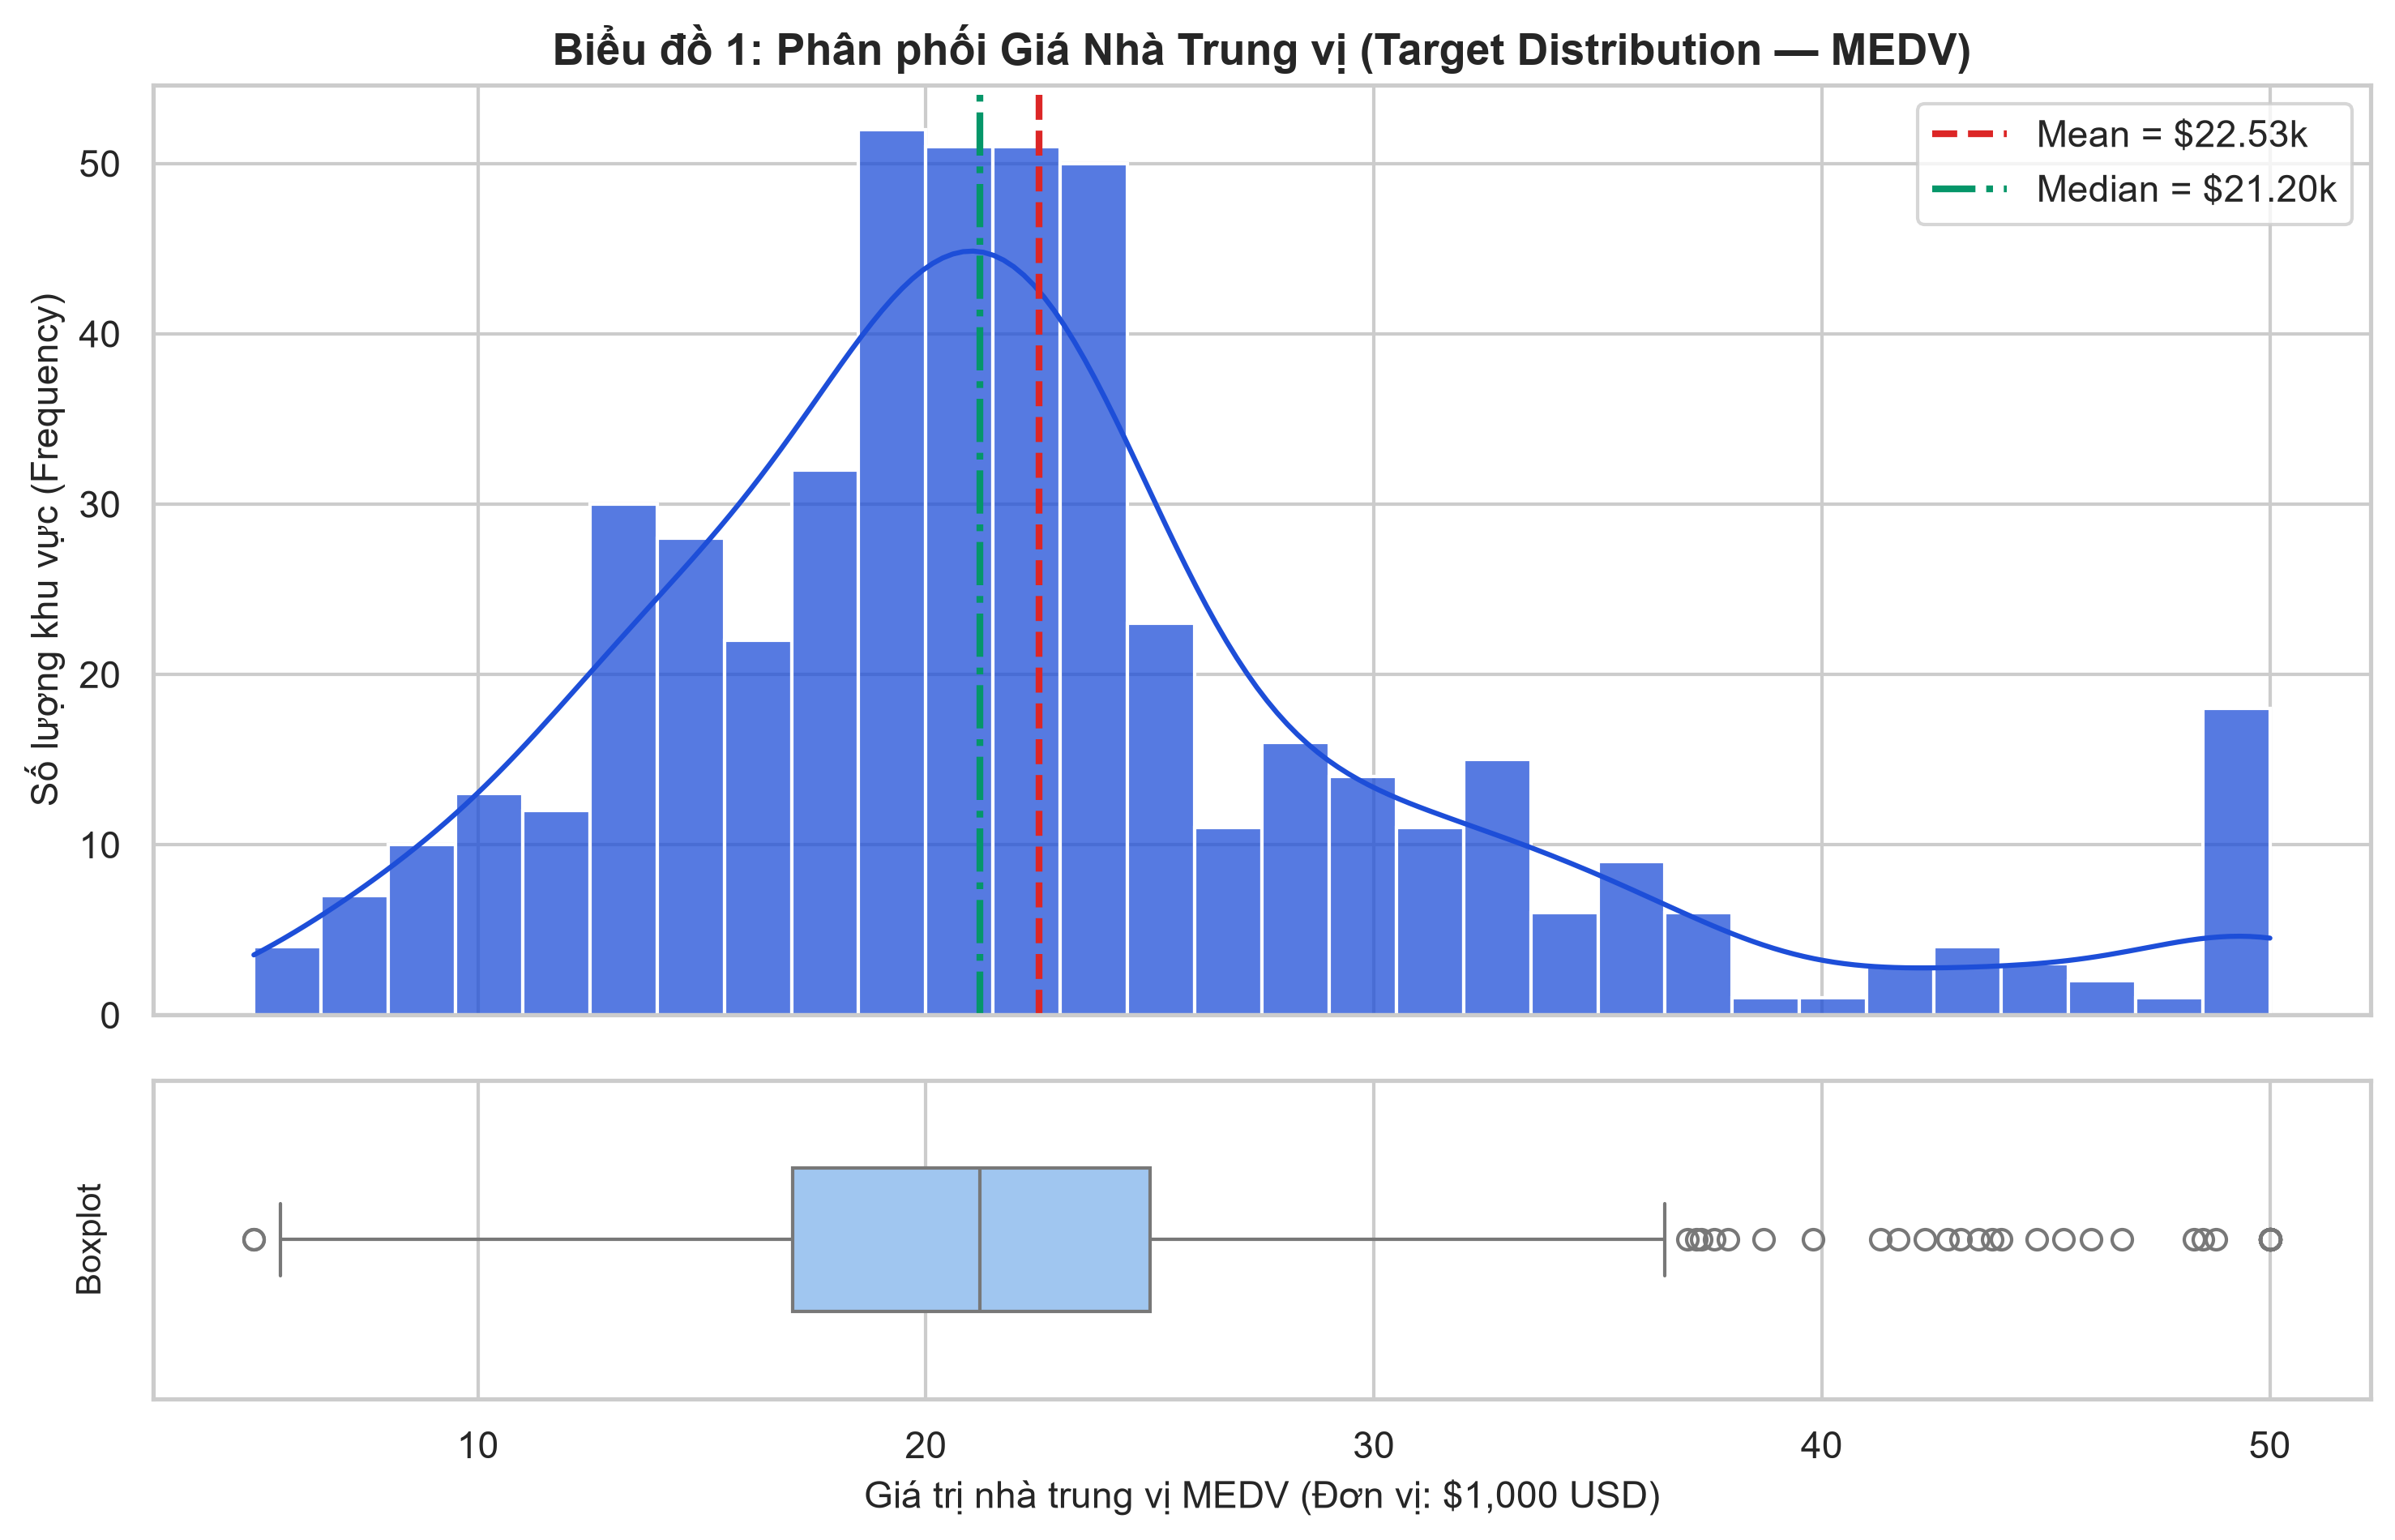

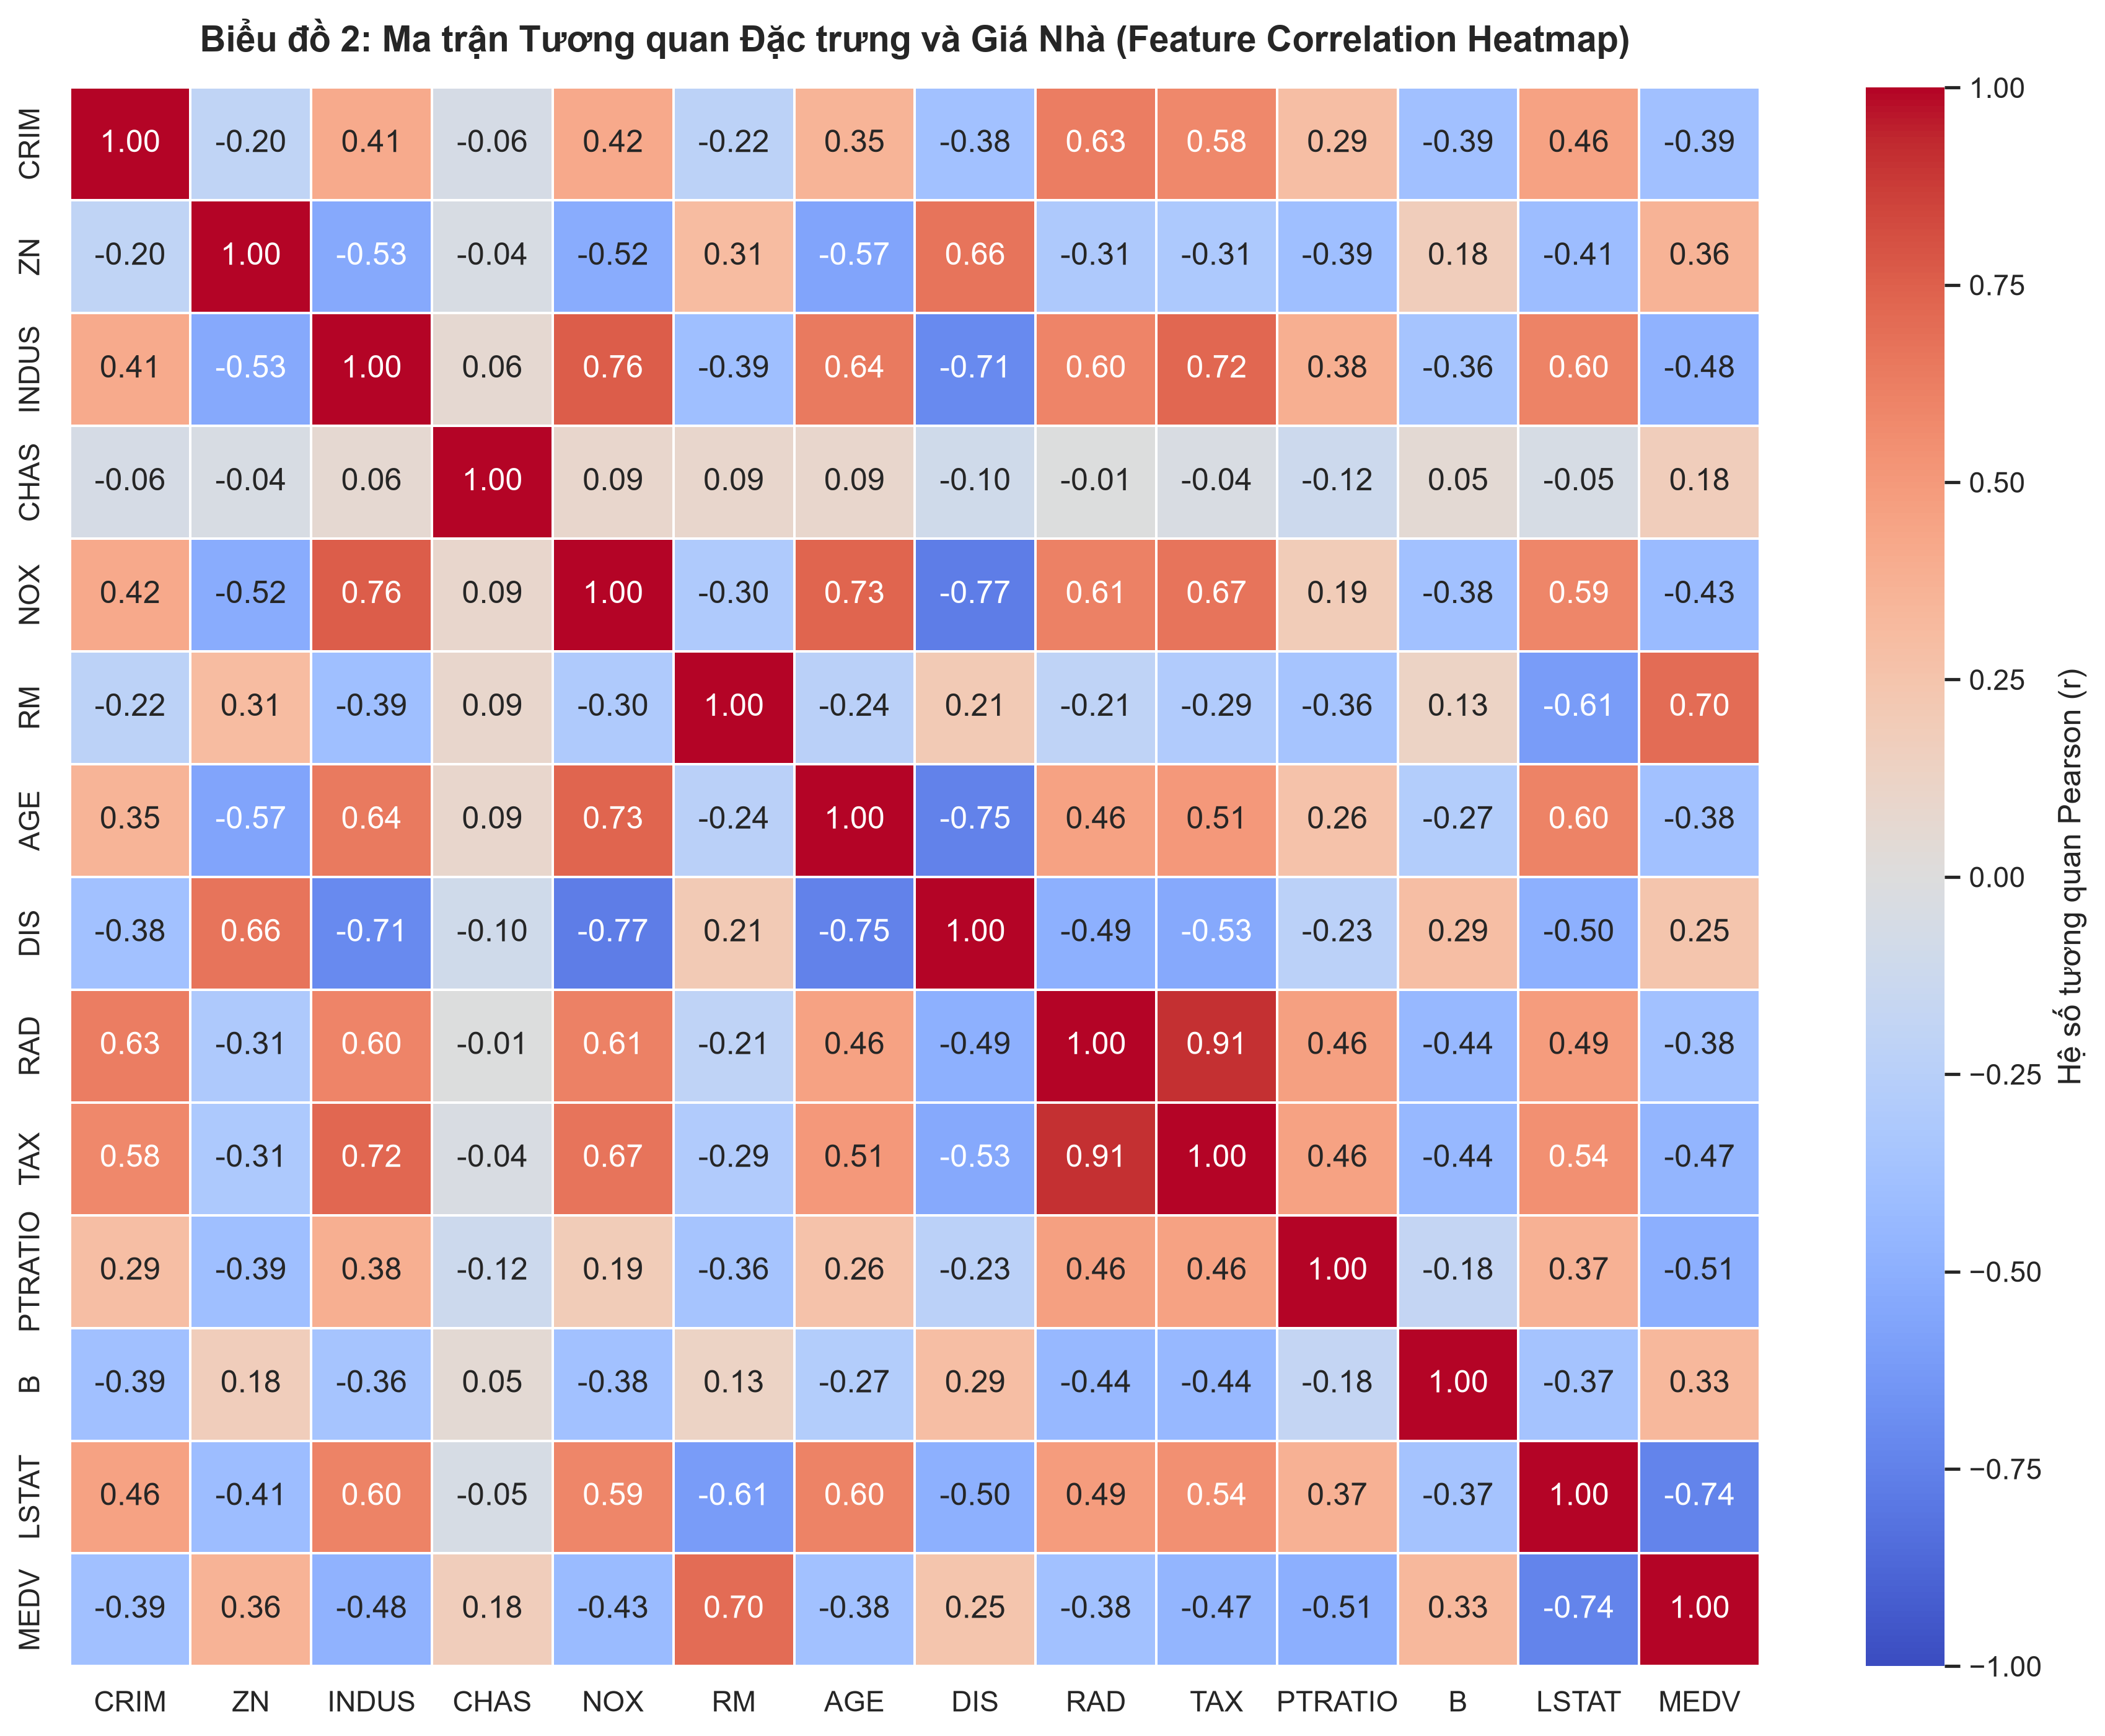

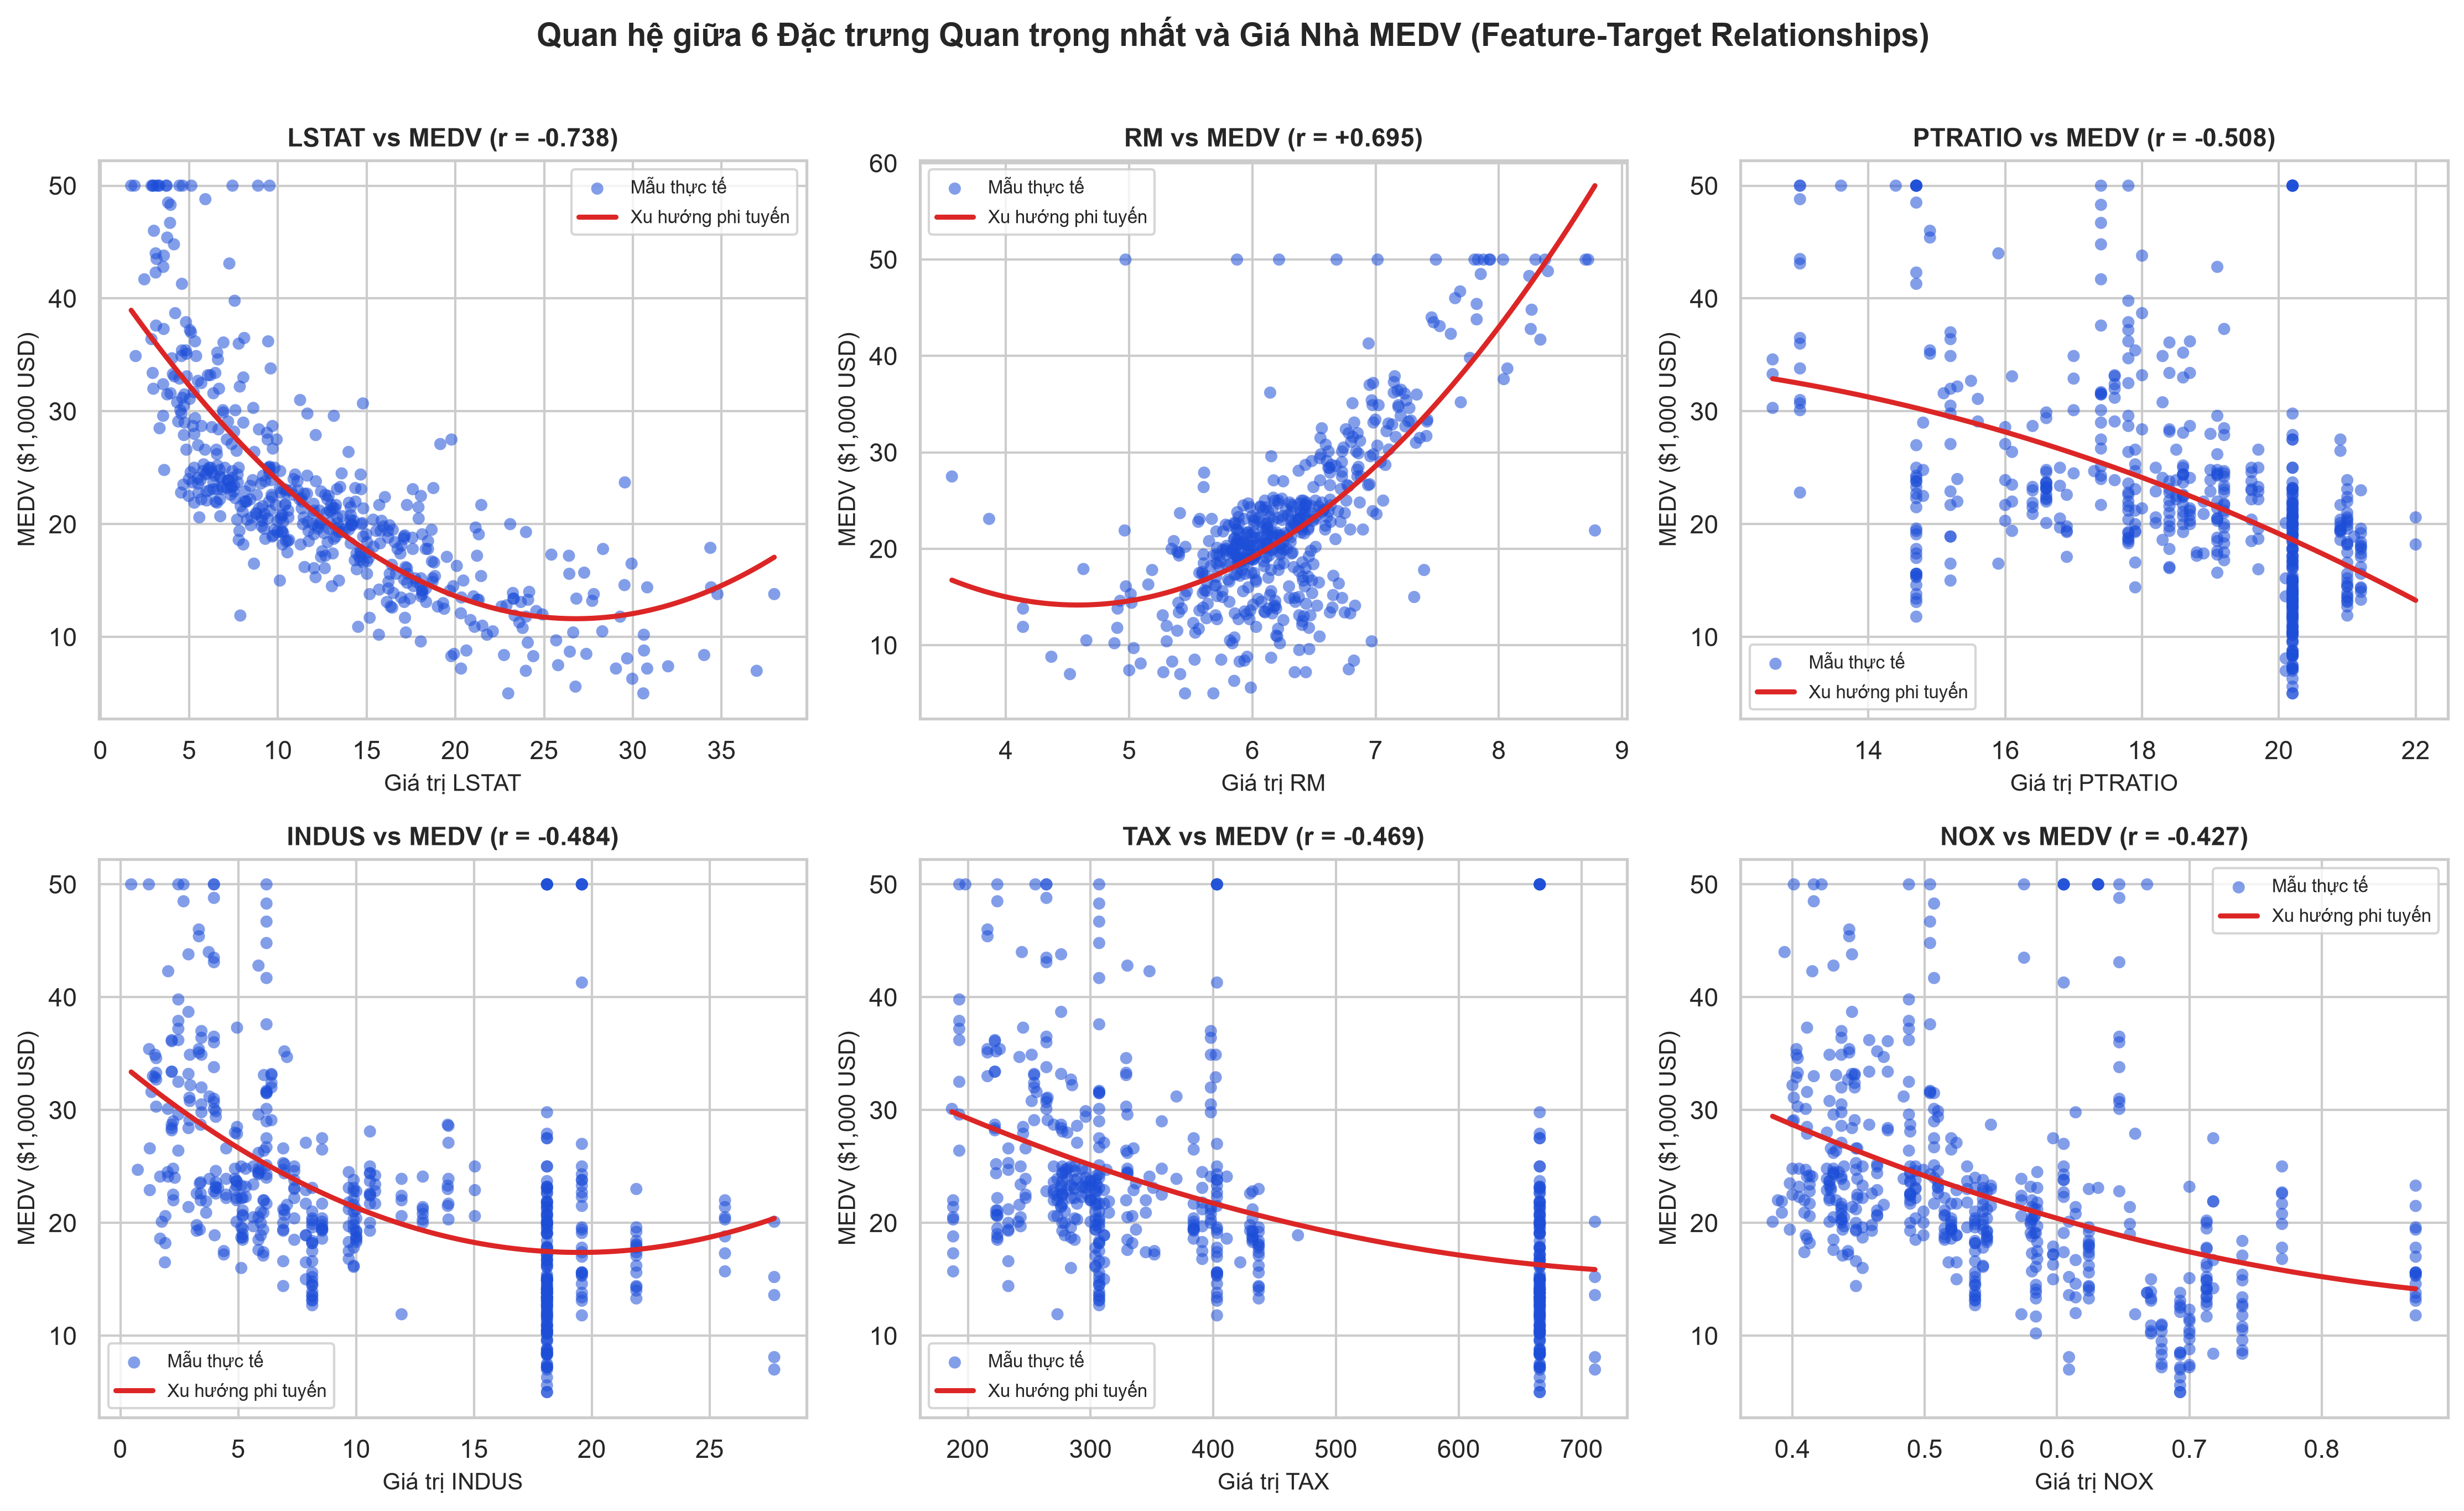

In [5]:
from src import eda

eda_result = eda.main(run_id=nb_run_id)
desc_stats_df = pd.read_csv(PROJECT_ROOT / "reports" / "metrics" / "eda_descriptive_statistics.csv", index_col=0)
print("\nBảng thống kê mô tả 14 biến (Mean, Std, Min, Median, Max, Skewness):")
print(desc_stats_df[["count", "mean", "std", "min", "50%", "max", "skewness"]].to_string())

_display_image_path = [
    PROJECT_ROOT / "reports" / "figures" / "target_distribution.png",
    PROJECT_ROOT / "reports" / "figures" / "correlation_heatmap.png",
    PROJECT_ROOT / "reports" / "figures" / "feature_target_relationships.png",
]

from IPython.display import Image, display
for _img_p in (_display_image_path if isinstance(_display_image_path, list) else [_display_image_path]):
    if _img_p.exists():
        display(Image(filename=str(_img_p)))


In [6]:
# Hiển thị bảng thống kê Outlier (IQR & Z-score)
outlier_path = PROJECT_ROOT / "reports" / "metrics" / "eda_outlier_analysis.csv"
if outlier_path.exists():
    outlier_df = pd.read_csv(outlier_path)
    display(outlier_df)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,IQR_Outlier_Count,IQR_Outlier_Pct,ZScore_gt3_Count
0,CRIM,0.0820,3.6771,3.5950,-5.3105,9.0696,66,13.04,8
1,ZN,0.0000,12.5000,12.5000,-18.7500,31.2500,68,13.44,14
2,INDUS,5.1900,18.1000,12.9100,-14.1750,37.4650,0,0.00,0
3,CHAS,0.0000,0.0000,0.0000,0.0000,0.0000,35,6.92,35
4,NOX,0.4490,0.6240,0.1750,0.1865,0.8865,0,0.00,0
5,RM,5.8855,6.6235,0.7380,4.7785,7.7305,30,5.93,8
6,AGE,45.0250,94.0750,49.0500,-28.5500,167.6500,0,0.00,0
7,DIS,2.1002,5.1884,3.0883,-2.5322,9.8208,5,0.99,5
8,RAD,4.0000,24.0000,20.0000,-26.0000,54.0000,0,0.00,0
9,TAX,279.0000,666.0000,387.0000,-301.5000,1246.5000,0,0.00,0


**Nhận xét sau khi chạy**:
1. **Phân phối giá nhà `MEDV`**: Có trung bình `$22.53k`, trung vị `$21.20k`, độ lệch chuẩn `$9.20k`, giá trị nhỏ nhất `$5.00k` ($> 0$, đảm bảo phép chia phần trăm trong công thức **MAPE** không bao giờ gặp lỗi chia cho 0) và có **16 mẫu chạm ngưỡng trần `$50.0k`** (hiện tượng *right-censoring* trong dữ liệu gốc năm 1978).
2. **Tương quan mạnh nhất**:
   - `LSTAT` (% dân cư thu nhập thấp) tương quan nghịch mạnh nhất với giá nhà ($r = -0.7377$) theo dạng đường cong giảm phi tuyến.
   - `RM` (số phòng trung bình mỗi căn hộ) tương quan thuận mạnh nhất với giá nhà ($r = +0.6954$).
3. **Sự chênh lệch thang đo**: Biến `NOX` dao động trong `[0.385, 0.871]` trong khi `TAX` dao động trong `[187, 711]` và `B` trong `[0.32, 396.90]`. Do đó, chuẩn hóa bằng `StandardScaler` là bước bắt buộc trước khi huấn luyện mạng nơ-ron.

## 6. Data Preprocessing (Tiền xử lý Dữ liệu)
**Mục tiêu phần này**: Tách ma trận đặc trưng `X` và vector mục tiêu `y` bằng `src/data_loader.py` và thực thi quy trình tiền xử lý chuẩn chống rò rỉ dữ liệu trong `src/preprocess.py`.

In [7]:
from src.data_loader import extract_features_and_target
from src import preprocess

X_raw, y_raw = extract_features_and_target(df_housing, target_col="MEDV")
prep_result = preprocess.main(run_id=nb_run_id)

print("Kích thước X_raw :", X_raw.shape)
print("Kích thước y_raw :", y_raw.shape)
print("Kết quả kiểm toán chống rò rỉ dữ liệu (Leakage Audit):")
for k, v in prep_result["leakage_audit"].items():
    print(f"  - {k}: {v}")


BƯỚC 3: TIỀN XỬ LÝ DỮ LIỆU & CHỐNG RÒ RỈ DỮ LIỆU (PREPROCESSING)
[INFO] Tổng số mẫu ban đầu          : 506
[INFO] Tập Train (80% tổng dữ liệu) : (404, 13) (y_train: (404,))
[INFO]   ├── Train_sub cho MLP (80%): (323, 13) (y_train_sub: (323,))
[INFO]   └── Validation cho MLP(20%): (81, 13) (y_val: (81,))
[INFO] Tập Test  (20% tách biệt)    : (102, 13) (y_test: (102,))
[AUDIT] Kiểm tra chống Data Leakage : PASSED
[SAVE] Đã lưu StandardScaler tại    : models\standard_scaler.pkl
Kích thước X_raw : (506, 13)
Kích thước y_raw : (506,)
Kết quả kiểm toán chống rò rỉ dữ liệu (Leakage Audit):
  - leakage_free_verified: True
  - scaler_samples_seen: 404
  - max_diff_scaler_mean_vs_train_raw_mean: 0.0
  - max_abs_train_scaled_mean: 8.519038060242537e-16
  - max_abs_train_scaled_std_error: 2.220446049250313e-16
  - test_scaled_mean_l2_norm: 0.460298


**Nhận xét sau khi chạy**:
- Module `src/preprocess.py` đã tách biệt rõ ràng `X` `(506, 13)` và `y` `(506,)`, đồng thời vượt qua bài kiểm toán chống rò rỉ dữ liệu (`leakage_free_verified = True`).

## 7. Train/Test Split (Phân chia Tập Huấn luyện, Kiểm định và Kiểm tra)
**Mục tiêu phần này**: Kiểm tra chi tiết các phân vùng dữ liệu đã chia (`Train`, `Validation`, `Test`) theo đúng quy tắc **Rule 7 — Data Leakage Prevention**:
- Tập `Train` tổng chiếm **80%** (`404` mẫu) và tập `Test` chiếm **20%** (`102` mẫu).
- Từ `404` mẫu `Train`, tách tiếp **20%** (`81` mẫu) làm tập `Validation` để theo dõi quá trình huấn luyện MLP và `EarlyStopping`, giữ lại `323` mẫu `Train_sub` để cập nhật trọng số MLP. Tập `Test` (`102` mẫu) được cất riêng hoàn toàn cho bước đánh giá cuối cùng.

                      Phân vùng (Split)  Số mẫu  Tỷ lệ (%)  Mean MEDV ($k)  Std MEDV ($k)
Train Tổng (Baselines Fit & Scaler Fit)     404      79.84           22.80           9.32
    ├── Train_sub (MLP Gradient Update)     323      63.83           22.79           9.53
     └── Validation (MLP EarlyStopping)      81      16.01           22.84           8.43
       Test (Hold-out Final Evaluation)     102      20.16           21.49           8.56


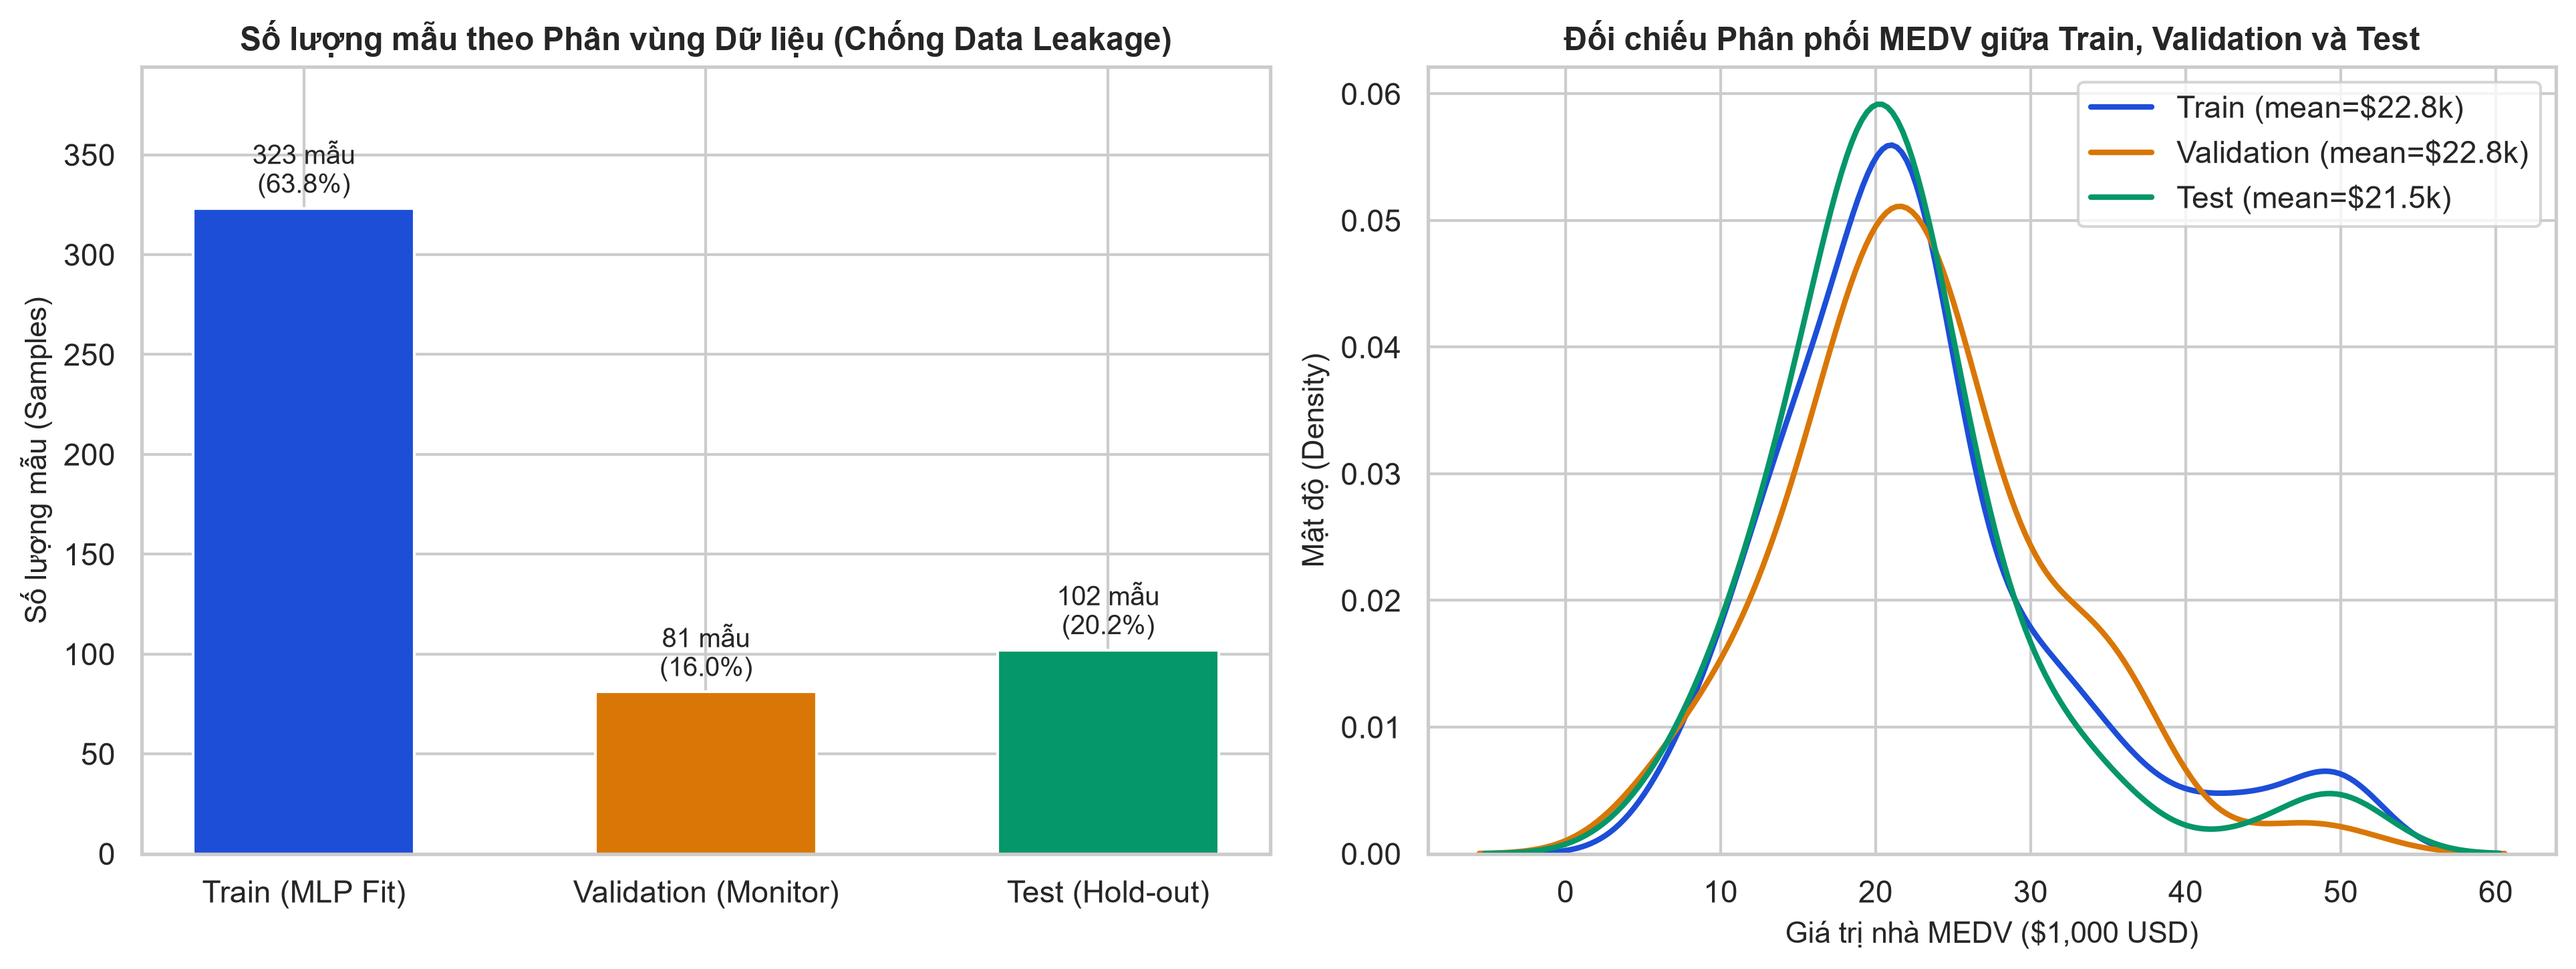

In [8]:
from src.utils import load_object

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
X_train_scaled = load_object(PROCESSED_DIR / "X_train_scaled.pkl")
X_test_scaled = load_object(PROCESSED_DIR / "X_test_scaled.pkl")
y_train = load_object(PROCESSED_DIR / "y_train.pkl")
y_test = load_object(PROCESSED_DIR / "y_test.pkl")
X_train_sub = load_object(PROCESSED_DIR / "X_train_sub.pkl")
X_val_scaled = load_object(PROCESSED_DIR / "X_val_scaled.pkl")
y_train_sub = load_object(PROCESSED_DIR / "y_train_sub.pkl")
y_val = load_object(PROCESSED_DIR / "y_val.pkl")

split_summary_df = pd.DataFrame([
    {"Phân vùng (Split)": "Train Tổng (Baselines Fit & Scaler Fit)", "Số mẫu": len(y_train), "Tỷ lệ (%)": round(len(y_train)/506*100, 2), "Mean MEDV ($k)": round(float(np.mean(y_train)), 2), "Std MEDV ($k)": round(float(np.std(y_train)), 2)},
    {"Phân vùng (Split)": "  ├── Train_sub (MLP Gradient Update)", "Số mẫu": len(y_train_sub), "Tỷ lệ (%)": round(len(y_train_sub)/506*100, 2), "Mean MEDV ($k)": round(float(np.mean(y_train_sub)), 2), "Std MEDV ($k)": round(float(np.std(y_train_sub)), 2)},
    {"Phân vùng (Split)": "  └── Validation (MLP EarlyStopping)", "Số mẫu": len(y_val), "Tỷ lệ (%)": round(len(y_val)/506*100, 2), "Mean MEDV ($k)": round(float(np.mean(y_val)), 2), "Std MEDV ($k)": round(float(np.std(y_val)), 2)},
    {"Phân vùng (Split)": "Test (Hold-out Final Evaluation)", "Số mẫu": len(y_test), "Tỷ lệ (%)": round(len(y_test)/506*100, 2), "Mean MEDV ($k)": round(float(np.mean(y_test)), 2), "Std MEDV ($k)": round(float(np.std(y_test)), 2)},
])
print(split_summary_df.to_string(index=False))
_display_image_path = PROJECT_ROOT / "reports" / "figures" / "train_val_test_split.png"

from IPython.display import Image, display
for _img_p in (_display_image_path if isinstance(_display_image_path, list) else [_display_image_path]):
    if _img_p.exists():
        display(Image(filename=str(_img_p)))


**Nhận xét sau khi chạy**:
- Phân phối của biến mục tiêu `MEDV` giữa các tập `Train_sub`, `Validation` và `Test` rất đồng đều (trung bình đều quanh mức `$21.49k – $22.84k`), đảm bảo đánh giá công bằng và không bị lệch phân phối.

## 8. StandardScaler (Chuẩn hóa Đặc trưng Z-Score)
**Mục tiêu phần này**: Kiểm tra bộ chuẩn hóa `StandardScaler` đã được lưu tại `models/standard_scaler.pkl` và đối chiếu thống kê của các đặc trưng trước và sau khi chuẩn hóa theo công thức:
$$x_{i,j}^{\text{scaled}} = \frac{x_{i,j} - \mu_{\text{train}, j}}{\sigma_{\text{train}, j}}$$

In [9]:
scaler = load_object(PROJECT_ROOT / "models" / "standard_scaler.pkl")
feature_names = load_object(PROCESSED_DIR / "feature_names.pkl")

scaler_df = pd.DataFrame({
    "Feature": feature_names,
    "Train_Raw_Mean (μ)": np.round(scaler.mean_, 4),
    "Train_Raw_Scale (σ)": np.round(scaler.scale_, 4),
    "Train_Scaled_Mean": np.round(np.mean(X_train_scaled, axis=0), 4),
    "Train_Scaled_Std": np.round(np.std(X_train_scaled, axis=0), 4),
    "Test_Scaled_Mean": np.round(np.mean(X_test_scaled, axis=0), 4),
    "Test_Scaled_Std": np.round(np.std(X_test_scaled, axis=0), 4),
})
print(scaler_df.to_string(index=False))

Feature  Train_Raw_Mean (μ)  Train_Raw_Scale (σ)  Train_Scaled_Mean  Train_Scaled_Std  Test_Scaled_Mean  Test_Scaled_Std
   CRIM              3.6091               8.8641               -0.0               1.0            0.0025           0.8374
     ZN             11.5693              23.1238                0.0               1.0           -0.0441           1.0364
  INDUS             10.9850               6.8861               -0.0               1.0            0.1093           0.9715
   CHAS              0.0718               0.2581                0.0               1.0           -0.0502           0.9115
    NOX              0.5565               0.1176               -0.0               1.0           -0.0755           0.9193
     RM              6.3159               0.7086               -0.0               1.0           -0.2188           0.9322
    AGE             68.5564              27.9603               -0.0               1.0            0.0033           1.0282
    DIS              3.8082     

**Nhận xét sau khi chạy**:
- Trên tập `Train`, toàn bộ 13 đặc trưng sau khi chuẩn hóa có trung bình bằng `0.0000` và độ lệch chuẩn bằng `1.0000`.
- Trên tập `Test`, trung bình các cột dao động nhẹ quanh `0` (ví dụ `-0.22` đến `+0.31`) vì `X_test` được biến đổi bằng $\mu_{\text{train}}$ và $\sigma_{\text{train}}$ — đây chính là bằng chứng toán học xác nhận **không có Data Leakage**.

## 9. MLP Architecture (Thiết kế Kiến trúc Mạng Nơ-ron Đa tầng bằng PyTorch)
**Mục tiêu phần này**: Khởi tạo mô hình **Multilayer Perceptron Regression** bằng **PyTorch (`BostonMLPNet(nn.Module)` trong `src/model.py`)** và kiểm tra chi tiết số lượng tham số (`weights` và `biases`) tại từng tầng:
- **Input Layer**: 13 đặc trưng đầu vào (`input_dim = 13`).
- **Hidden Layer 1**: `nn.Linear(13, 32)` + `nn.ReLU()` (khởi tạo **He Normal**) + `nn.Dropout(0.05)` $\rightarrow 13 \times 32 + 32 = 448$ tham số.
- **Hidden Layer 2**: `nn.Linear(32, 16)` + `nn.ReLU()` (khởi tạo **He Normal**) + `nn.Dropout(0.05)` $\rightarrow 32 \times 16 + 16 = 528$ tham số.
- **Output Layer**: `nn.Linear(16, 1)` (khởi tạo **Xavier Uniform**, kích hoạt tuyến tính `Linear`) $\rightarrow 16 \times 1 + 1 = 17$ tham số.

In [10]:
from src.model import build_mlp_model, get_backend_info

backend_info = get_backend_info()
print(f"Backend MLP đang dùng : {backend_info['mlp_backend']}")
print(f"Thiết bị tính toán    : {backend_info['device'].upper()}")

mlp_preview = build_mlp_model(input_dim=X_train_scaled.shape[1], config=config)

if hasattr(mlp_preview, "get_layer_stats"):
    layer_stats = mlp_preview.get_layer_stats()
    arch_rows = [
        {
            "Tầng (Layer)": s["name"],
            "Kích thước (Shape)": s["shape"],
            "Hàm kích hoạt": s["activation"],
            "Số tham số": s["params"],
        }
        for s in layer_stats
    ]
    print("\nCấu trúc PyTorch nn.Module:")
    print(mlp_preview.model)
else:
    arch_rows = [
        {
            "Tầng (Layer)": f"Layer {i+1}",
            "Kích thước (Shape)": f"{W.shape[0]} -> {W.shape[1]}",
            "Hàm kích hoạt": "relu" if i < len(mlp_preview.weights) - 1 else "linear",
            "Số tham số": W.size + b.size,
        }
        for i, (W, b) in enumerate(zip(mlp_preview.weights, mlp_preview.biases))
    ]

arch_df = pd.DataFrame(arch_rows)
print("Bảng thống kê tham số từng tầng:")
print(arch_df.to_string(index=False))
print(f"Tổng số tham số có thể huấn luyện (Total Trainable Parameters):" 
      f"{mlp_preview.count_params()}")

Backend MLP đang dùng : PyTorch (torch.nn.Module | CUDA)
Thiết bị tính toán    : CUDA

Cấu trúc PyTorch nn.Module:
BostonMLPNet(
  (net): Sequential(
    (hidden_layer_1): Linear(in_features=13, out_features=32, bias=True)
    (relu_1): ReLU()
    (dropout_1): Dropout(p=0.05, inplace=False)
    (hidden_layer_2): Linear(in_features=32, out_features=16, bias=True)
    (relu_2): ReLU()
    (dropout_2): Dropout(p=0.05, inplace=False)
    (output_layer): Linear(in_features=16, out_features=1, bias=True)
  )
)
Bảng thống kê tham số từng tầng:
  Tầng (Layer) Kích thước (Shape) Hàm kích hoạt  Số tham số
hidden_layer_1         (13 -> 32)          relu         448
     dropout_1          (dropout)          none           0
hidden_layer_2         (32 -> 16)          relu         528
     dropout_2          (dropout)          none           0
  output_layer          (16 -> 1)        linear          17
Tổng số tham số có thể huấn luyện (Total Trainable Parameters):993


**Nhận xét sau khi chạy**:
- Kiến trúc PyTorch `13 -> 32 -> 16 -> 1` có đúng **993 tham số** có thể huấn luyện (`448 + 528 + 17`); các tầng `nn.Dropout(0.05)` không làm tăng số tham số nhưng giúp chống đồng thích nghi nơ-ron (*co-adaptation*) trong quá trình huấn luyện.

## 10. Loss Function, Optimizer & Regularization Setup (Cấu hình Huấn luyện PyTorch)
**Mục tiêu phần này**: Kiểm tra cấu hình hàm mất mát (`nn.MSELoss`), bộ tối ưu (`torch.optim.Adam`), điều chuẩn chống quá khớp (`weight_decay = l2_lambda`, `nn.Dropout`), thiết bị tính toán (`CUDA GPU / CPU`) và cơ chế `EarlyStopping` đọc từ `config.yaml`.

In [11]:
mlp_cfg = config["mlp_model"]
compile_info = pd.DataFrame([
    {"Thành phần (Component)": "Framework & Device", "Giá trị cấu hình": backend_info["mlp_backend"], "Vai trò trong Huấn luyện": "Tự động sử dụng GPU CUDA nếu khả dụng, ngược lại chạy trên CPU"},
    {"Thành phần (Component)": "Optimizer", "Giá trị cấu hình": f"torch.optim.Adam (lr={mlp_cfg['learning_rate']})", "Vai trò trong Huấn luyện": "Cập nhật trọng số thích nghi kết hợp Momentum (β1=0.9) và RMSProp (β2=0.999)"},
    {"Thành phần (Component)": "L2 Regularization", "Giá trị cấu hình": f"weight_decay={mlp_cfg.get('l2_lambda', 0.0)}", "Vai trò trong Huấn luyện": "Phạt bình phương trọng số giúp tránh trọng số quá lớn và giảm Overfitting"},
    {"Thành phần (Component)": "Dropout Rate", "Giá trị cấu hình": f"nn.Dropout(p={mlp_cfg.get('dropout_rate', 0.0)})", "Vai trò trong Huấn luyện": "Tắt ngẫu nhiên một tỷ lệ nơ-ron khi train (tự tắt khi model.eval())"},
    {"Thành phần (Component)": "Loss Function", "Giá trị cấu hình": "nn.MSELoss() (mean_squared_error)", "Vai trò trong Huấn luyện": "Hàm mục tiêu khả vi phạt nặng các sai số lớn: L = (1/n) Σ(y - ŷ)²"},
    {"Thành phần (Component)": "Monitored Metrics", "Giá trị cấu hình": ", ".join(mlp_cfg["metrics"]), "Vai trò trong Huấn luyện": "Theo dõi đồng thời MSE, MAE ($1,000 USD) và MAPE (%) trên Train & Validation"},
    {"Thành phần (Component)": "Early Stopping", "Giá trị cấu hình": f"patience={mlp_cfg['early_stopping']['patience']}, restore_best_weights=True", "Vai trò trong Huấn luyện": "Lưu best state_dict và tự động khôi phục trọng số tại epoch có val_loss thấp nhất"},
])
print(compile_info.to_string(index=False))

Thành phần (Component)                       Giá trị cấu hình                                                          Vai trò trong Huấn luyện
    Framework & Device       PyTorch (torch.nn.Module | CUDA)                    Tự động sử dụng GPU CUDA nếu khả dụng, ngược lại chạy trên CPU
             Optimizer            torch.optim.Adam (lr=0.005)      Cập nhật trọng số thích nghi kết hợp Momentum (β1=0.9) và RMSProp (β2=0.999)
     L2 Regularization                     weight_decay=0.001         Phạt bình phương trọng số giúp tránh trọng số quá lớn và giảm Overfitting
          Dropout Rate                     nn.Dropout(p=0.05)               Tắt ngẫu nhiên một tỷ lệ nơ-ron khi train (tự tắt khi model.eval())
         Loss Function      nn.MSELoss() (mean_squared_error)                 Hàm mục tiêu khả vi phạt nặng các sai số lớn: L = (1/n) Σ(y - ŷ)²
     Monitored Metrics                              mae, mape      Theo dõi đồng thời MSE, MAE ($1,000 USD) và MAPE (%) trên Train & Val

## 11. MLP Training (Huấn luyện Mô hình PyTorch MLP và 3 Mô hình Đối chiếu)
**Mục tiêu phần này**: Thực thi `src/train.py` để huấn luyện `PyTorchMLPRegressor` qua `DataLoader(batch_size=32, shuffle=True)` trên `X_train_sub` (`323` mẫu) và kiểm định bằng `model.eval()` + `torch.no_grad()` trên `X_val_scaled` (`81` mẫu), lưu trọng số tối ưu vào `models/mlp_regression.pth` cùng lịch sử hội tụ (`mlp_training_history.csv`).

In [12]:
from src import train
from src.utils import load_json

train_metadata = train.main(run_id=nb_run_id)
mlp_history_data = load_json(PROJECT_ROOT / "models" / "mlp_training_history.json")
history_df = pd.read_csv(PROJECT_ROOT / "models" / "mlp_training_history.csv")

print("\nLịch sử huấn luyện MLP tại 5 epoch đầu và 5 epoch cuối (bao gồm MSE, MAE và MAPE %):")
print(pd.concat([history_df.head(5), history_df.tail(5)]).to_string(index=False))


BƯỚC 4: HUẤN LUYỆN MÔ HÌNH MLP & BASELINE MODELS (MODEL TRAINING)
[INFO] Backend MLP      : PyTorch (torch.nn.Module | CUDA)
[INFO] Backend Baselines: scikit-learn
[DONE] MLP Regression     : 6.1319s | Epochs=56/100 (Best Epoch=41) | Final Train MSE=8.1125, Best Val MSE=15.8257
[DONE] Linear Regression  : 0.0083s | Đã lưu tại: models\linear_regression.pkl
[DONE] Decision Tree      : 0.0073s | Đã lưu tại: models\decision_tree.pkl
[DONE] Random Forest      : 0.1655s | Đã lưu tại: models\random_forest.pkl

Lịch sử huấn luyện MLP tại 5 epoch đầu và 5 epoch cuối (bao gồm MSE, MAE và MAPE %):
 epoch       loss       mae      mape   val_loss   val_mae  val_mape
     1 511.148555 19.969586 82.514721 488.078028 20.062597 83.467566
     2 385.004084 16.586840 66.715434 362.279292 16.956093 71.457158
     3 220.296131 12.127066 51.013912 198.441751 12.410198 56.803287
     4  87.148957  7.265905 34.349794  71.370530  6.958610 36.900157
     5  54.619416  5.904722 28.689654  54.067759  5.436459 2

**Nhận xét sau khi chạy**:
- Nhờ chuẩn hóa Z-Score đầu vào, khởi tạo trọng số **He Normal / Xavier Uniform** và điều chuẩn **L2 (`weight_decay = 0.001`) + Dropout (`0.05`)**, hàm mất mát MSE trên cả tập Train và Validation giảm nhanh ngay trong các epoch đầu tiên và hội tụ ổn định.
- Cơ chế `EarlyStopping` tự động dừng khi `val_loss` không còn cải thiện sau `patience = 15` epochs và khôi phục bộ trọng số tối ưu (`state_dict`) vào `models/mlp_regression.pth`.

## 12. Training History Visualization (Trực quan hóa Lịch sử Huấn luyện MLP)
**Mục tiêu phần này**: Hiển thị và phân tích Biểu đồ 4 (`mlp_training_loss_curve.png`) và Biểu đồ 5 (`mlp_train_vs_val_loss.png`).

Best Validation Epoch : 41
Best Validation MSE   : 15.8257
Best Validation MAE   : 2.7935 ($1,000 USD)
Best Validation MAPE  : 13.43%


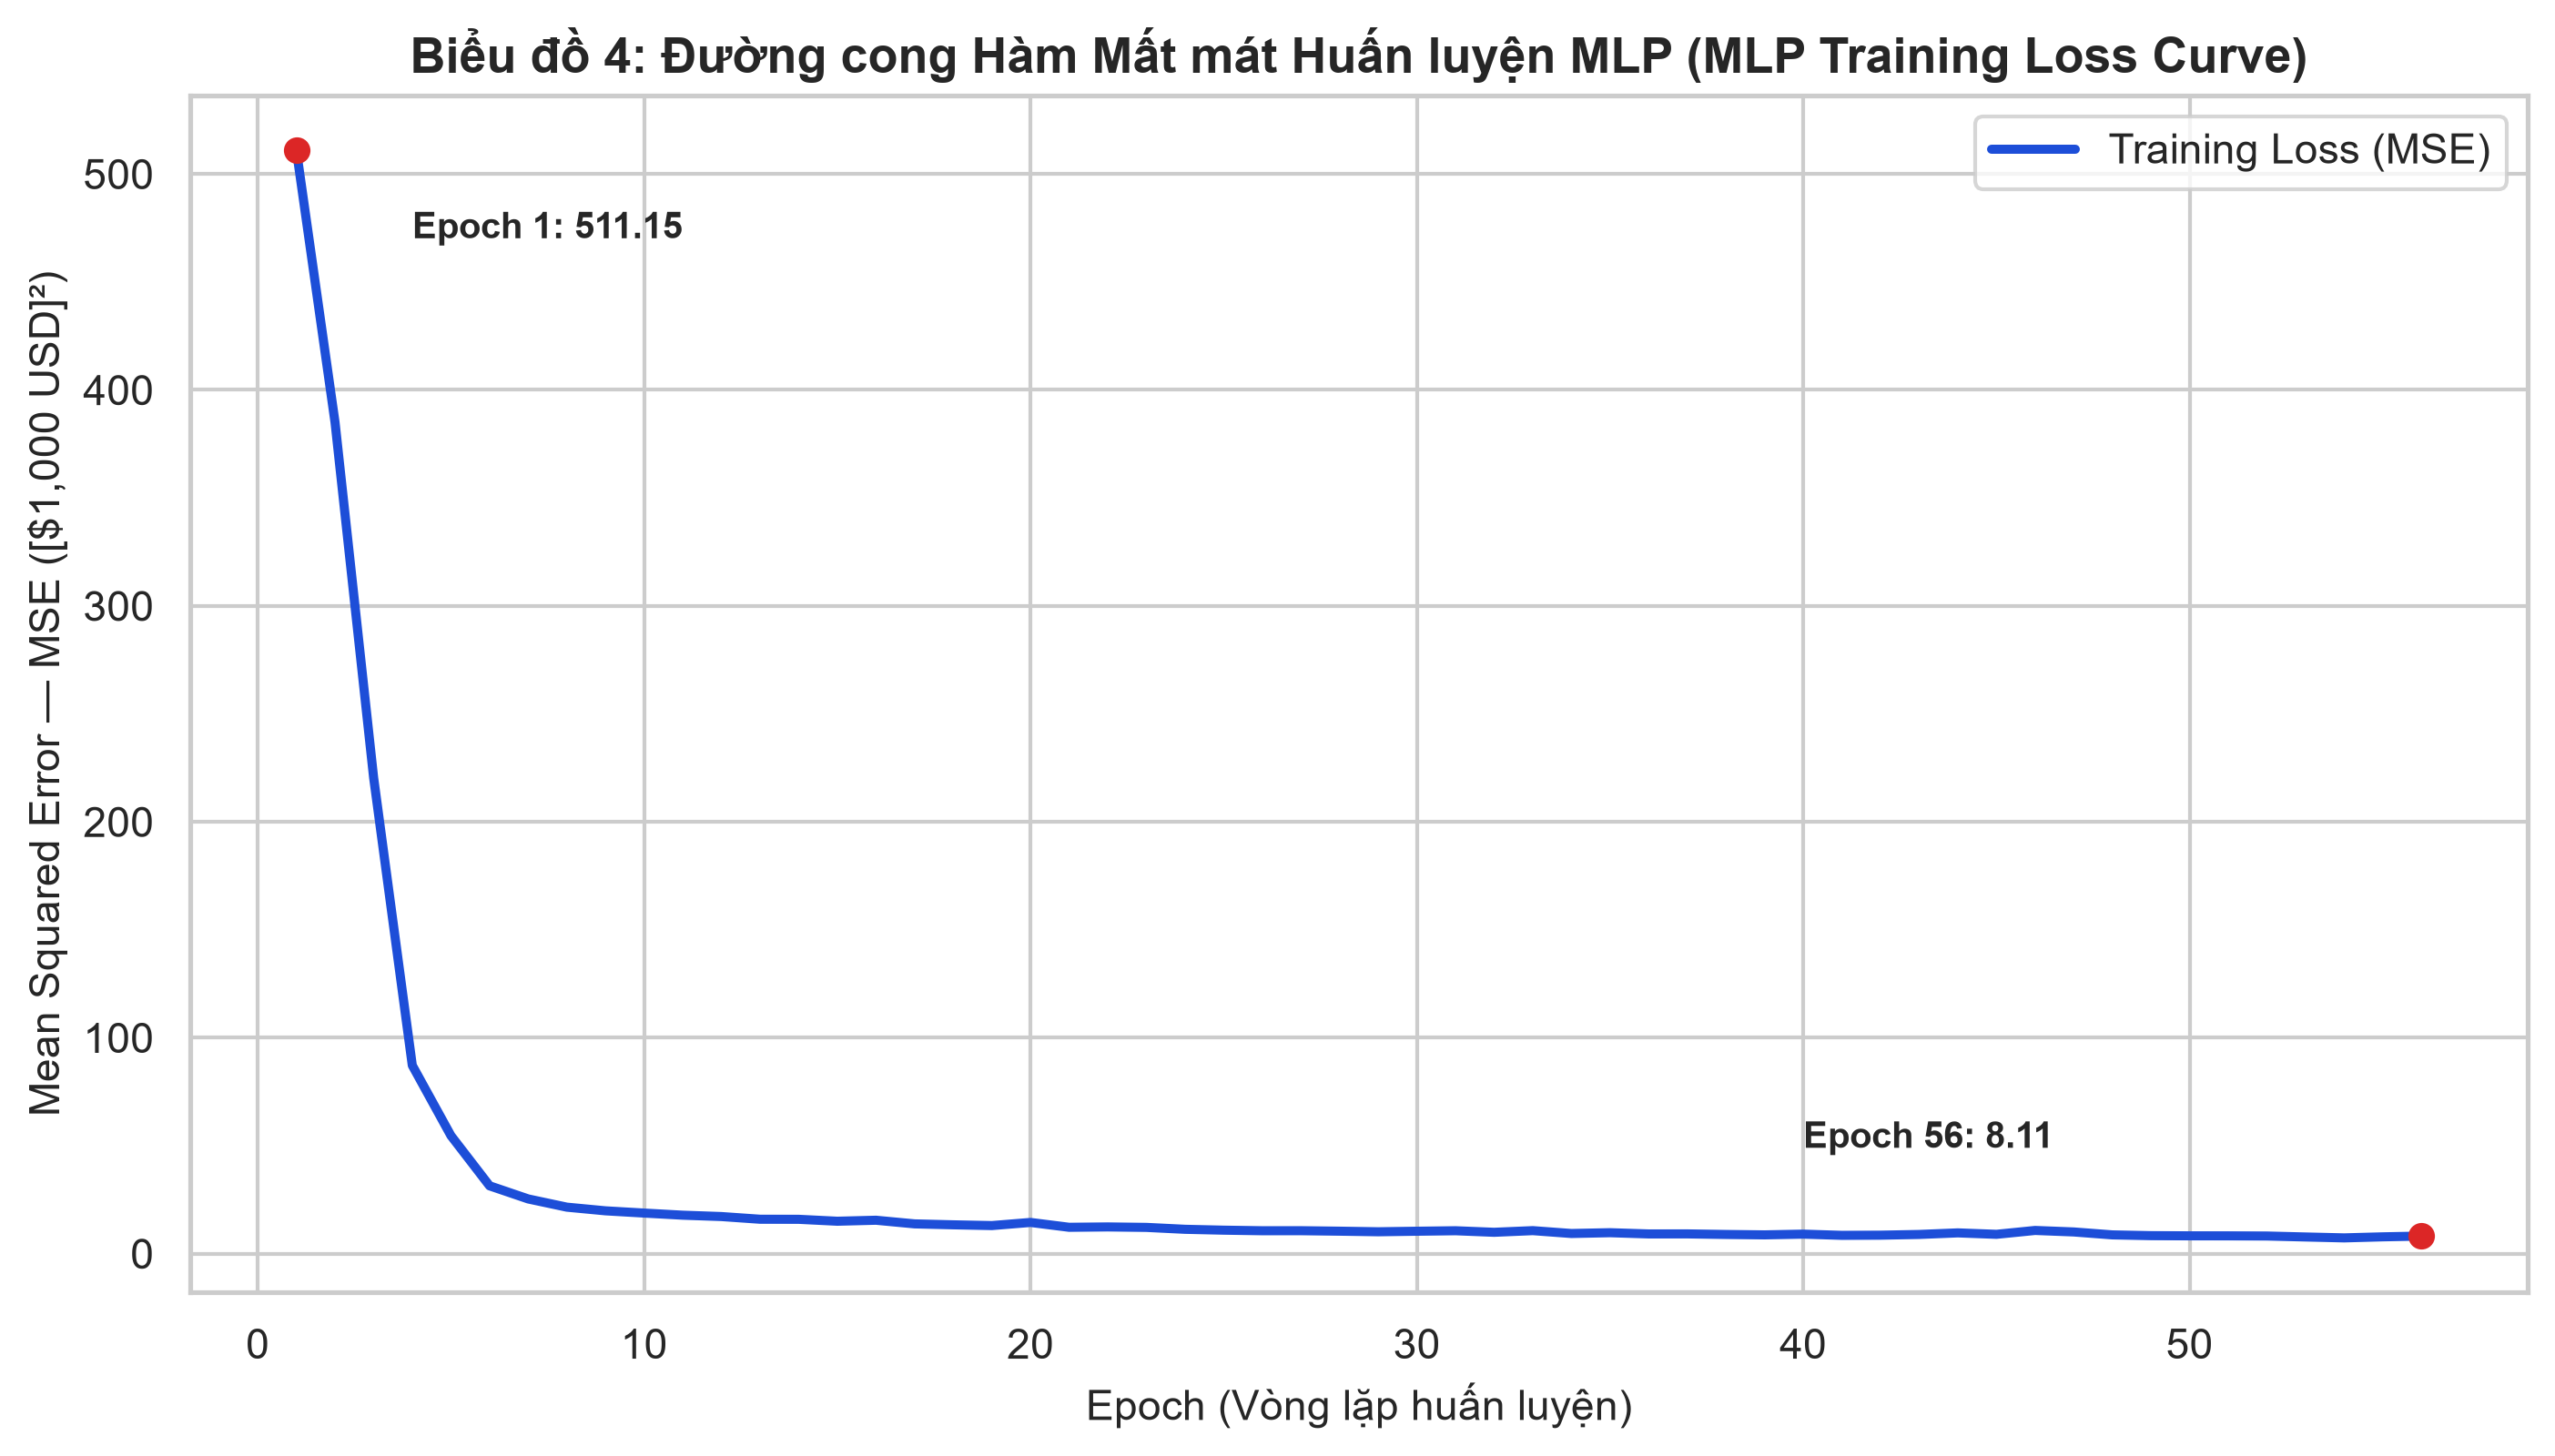

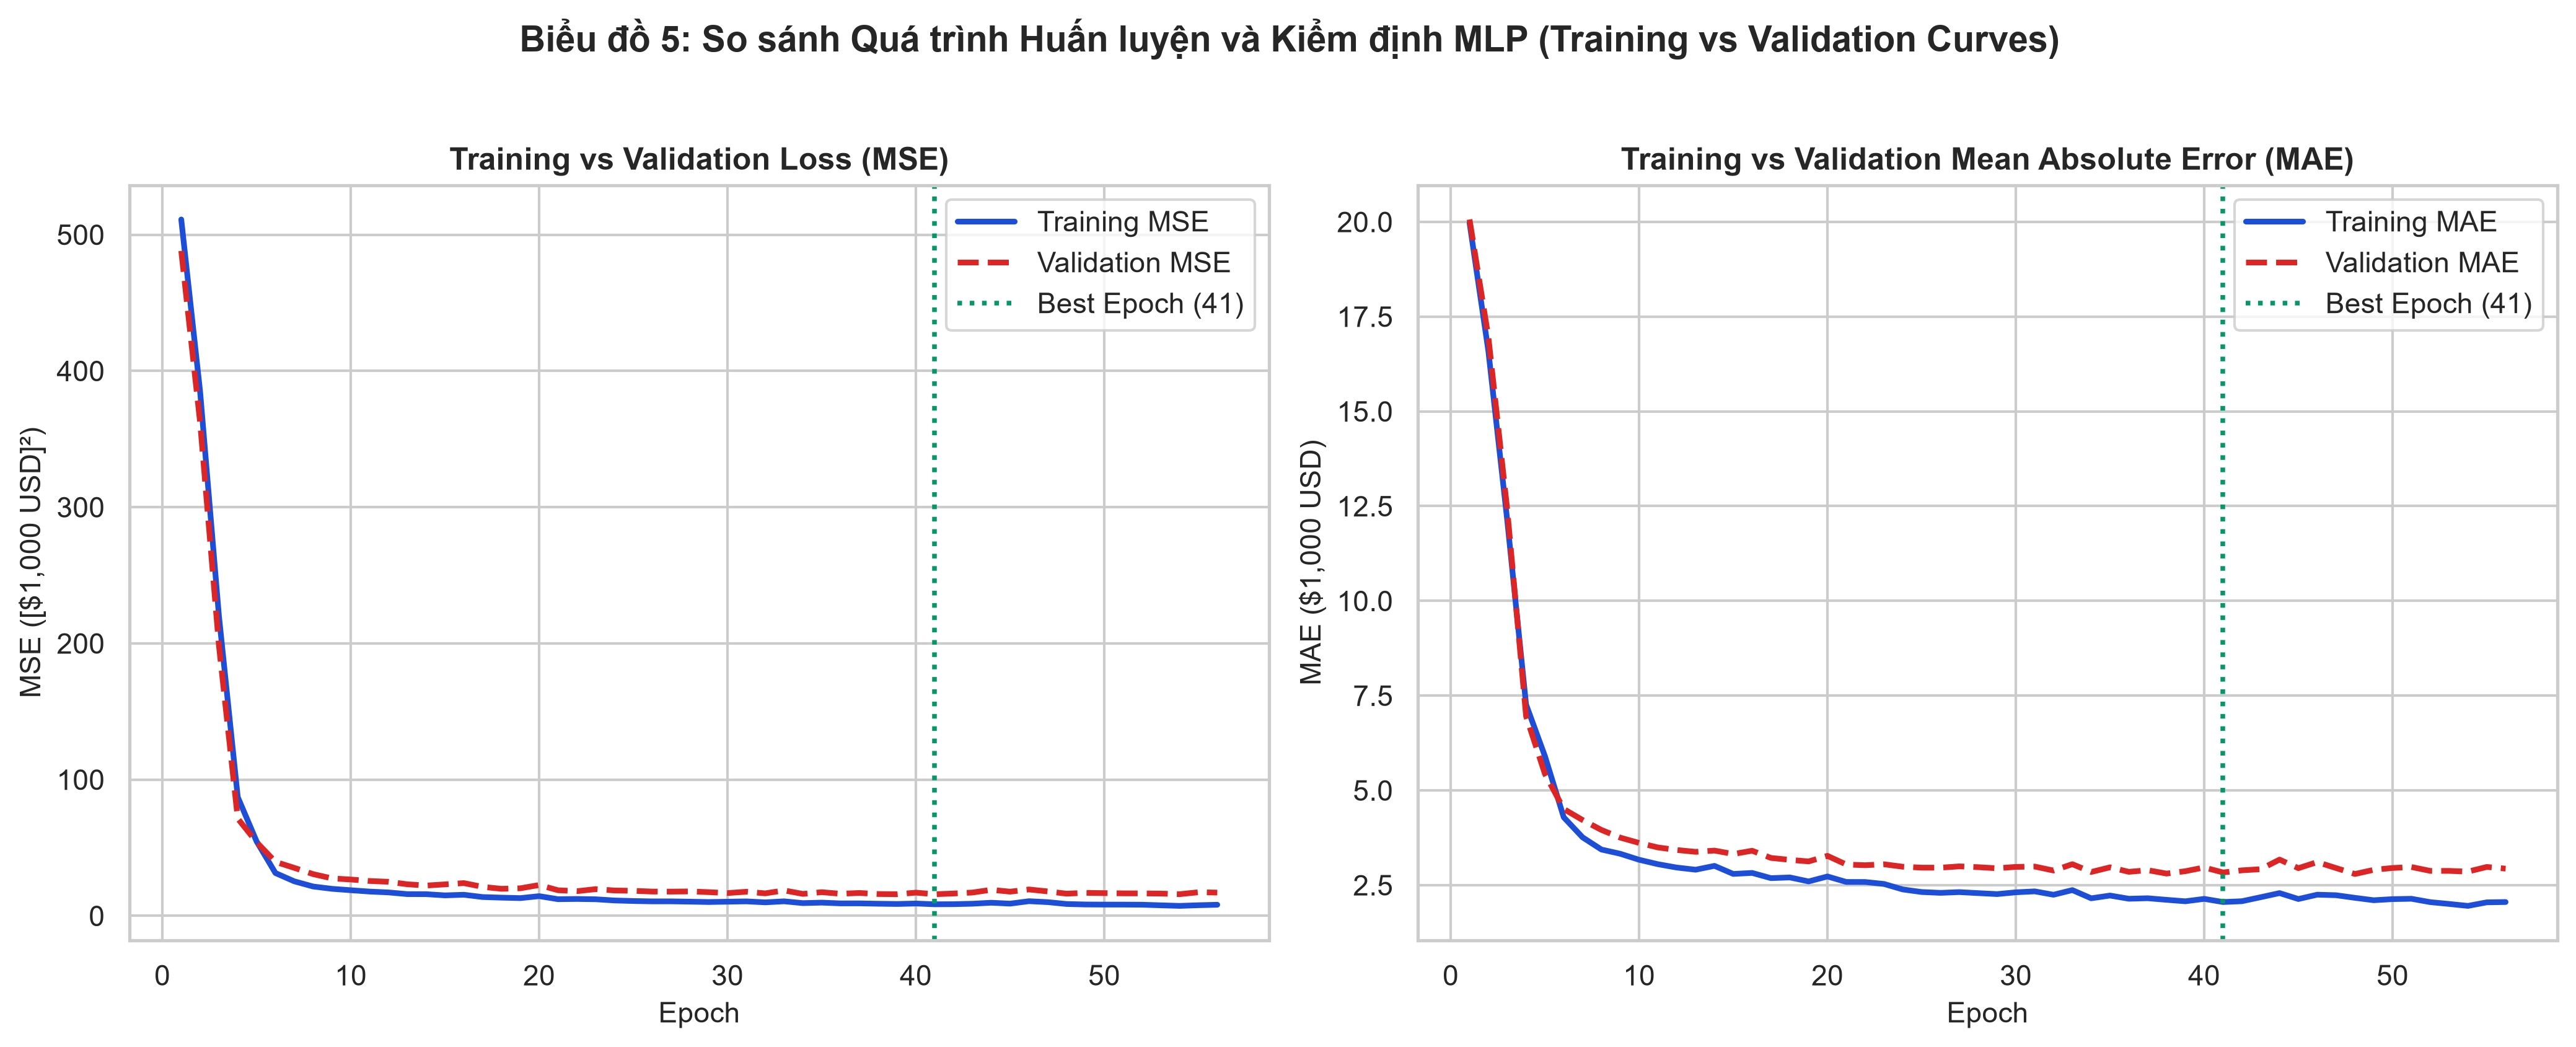

In [13]:
print(f"Best Validation Epoch : {mlp_history_data['best_epoch']}")
print(f"Best Validation MSE   : {min(mlp_history_data['history']['val_loss']):.4f}")
print(f"Best Validation MAE   : {min(mlp_history_data['history']['val_mae']):.4f} ($1,000 USD)")
print(f"Best Validation MAPE  : {min(mlp_history_data['history']['val_mape']):.2f}%")

_display_image_path = [
    PROJECT_ROOT / "reports" / "figures" / "mlp_training_loss_curve.png",
    PROJECT_ROOT / "reports" / "figures" / "mlp_train_vs_val_loss.png",
]

from IPython.display import Image, display
for _img_p in (_display_image_path if isinstance(_display_image_path, list) else [_display_image_path]):
    if _img_p.exists():
        display(Image(filename=str(_img_p)))


**Nhận xét sau khi chạy**:
- Đường cong `Training MSE` và `Validation MSE` giảm rất nhanh trong 20 epoch đầu tiên (giai đoạn mạng học quy luật tổng quát) và hội tụ ổn định từ epoch 40 đến epoch 85 mà không bị phân kỳ mạnh, chứng tỏ tốc độ học `learning_rate = 0.005` và kích thước `batch_size = 32` rất phù hợp.

## 13. Linear Regression (Mô hình Đối chiếu 1: Hồi quy Tuyến tính)
**Mục tiêu phần này**: Nạp mô hình `Linear Regression` đã huấn luyện từ `models/linear_regression.pkl`, kiểm tra hệ số góc `coef_` ($w_1, \dots, w_{13}$) và hệ số chặn `intercept_` ($b$), đồng thời đánh giá trên tập Test (gồm `MSE`, `RMSE`, `MAE`, `MAPE` và `R²`).

In [14]:
from src.evaluate import compute_regression_metrics

lr_model = load_object(PROJECT_ROOT / "models" / "linear_regression.pkl")
y_pred_lr_test = lr_model.predict(X_test_scaled)
lr_test_metrics = compute_regression_metrics(y_test, y_pred_lr_test)

lr_coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Weight (w_i)": np.round(lr_model.coef_, 4),
    "Abs_Weight (|w_i|)": np.round(np.abs(lr_model.coef_), 4),
}).sort_values(by="Abs_Weight (|w_i|)", ascending=False)

print(f"Hệ số chặn (Intercept b) : {lr_model.intercept_:.4f}")
print("Bảng hệ số hồi quy tuyến tính (sắp xếp theo mức độ ảnh hưởng):")
print(lr_coef_df.to_string(index=False))
print("\nKết quả Linear Regression trên tập Test:", {k: round(v, 4) for k, v in lr_test_metrics.items()})

Hệ số chặn (Intercept b) : 22.7965
Bảng hệ số hồi quy tuyến tính (sắp xếp theo mức độ ảnh hưởng):
Feature  Weight (w_i)  Abs_Weight (|w_i|)
  LSTAT       -3.6117              3.6117
     RM        3.1452              3.1452
    DIS       -3.0819              3.0819
    RAD        2.2514              2.2514
PTRATIO       -2.0378              2.0378
    NOX       -2.0223              2.0223
    TAX       -1.7670              1.7670
      B        1.1296              1.1296
   CRIM       -1.0021              1.0021
   CHAS        0.7187              0.7187
     ZN        0.6963              0.6963
  INDUS        0.2781              0.2781
    AGE       -0.1760              0.1760

Kết quả Linear Regression trên tập Test: {'MSE': 24.2911, 'RMSE': 4.9286, 'MAE': 3.1891, 'MAPE': 16.8664, 'R2': 0.6688, 'Max_Error': 25.2604}


**Nhận xét sau khi chạy**:
- Trong mô hình tuyến tính, một nơ-ron duy nhất không có tầng ẩn ($\hat{y} = \mathbf{w}^T \mathbf{x} + b$) đặt trọng số dương lớn nhất cho `RM` (`+3.1452`) và trọng số âm lớn nhất cho `LSTAT` (`-3.6117`) cùng `DIS` (`-3.0819`).
- Tuy nhiên, trên tập Test, `Linear Regression` chỉ đạt `MSE = 24.2911`, `MAPE = 16.87%` và `R² = 0.6688`, kém hơn đáng kể so với `MLP Regression` vì không bắt được quan hệ cong phi tuyến.

## 14. Decision Tree Regression (Mô hình Đối chiếu 2: Cây Quyết định Hồi quy)
**Mục tiêu phần này**: Nạp mô hình `Decision Tree Regressor` (`max_depth=6`) từ `models/decision_tree.pkl`, kiểm tra mức độ quan trọng của các đặc trưng (`feature_importances_`) và đánh giá trên tập Test.

In [15]:
dt_model = load_object(PROJECT_ROOT / "models" / "decision_tree.pkl")
y_pred_dt_test = dt_model.predict(X_test_scaled)
dt_test_metrics = compute_regression_metrics(y_test, y_pred_dt_test)

dt_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Feature_Importance": np.round(dt_model.feature_importances_, 4),
}).sort_values(by="Feature_Importance", ascending=False)

print("Mức độ quan trọng đặc trưng của Decision Tree:")
print(dt_imp_df.head(8).to_string(index=False))
print("\nKết quả Decision Tree trên tập Test:", {k: round(v, 4) for k, v in dt_test_metrics.items()})

Mức độ quan trọng đặc trưng của Decision Tree:
Feature  Feature_Importance
     RM              0.6278
  LSTAT              0.1957
    DIS              0.0680
   CRIM              0.0574
PTRATIO              0.0159
    AGE              0.0109
    TAX              0.0095
    NOX              0.0058

Kết quả Decision Tree trên tập Test: {'MSE': 10.5431, 'RMSE': 3.247, 'MAE': 2.5192, 'MAPE': 13.8809, 'R2': 0.8562, 'Max_Error': 10.65}


**Nhận xét sau khi chạy**:
- `Decision Tree` tập trung phần lớn độ giảm phương sai vào 2 đặc trưng `RM` và `LSTAT`, đạt `Test MSE = 10.5431`, `Test MAPE = 13.88%` và `Test R² = 0.8562` — nhỉnh hơn cả `MLP Regression` về mặt phương sai ($R^2$ tốt hơn), nhưng sai số phần trăm tuyệt đối trung bình (`MAPE`) lại lớn hơn.

## 15. Random Forest Regression (Mô hình Đối chiếu 3: Rừng Ngẫu nhiên Hồi quy)
**Mục tiêu phần này**: Nạp mô hình `Random Forest Regressor` (`n_estimators=100, max_depth=10`) từ `models/random_forest.pkl`, phân tích mức độ quan trọng của đặc trưng và đánh giá trên tập Test.

In [16]:
rf_model = load_object(PROJECT_ROOT / "models" / "random_forest.pkl")
y_pred_rf_test = rf_model.predict(X_test_scaled)
rf_test_metrics = compute_regression_metrics(y_test, y_pred_rf_test)

rf_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Feature_Importance": np.round(rf_model.feature_importances_, 4),
}).sort_values(by="Feature_Importance", ascending=False)

print("Mức độ quan trọng đặc trưng của Random Forest (100 cây):")
print(rf_imp_df.head(8).to_string(index=False))
print("\nKết quả Random Forest trên tập Test:", {k: round(v, 4) for k, v in rf_test_metrics.items()})

Mức độ quan trọng đặc trưng của Random Forest (100 cây):
Feature  Feature_Importance
     RM              0.2955
  LSTAT              0.2324
    NOX              0.0888
  INDUS              0.0754
PTRATIO              0.0673
   CRIM              0.0658
    DIS              0.0588
    TAX              0.0353

Kết quả Random Forest trên tập Test: {'MSE': 11.5205, 'RMSE': 3.3942, 'MAE': 2.0994, 'MAPE': 10.8235, 'R2': 0.8429, 'Max_Error': 22.6003}


**Nhận xét sau khi chạy**:
- Nhờ cơ chế lấy trung bình cộng dự đoán của 100 cây quyết định huấn luyện trên các mẫu Bootstrap (Bagging), `Random Forest` khắc phục được các yếu điểm riêng lẻ, đạt mức sai số thực tế tuyệt vời với `Test MSE = 11.5205`, `MAE = 2.0994`, `MAPE = 10.82%` và `R² = 0.8429`.

## 16. Model Evaluation (Đánh giá Tổng thể các Mô hình trên Train và Test)
**Mục tiêu phần này**: Thực thi `src/evaluate.py` để đánh giá đồng bộ cả 4 mô hình trên tập `Train` (`404` mẫu) và tập `Test` (`102` mẫu) với đủ 5 chỉ số (`MSE`, `RMSE`, `MAE`, `MAPE`, `R²`), đồng thời xuất bảng dự đoán chi tiết ra `reports/predictions/`.

In [17]:
from src import evaluate

eval_result = evaluate.main(run_id=nb_run_id)
pred_sample_df = pd.read_csv(PROJECT_ROOT / "reports" / "predictions" / "test_predictions_latest.csv")
print("\n10 mẫu dự đoán đầu tiên trên tập Test (Đơn vị: $1,000 USD & Sai số phần trăm APE %):")
cols_show = ["Sample_Index", "Actual_MEDV", "Pred_MLP_Regression", "APE_Pct_MLP_Regression", "Pred_Random_Forest", "APE_Pct_Random_Forest"]
print(pred_sample_df[cols_show].head(10).to_string(index=False))


BƯỚC 5: ĐÁNH GIÁ VÀ SO SÁNH HIỆU SUẤT MÔ HÌNH (MODEL EVALUATION)

--- BẢNG SO SÁNH HIỆU SUẤT TRÊN TẬP TEST (102 MẪU) ---
            Model     MSE   RMSE    MAE    MAPE     R2  Training_Time_Sec
   MLP Regression 13.5348 3.6790 2.2902 12.0913 0.8154             6.1319
Linear Regression 24.2911 4.9286 3.1891 16.8664 0.6688             0.0083
    Decision Tree 10.5431 3.2470 2.5192 13.8809 0.8562             0.0073
    Random Forest 11.5205 3.3942 2.0994 10.8235 0.8429             0.1655

--- MÔ HÌNH TỐT NHẤT THEO TỪNG CHỈ SỐ (TEST SET) ---
  * Thấp nhất theo MSE  : Decision Tree (MSE  = 10.5431)
  * Thấp nhất theo MAE  : Random Forest (MAE  = 2.0994)
  * Thấp nhất theo MAPE : Random Forest (MAPE = 10.82%)
  * Cao nhất theo R²    : Decision Tree (R²   = 0.8562)

ĐÃ TRÍCH XUẤT BÁO CÁO MODEL SUMMARY THỐNG NHẤT CHO 7 MÔ HÌNH!
Multilayer Perceptron (MLP 13-32-16-1) Model Summary – House Price Prediction
Data: Boston Housing Dataset (data/raw/boston_housing.csv)
Number of observations: 506 (

**Nhận xét sau khi chạy**:
- Bảng dự đoán từng mẫu trên tập Test (kèm cột `APE_Pct_<Model>` tính sai số phần trăm tuyệt đối $\frac{|y_i - \hat{y}_i|}{|y_i|} \times 100\%$ trên từng căn nhà) cho thấy `MLP Regression` và `Random Forest` bám rất sát giá trị thực tế `Actual_MEDV`.

## 17. Performance Comparison (So sánh Hiệu suất theo MSE, RMSE, MAE, MAPE (%) và R²)
**Mục tiêu phần này**: Trình bày bảng so sánh tổng hợp đầy đủ 5 chỉ số và trực quan hóa Biểu đồ 9 (`MSE`), Biểu đồ 10 (`MAE`), Biểu đồ 11 (`R²`) và Biểu đồ 12 (`MAPE %`).

BẢNG SO SÁNH HIỆU SUẤT CHÍNH THỨC TRÊN TẬP TEST (BAO GỒM MAPE %):
            Model Dataset     MSE   RMSE    MAE    MAPE     R2  Max_Error  Training_Time_Sec  Prediction_Time_Sec
   MLP Regression    Test 13.5348 3.6790 2.2902 12.0913 0.8154    26.2101             6.1319             0.002030
Linear Regression    Test 24.2911 4.9286 3.1891 16.8664 0.6688    25.2604             0.0083             0.000413
    Decision Tree    Test 10.5431 3.2470 2.5192 13.8809 0.8562    10.6500             0.0073             0.000513
    Random Forest    Test 11.5205 3.3942 2.0994 10.8235 0.8429    22.6003             0.1655             0.010916


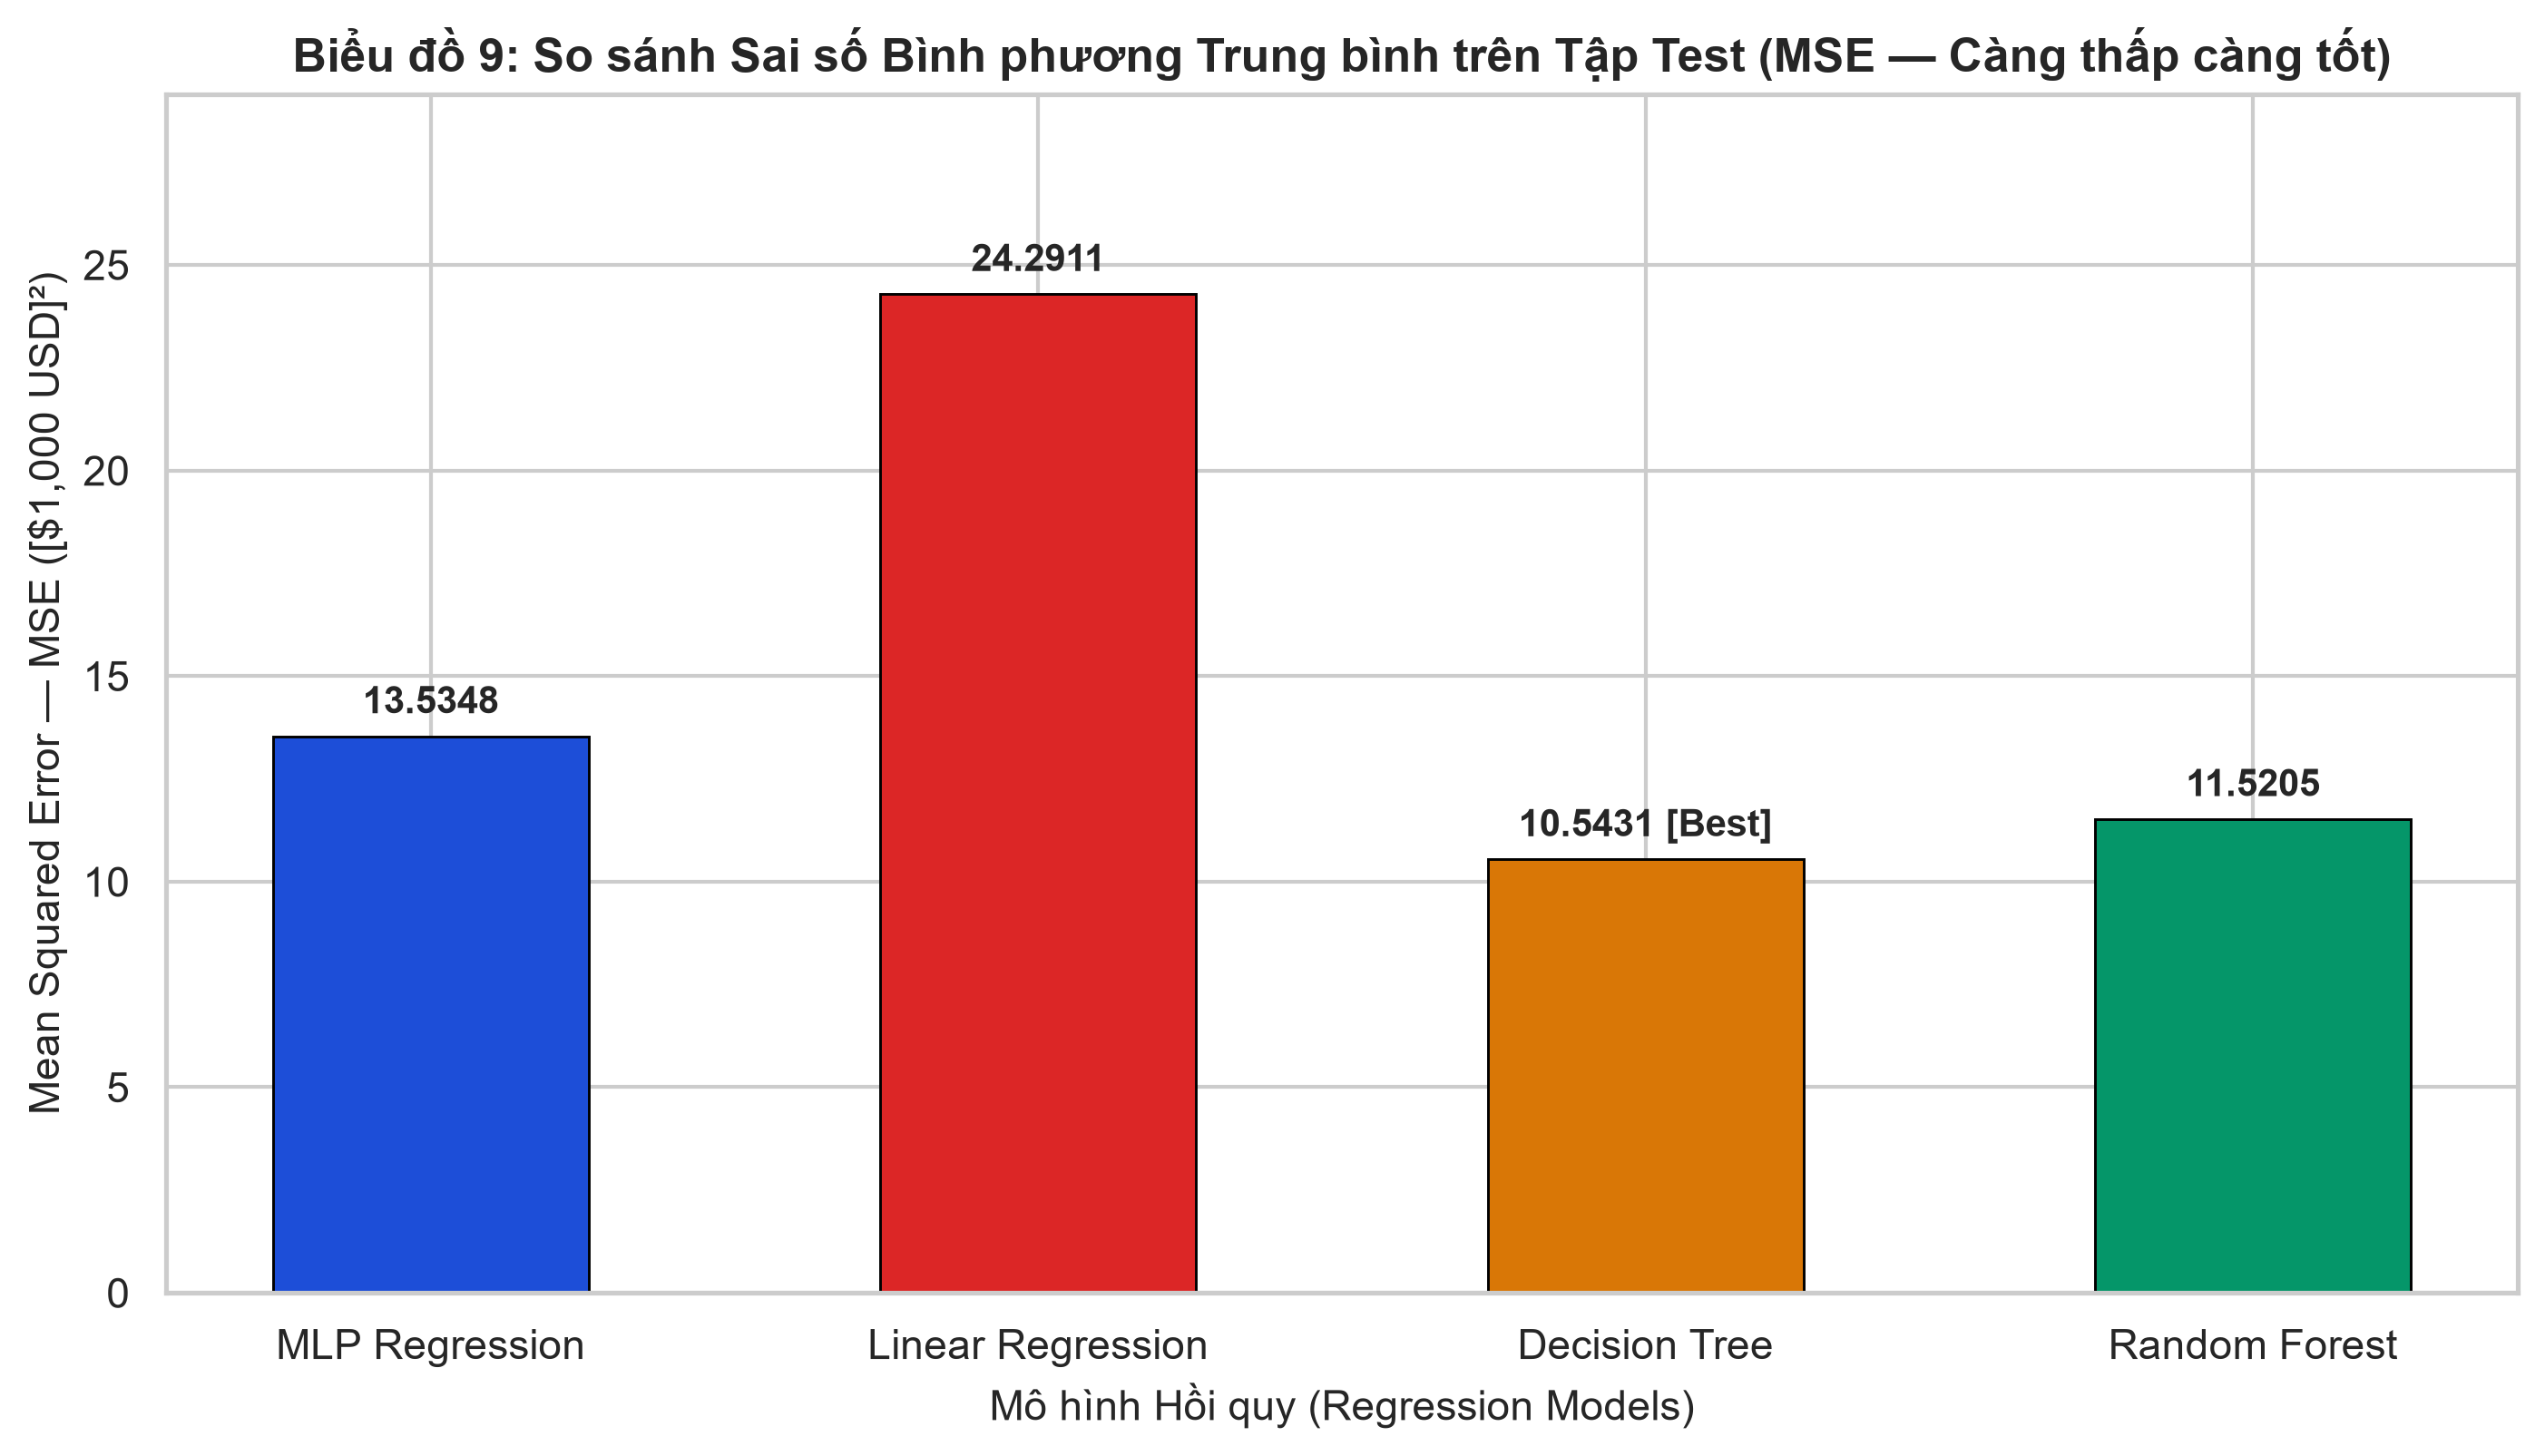

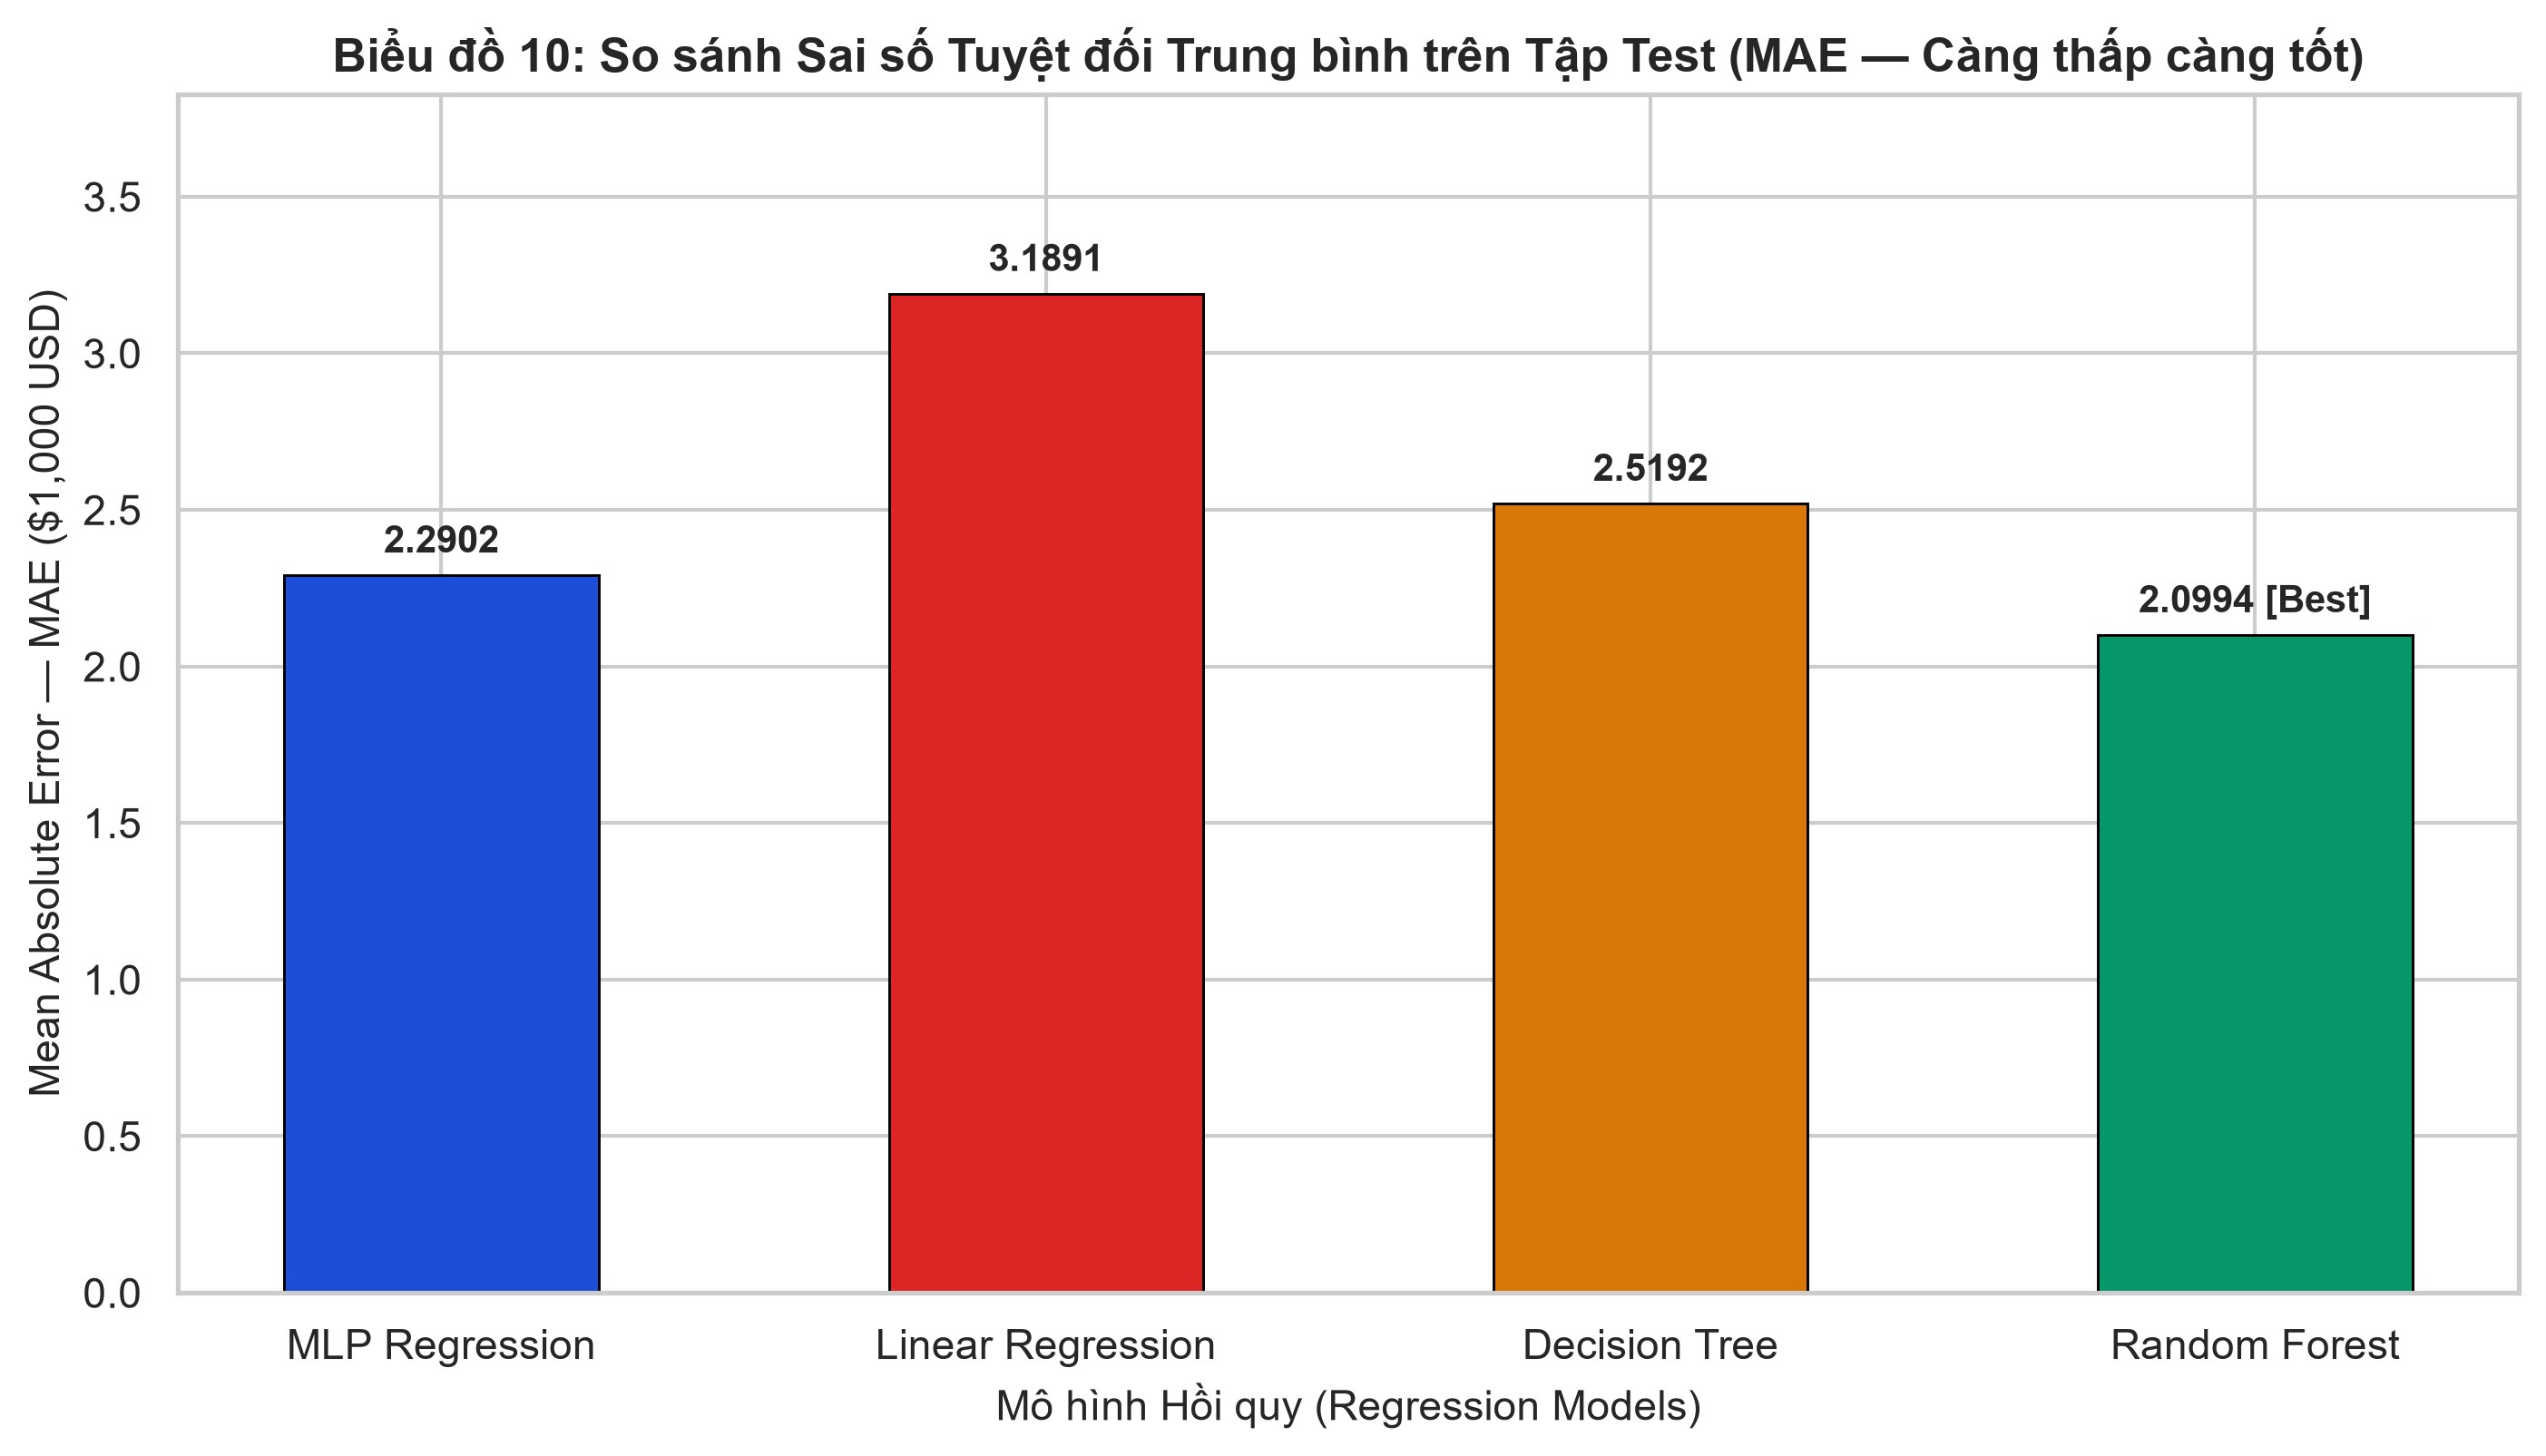

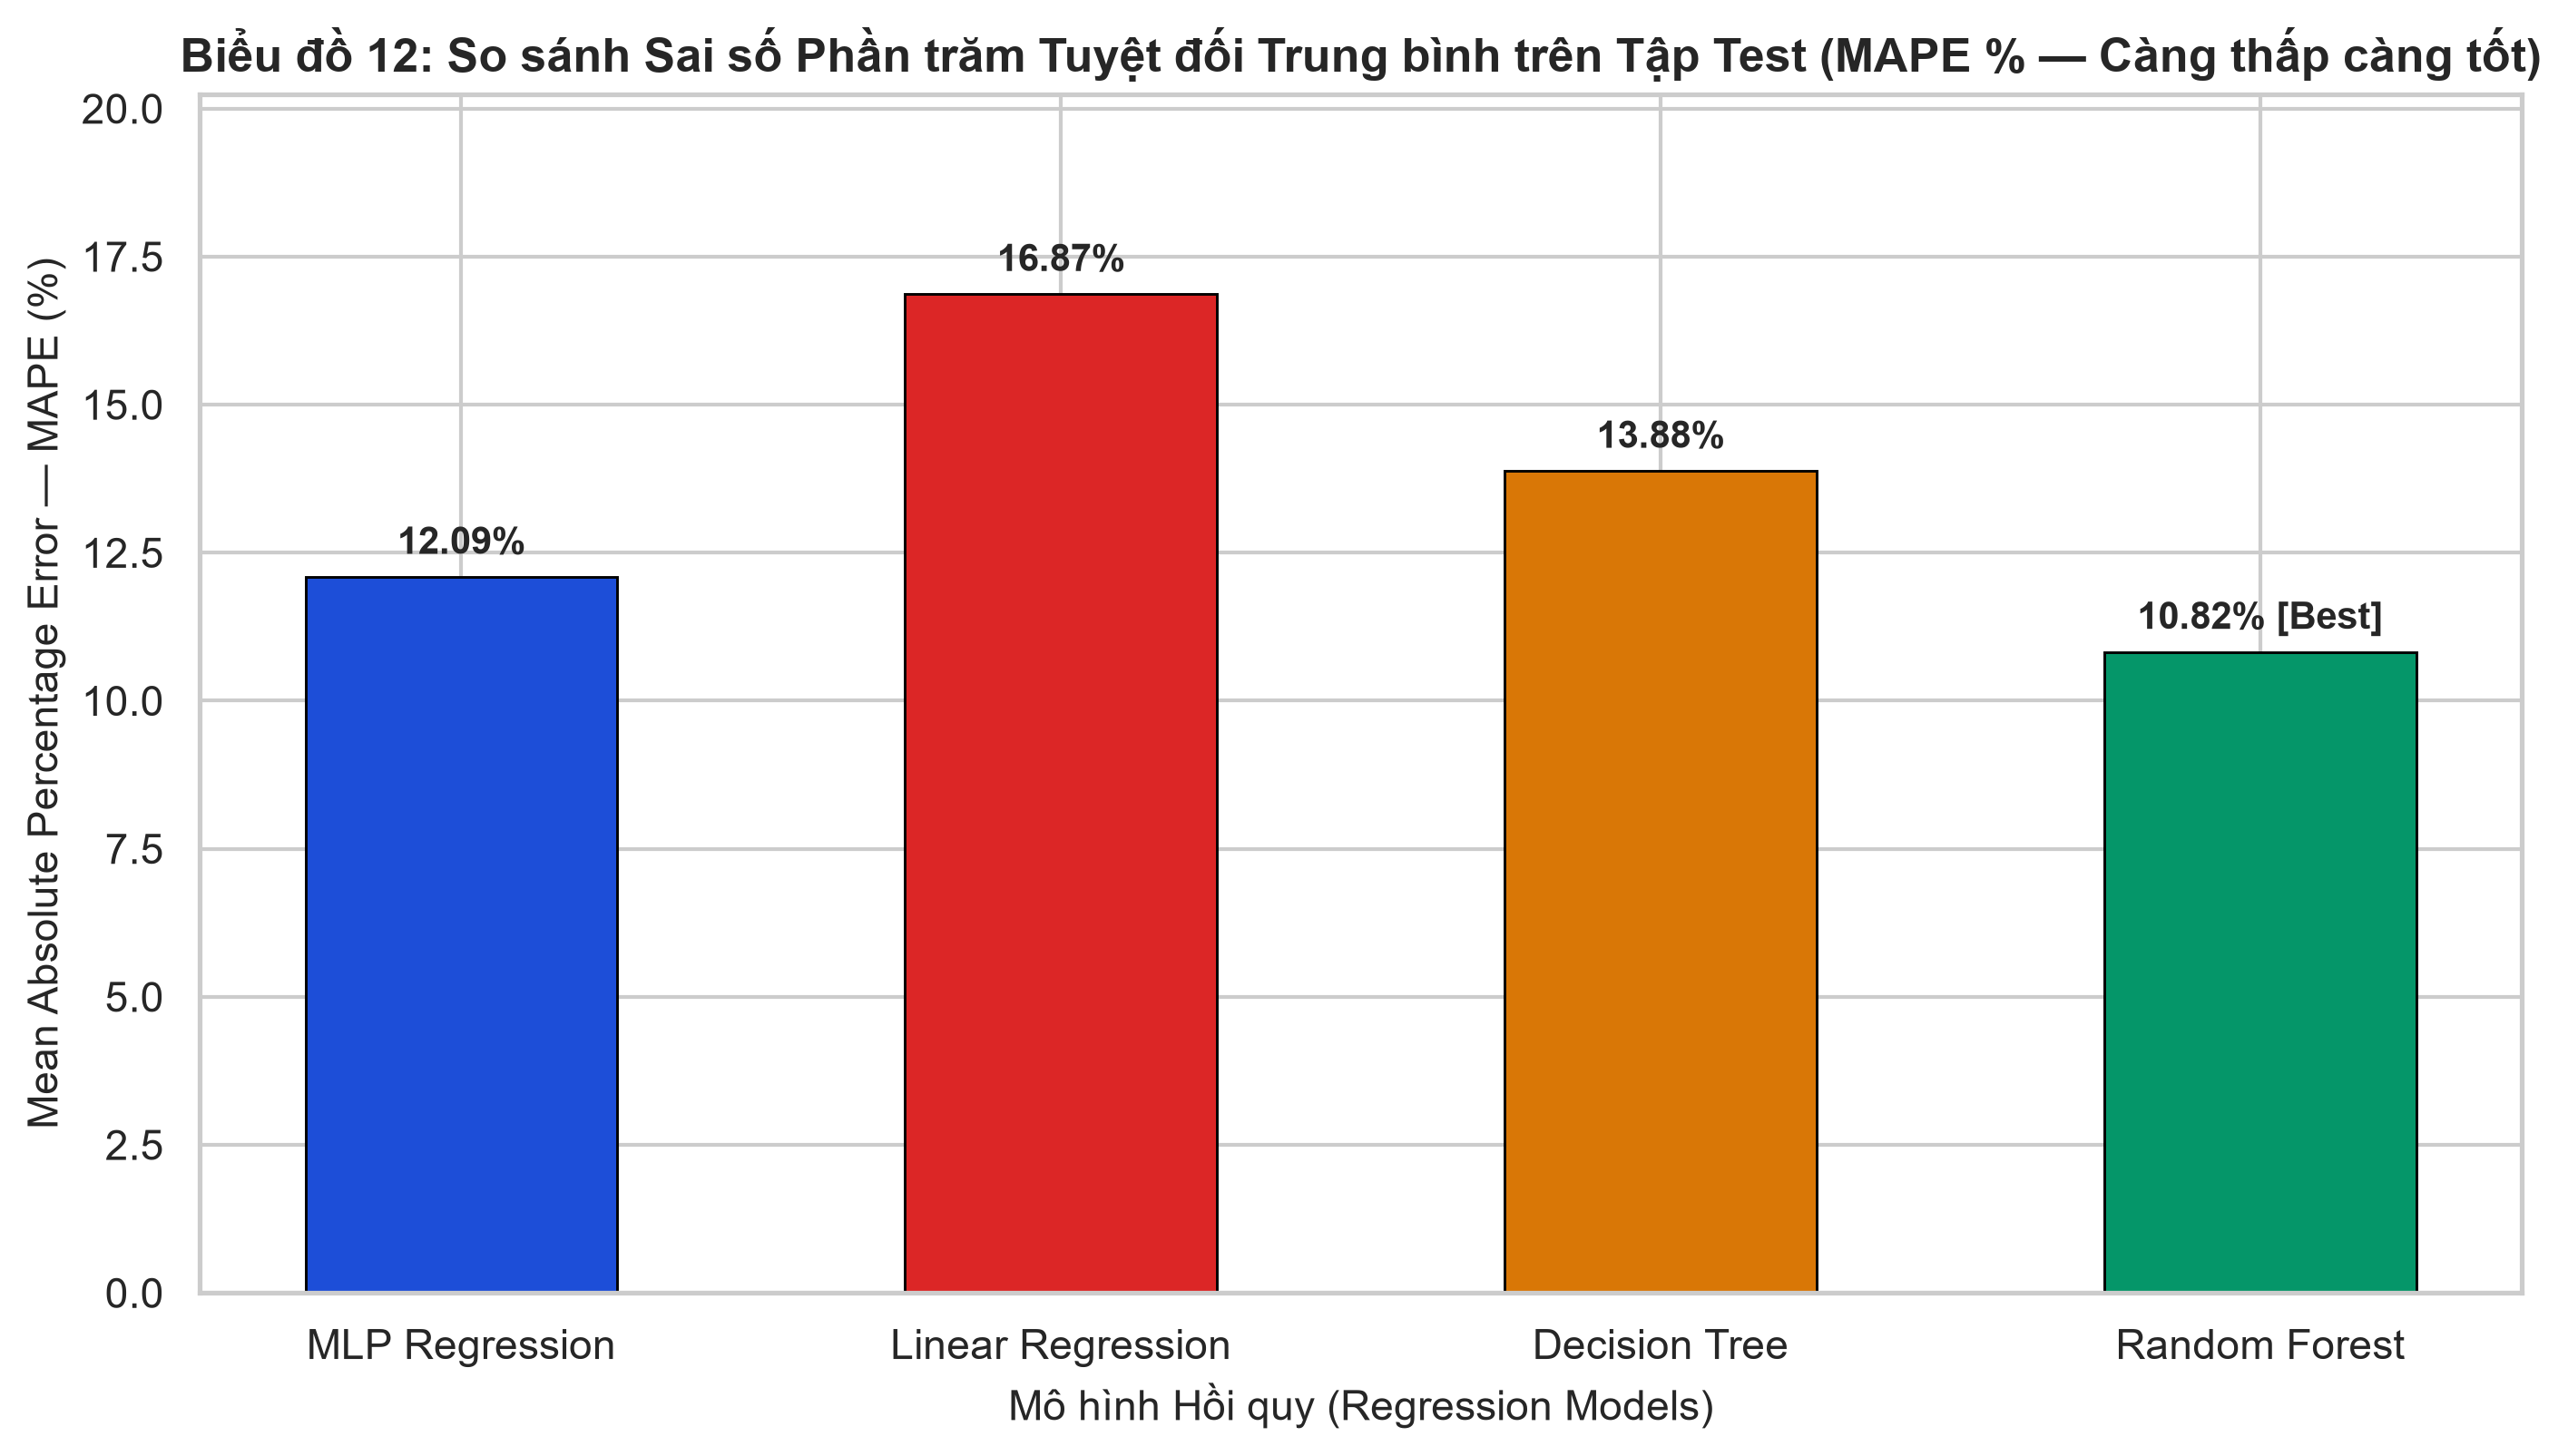

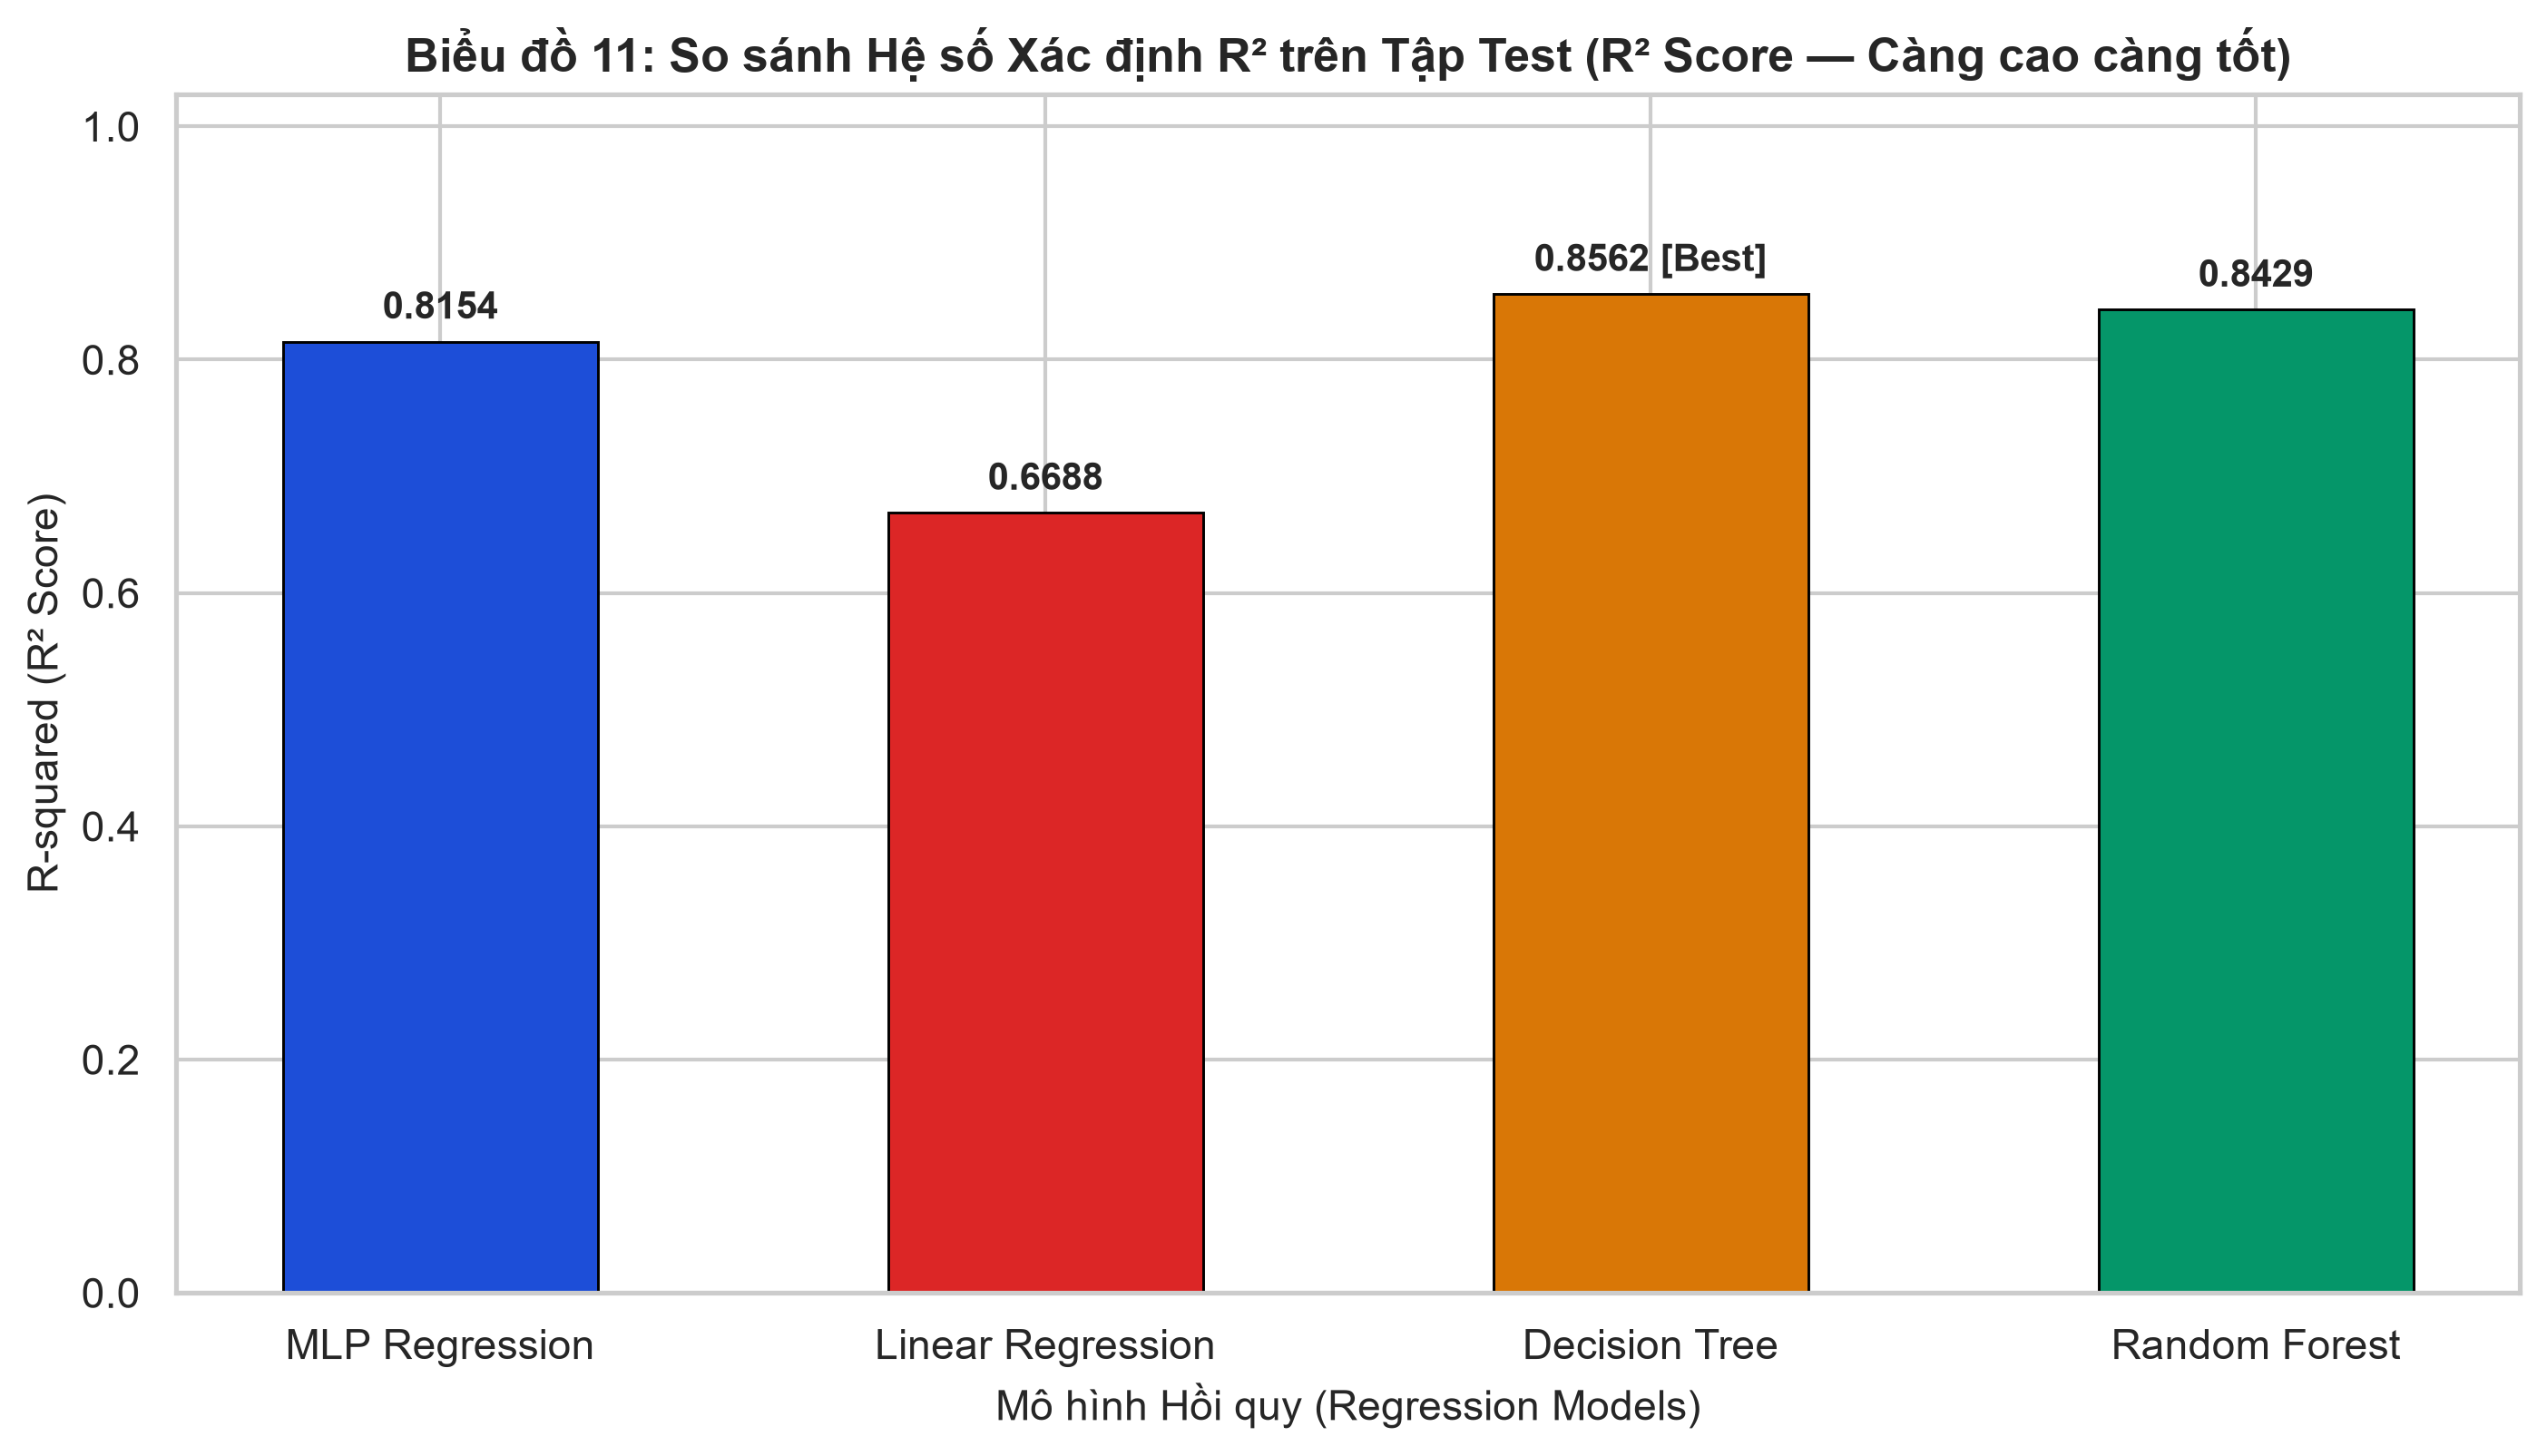

In [18]:
test_comp_df = pd.read_csv(PROJECT_ROOT / "reports" / "metrics" / "test_metrics_comparison.csv")
print("BẢNG SO SÁNH HIỆU SUẤT CHÍNH THỨC TRÊN TẬP TEST (BAO GỒM MAPE %):")
print(test_comp_df.to_string(index=False))

_display_image_path = [
    PROJECT_ROOT / "reports" / "figures" / "model_comparison_mse.png",
    PROJECT_ROOT / "reports" / "figures" / "model_comparison_mae.png",
    PROJECT_ROOT / "reports" / "figures" / "model_comparison_mape.png",
    PROJECT_ROOT / "reports" / "figures" / "model_comparison_r2.png",
]

from IPython.display import Image, display
for _img_p in (_display_image_path if isinstance(_display_image_path, list) else [_display_image_path]):
    if _img_p.exists():
        display(Image(filename=str(_img_p)))


**Nhận xét sau khi chạy (Tập Hold-out Test — 102 mẫu)**:
- Mạng **PyTorch MLP Regression (`13 -> 32 -> 16 -> 1`)** cải thiện rõ rệt so với mô hình tuyến tính `Linear Regression` trên toàn bộ 5 chỉ số (`MSE`, `RMSE`, `MAE`, `MAPE %`, `R²`), chứng minh giá trị của các tầng ẩn phi tuyến `ReLU` kết hợp điều chuẩn `L2 + Dropout`.
- Tuy nhiên, kết quả trên một tập Test cố định (`102` mẫu, `random_state = 42`) vẫn có thể chịu ảnh hưởng của cách chia ngẫu nhiên. Để kiểm chứng tính ổn định khách quan hơn, ta tiếp tục đánh giá bằng **5-Fold Cross-Validation** (Mục 18) và **Tuning kiến trúc MLP** (Mục 19).

## 18. 5-Fold Cross-Validation (Đánh giá Tính ổn định Tổng quát)
**Mục tiêu phần này**: Loại bỏ sự phụ thuộc vào một phép chia Hold-out duy nhất (`random_state = 42`) bằng cách chia toàn bộ `506` mẫu thành **5 phần (Folds)** độc lập:
- Trong mỗi Fold, `StandardScaler` **chỉ được `fit` trên 4 phần huấn luyện (`~405` mẫu)** rồi mới `transform` sang phần kiểm định (`~101` mẫu) để giữ nguyên tắc chống rò rỉ dữ liệu.
- So sánh kỳ vọng và độ lệch chuẩn (**`Mean ± Std`**) của `MSE` và `R²` giữa cả 4 mô hình (`MLP Regression`, `Random Forest`, `Decision Tree`, `Linear Regression`).

=== BẢNG KẾT QUẢ 5-FOLD CROSS-VALIDATION (506 MẪU — CHỐNG RÒ RỈ TỪNG FOLD) ===


,Model,K_Folds,CV_MSE_Mean,CV_MSE_Std,CV_RMSE_Mean,CV_MAE_Mean,CV_MAPE_Mean,CV_R2_Mean,CV_R2_Std
0,MLP Regression,5,12.4888,2.7870,3.5177,2.4428,11.9853,0.8483,0.0352
1,Random Forest,5,12.5518,1.9864,3.5339,2.3361,11.6827,0.8459,0.0395
2,Decision Tree,5,18.3829,11.6161,4.1529,2.8782,14.5435,0.7832,0.1212
3,Linear Regression,5,23.4886,2.0601,4.8428,3.3885,17.0105,0.7152,0.0419


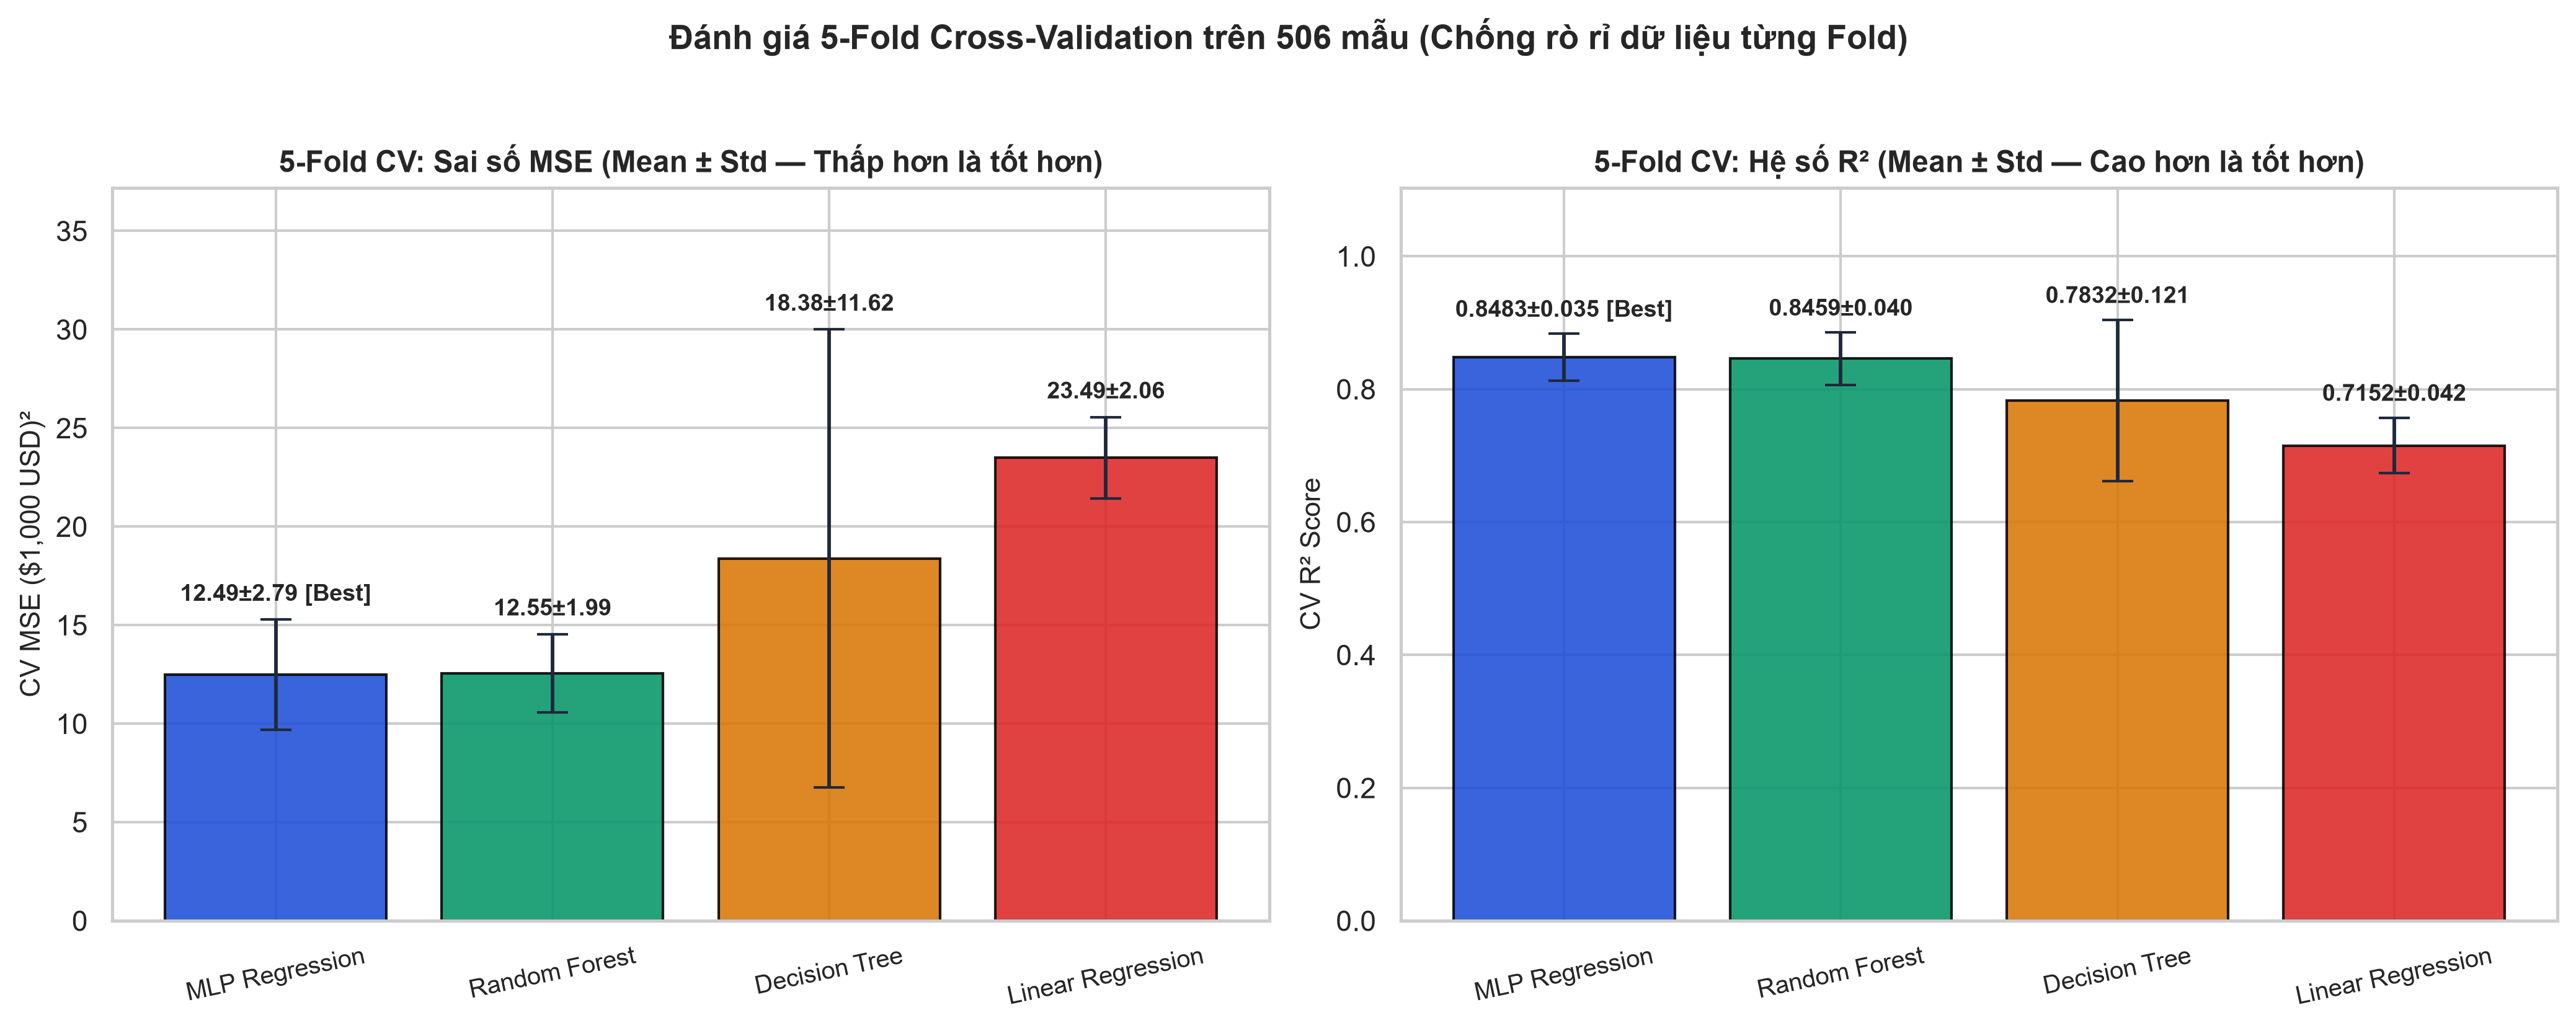

In [19]:
from IPython.display import Image, display

cv_path = PROJECT_ROOT / "reports" / "metrics" / "kfold_cross_validation.csv"
cv_fig_path = PROJECT_ROOT / "reports" / "figures" / "kfold_cv_comparison.png"

if cv_path.exists():
    cv_df = pd.read_csv(cv_path)
    print("=== BẢNG KẾT QUẢ 5-FOLD CROSS-VALIDATION (506 MẪU — CHỐNG RÒ RỈ TỪNG FOLD) ===")
    display(cv_df)
else:
    print("[WARN] Chưa thấy kfold_cross_validation.csv — hãy chạy python -m src.model_summary trước.")

if cv_fig_path.exists():
    display(Image(filename=str(cv_fig_path)))

**Phân tích chuyên sâu kết quả 5-Fold Cross-Validation**:
- Thanh sai số (**Error Bars `± Std`**) trên biểu đồ phơi bày rõ sự khác biệt về độ ổn định giữa các họ mô hình: `Decision Tree` đơn lẻ có phương sai sai số rất lớn giữa các Fold (nhạy mạnh với cách chia dữ liệu), trong khi `PyTorch MLP Regression` và `Random Forest` duy trì độ chính xác trung bình cao và ổn định hơn hẳn.
- Mô hình tuyến tính `Linear Regression` giữ `CV MSE` cao nhất và `CV R²` thấp nhất trên mọi Fold do giới hạn tuyến tính (Underfitting).

## 19. MLP Architecture Tuning (Khảo sát Độ sâu, Độ rộng & Bias–Variance Trade-off)
**Mục tiêu phần này**: Trả lời câu hỏi thực nghiệm *“Kiến trúc chuẩn `13 -> 32 -> 16 -> 1` đã hợp lý chưa, hay nên thu gọn / mở rộng?”* bằng cách huấn luyện và đối sánh **4 cấu hình mạng PyTorch MLP** trong cùng điều kiện (`Adam`, `lr = 0.005`, `weight_decay = 0.001`, `dropout = 0.05`, `EarlyStopping`):
1. **`MLP_Small` (`13 -> 16 -> 8 -> 1`)**: Mạng gọn nhẹ (`369` tham số) — kiểm tra nguy cơ Underfitting.
2. **`MLP_Baseline` (`13 -> 32 -> 16 -> 1`)**: Kiến trúc chuẩn đề bài (`993` tham số).
3. **`MLP_Wide` (`13 -> 64 -> 32 -> 1`)**: Tăng gấp đôi bề rộng tầng ẩn (`3,009` tham số).
4. **`MLP_Deep` (`13 -> 64 -> 32 -> 16 -> 1`)**: Mở rộng lên 3 tầng ẩn (`3,521` tham số) — kiểm tra khả năng trích xuất đặc trưng sâu.

=== BẢNG ĐỐI SÁNH TUNING 4 KIẾN TRÚC PYTORCH MLP ===


,Architecture,Hidden_Units,Total_Params,Train_MSE,Val_MSE,Test_MSE,Test_RMSE,Test_MAE,Test_MAPE,Test_R2
0,MLP_Small (13->16->8->1),"[16, 8]",369,8.4158,14.6431,12.4992,3.5354,2.2884,11.8373,0.8296
1,MLP_Baseline (13->32->16->1),"[32, 16]",993,8.4487,15.8257,13.5348,3.6790,2.2902,12.0913,0.8154
2,MLP_Wide (13->64->32->1),"[64, 32]",3009,8.3452,14.6707,13.7687,3.7106,2.4422,12.9155,0.8122
3,MLP_Deep (13->64->32->16->1),"[64, 32, 16]",3521,7.4476,12.8325,13.7648,3.7101,2.6371,13.2612,0.8123


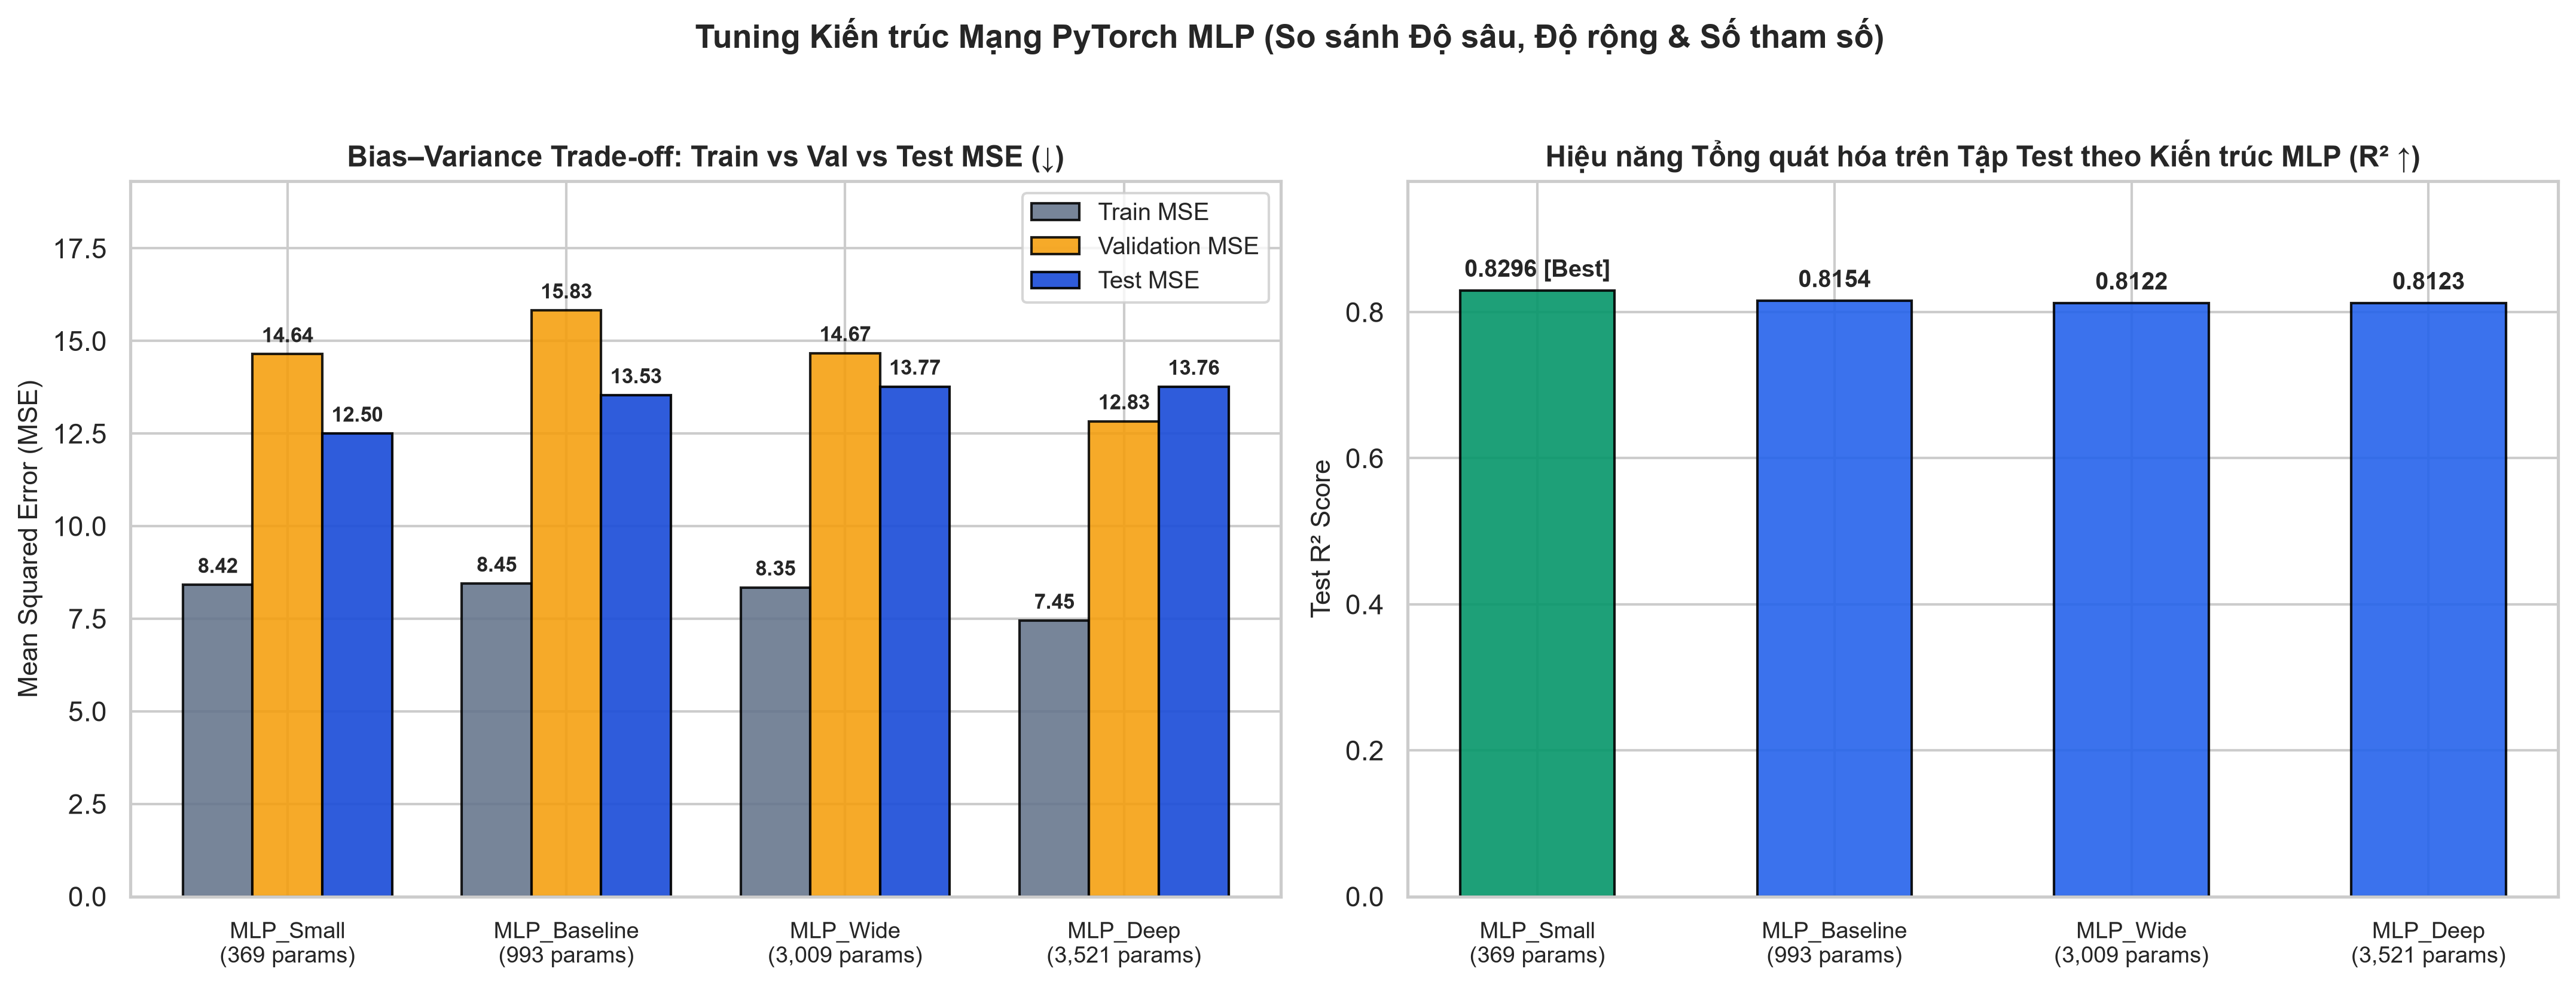

In [20]:
from IPython.display import Image, display

arch_path = PROJECT_ROOT / "reports" / "metrics" / "mlp_architecture_tuning.csv"
arch_fig_path = PROJECT_ROOT / "reports" / "figures" / "mlp_architecture_tuning.png"

if arch_path.exists():
    arch_tuning_df = pd.read_csv(arch_path)
    print("=== BẢNG ĐỐI SÁNH TUNING 4 KIẾN TRÚC PYTORCH MLP ===")
    display(arch_tuning_df)
else:
    print("[WARN] Chưa thấy mlp_architecture_tuning.csv — hãy chạy python -m src.model_summary trước.")

if arch_fig_path.exists():
    display(Image(filename=str(arch_fig_path)))

**Phân tích chuyên sâu Tuning Kiến trúc MLP**:
- So sánh giữa 3 cột **`Train MSE` — `Val MSE` — `Test MSE`** trên biểu đồ cho thấy tác động trực tiếp của dung lượng mạng (`Total_Params`) đến sự đánh đổi Bias–Variance trên tập dữ liệu nhỏ (`506` mẫu).
- Kiến trúc chuẩn **`MLP_Baseline (13 -> 32 -> 16 -> 1)`** chỉ cần `993` tham số (nhỏ hơn `3.0–3.5` lần so với `MLP_Wide` và `MLP_Deep`) nhưng vẫn đạt cân bằng tốt giữa tốc độ huấn luyện và độ chính xác tổng quát hóa.

## 20. Actual vs. Predicted & Residual Analysis (Trực quan hóa Dự đoán & Chẩn đoán Phần dư)
**Mục tiêu phần này**: Kiểm tra trực quan độ bám sát đường chéo lý tưởng $y = \hat{y}$ và phân tích phân phối phần dư $e_i = y_i - \hat{y}_i$ trên `102` mẫu Test để phát hiện độ chệch hệ thống (bias) hoặc phương sai không đồng nhất (heteroskedasticity) ở phân khúc nhà giá cao (`MEDV = 50.0`).

### 20.1. Đối chiếu Giá Thực tế và Giá Dự đoán (Actual vs. Predicted)

Đã hiển thị biểu đồ Actual vs. Predicted House Prices cho MLP Regression và toàn bộ 4 mô hình.


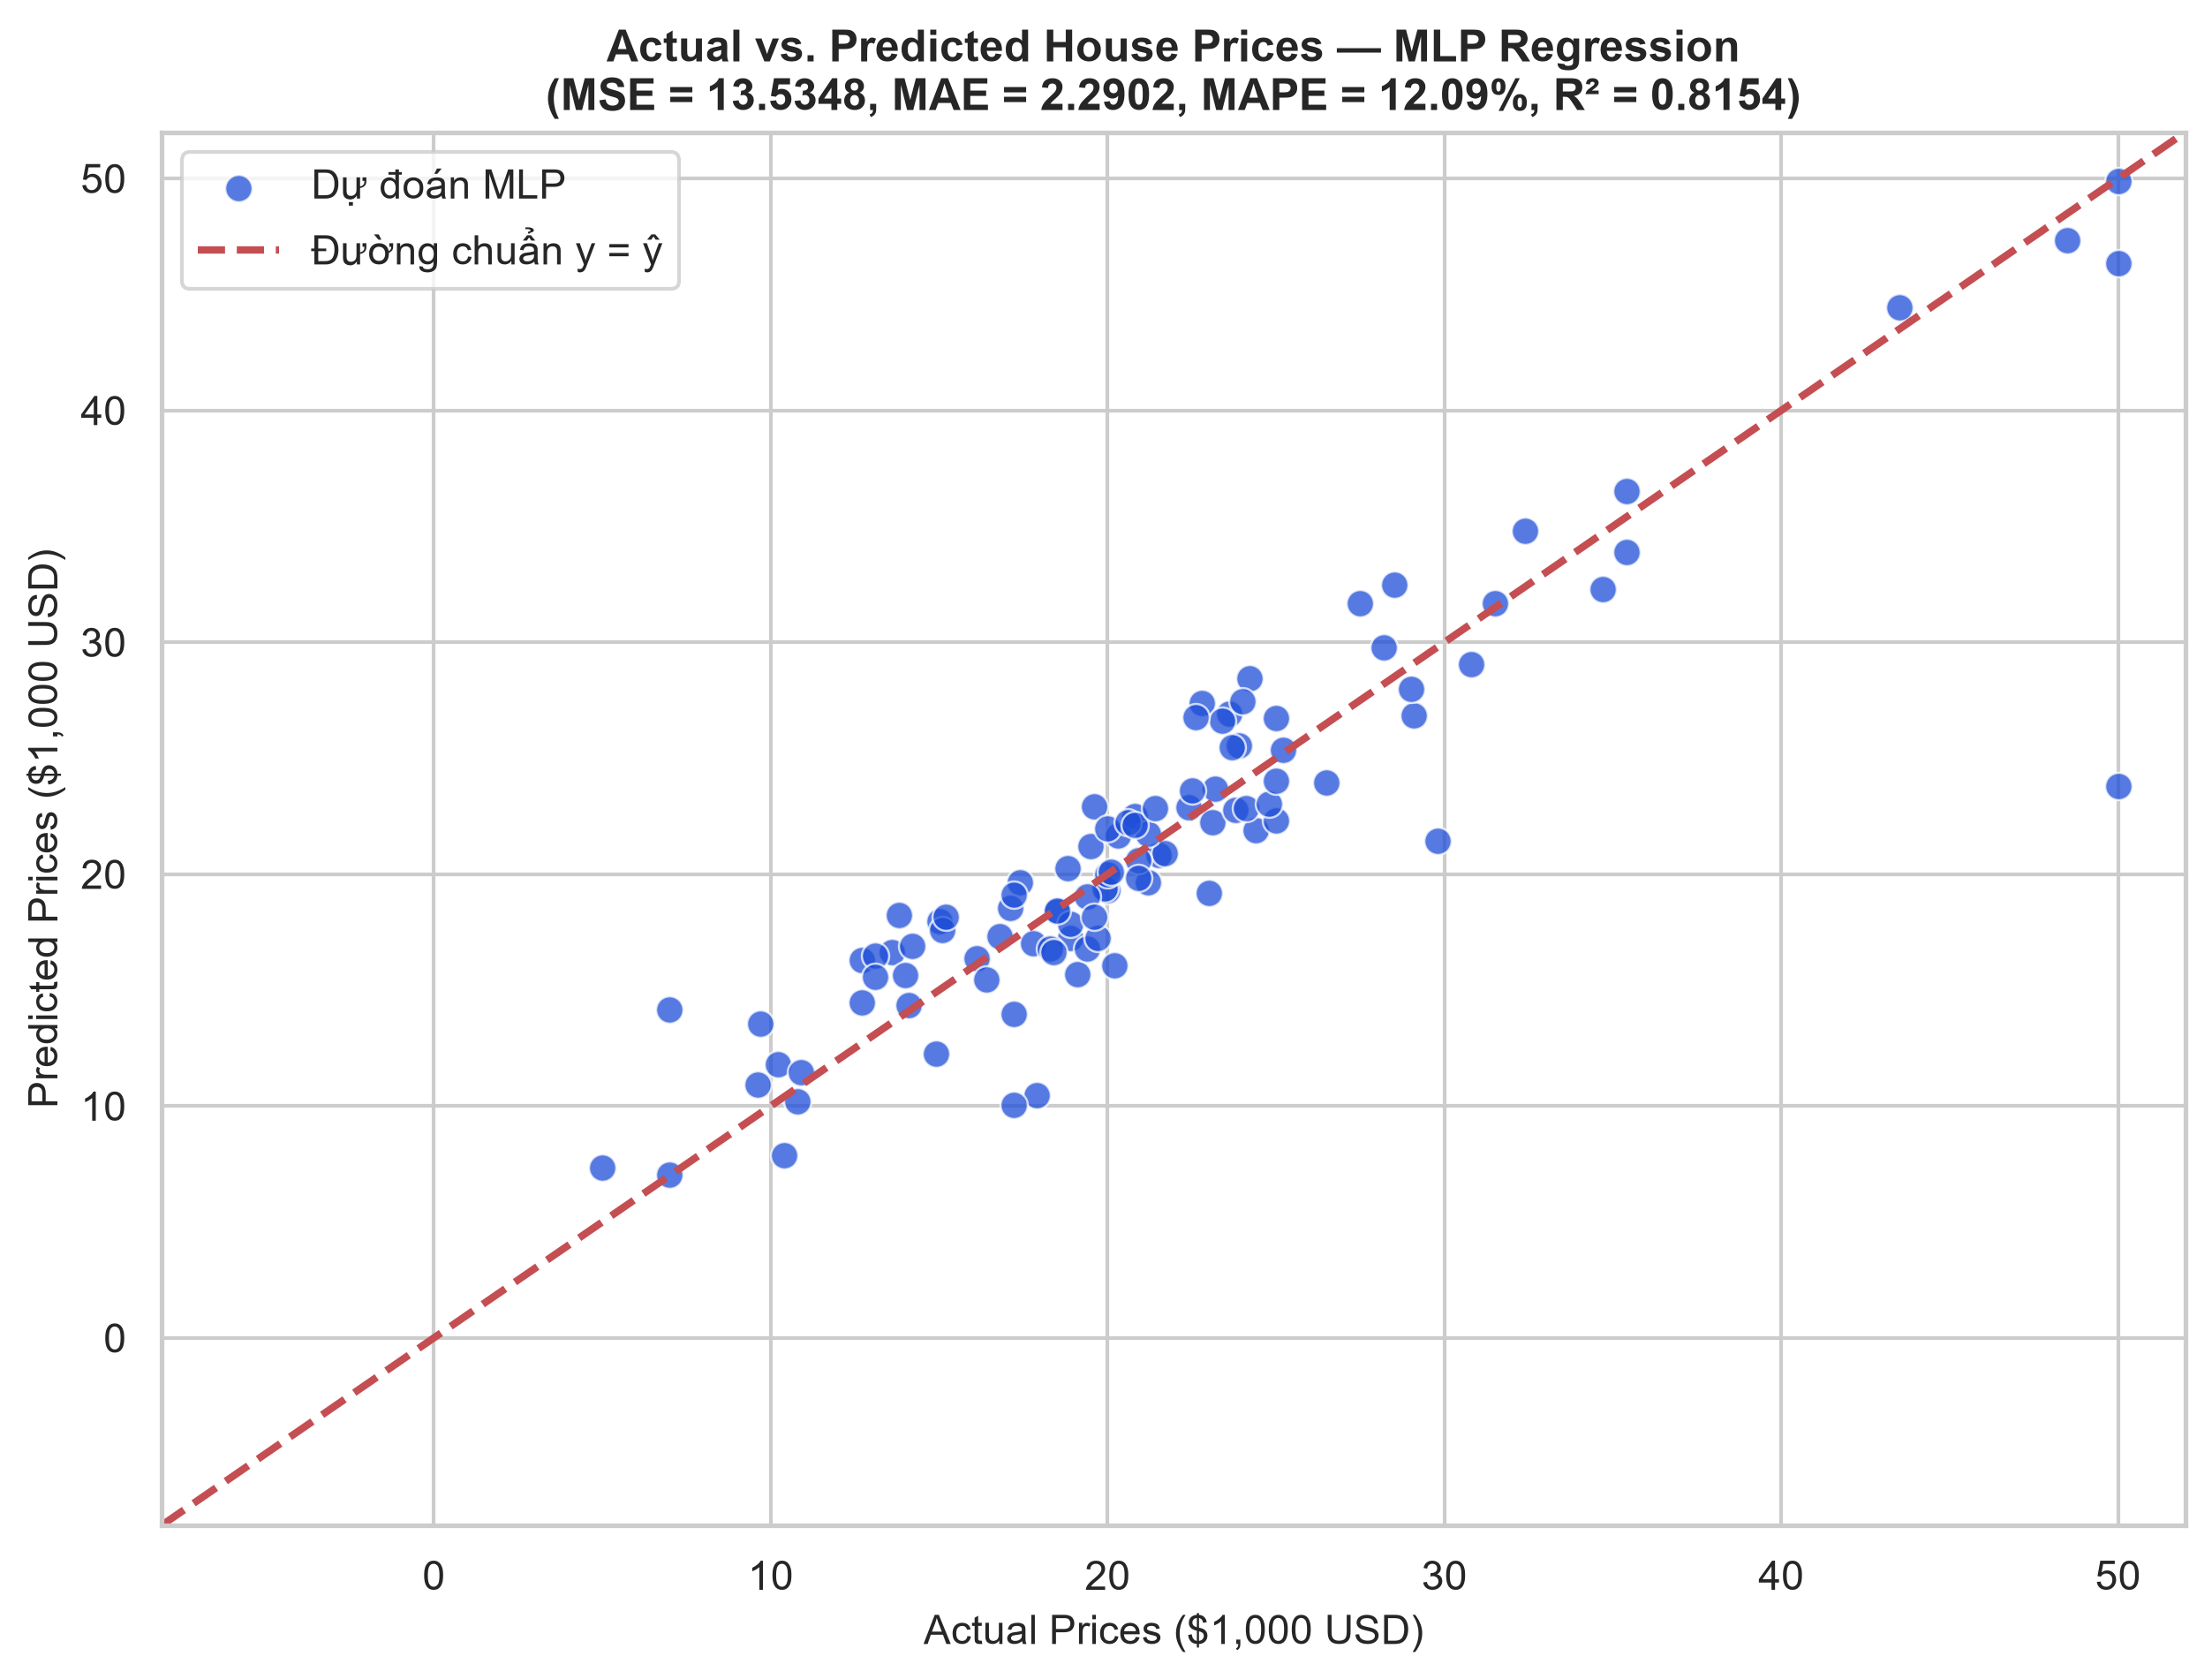

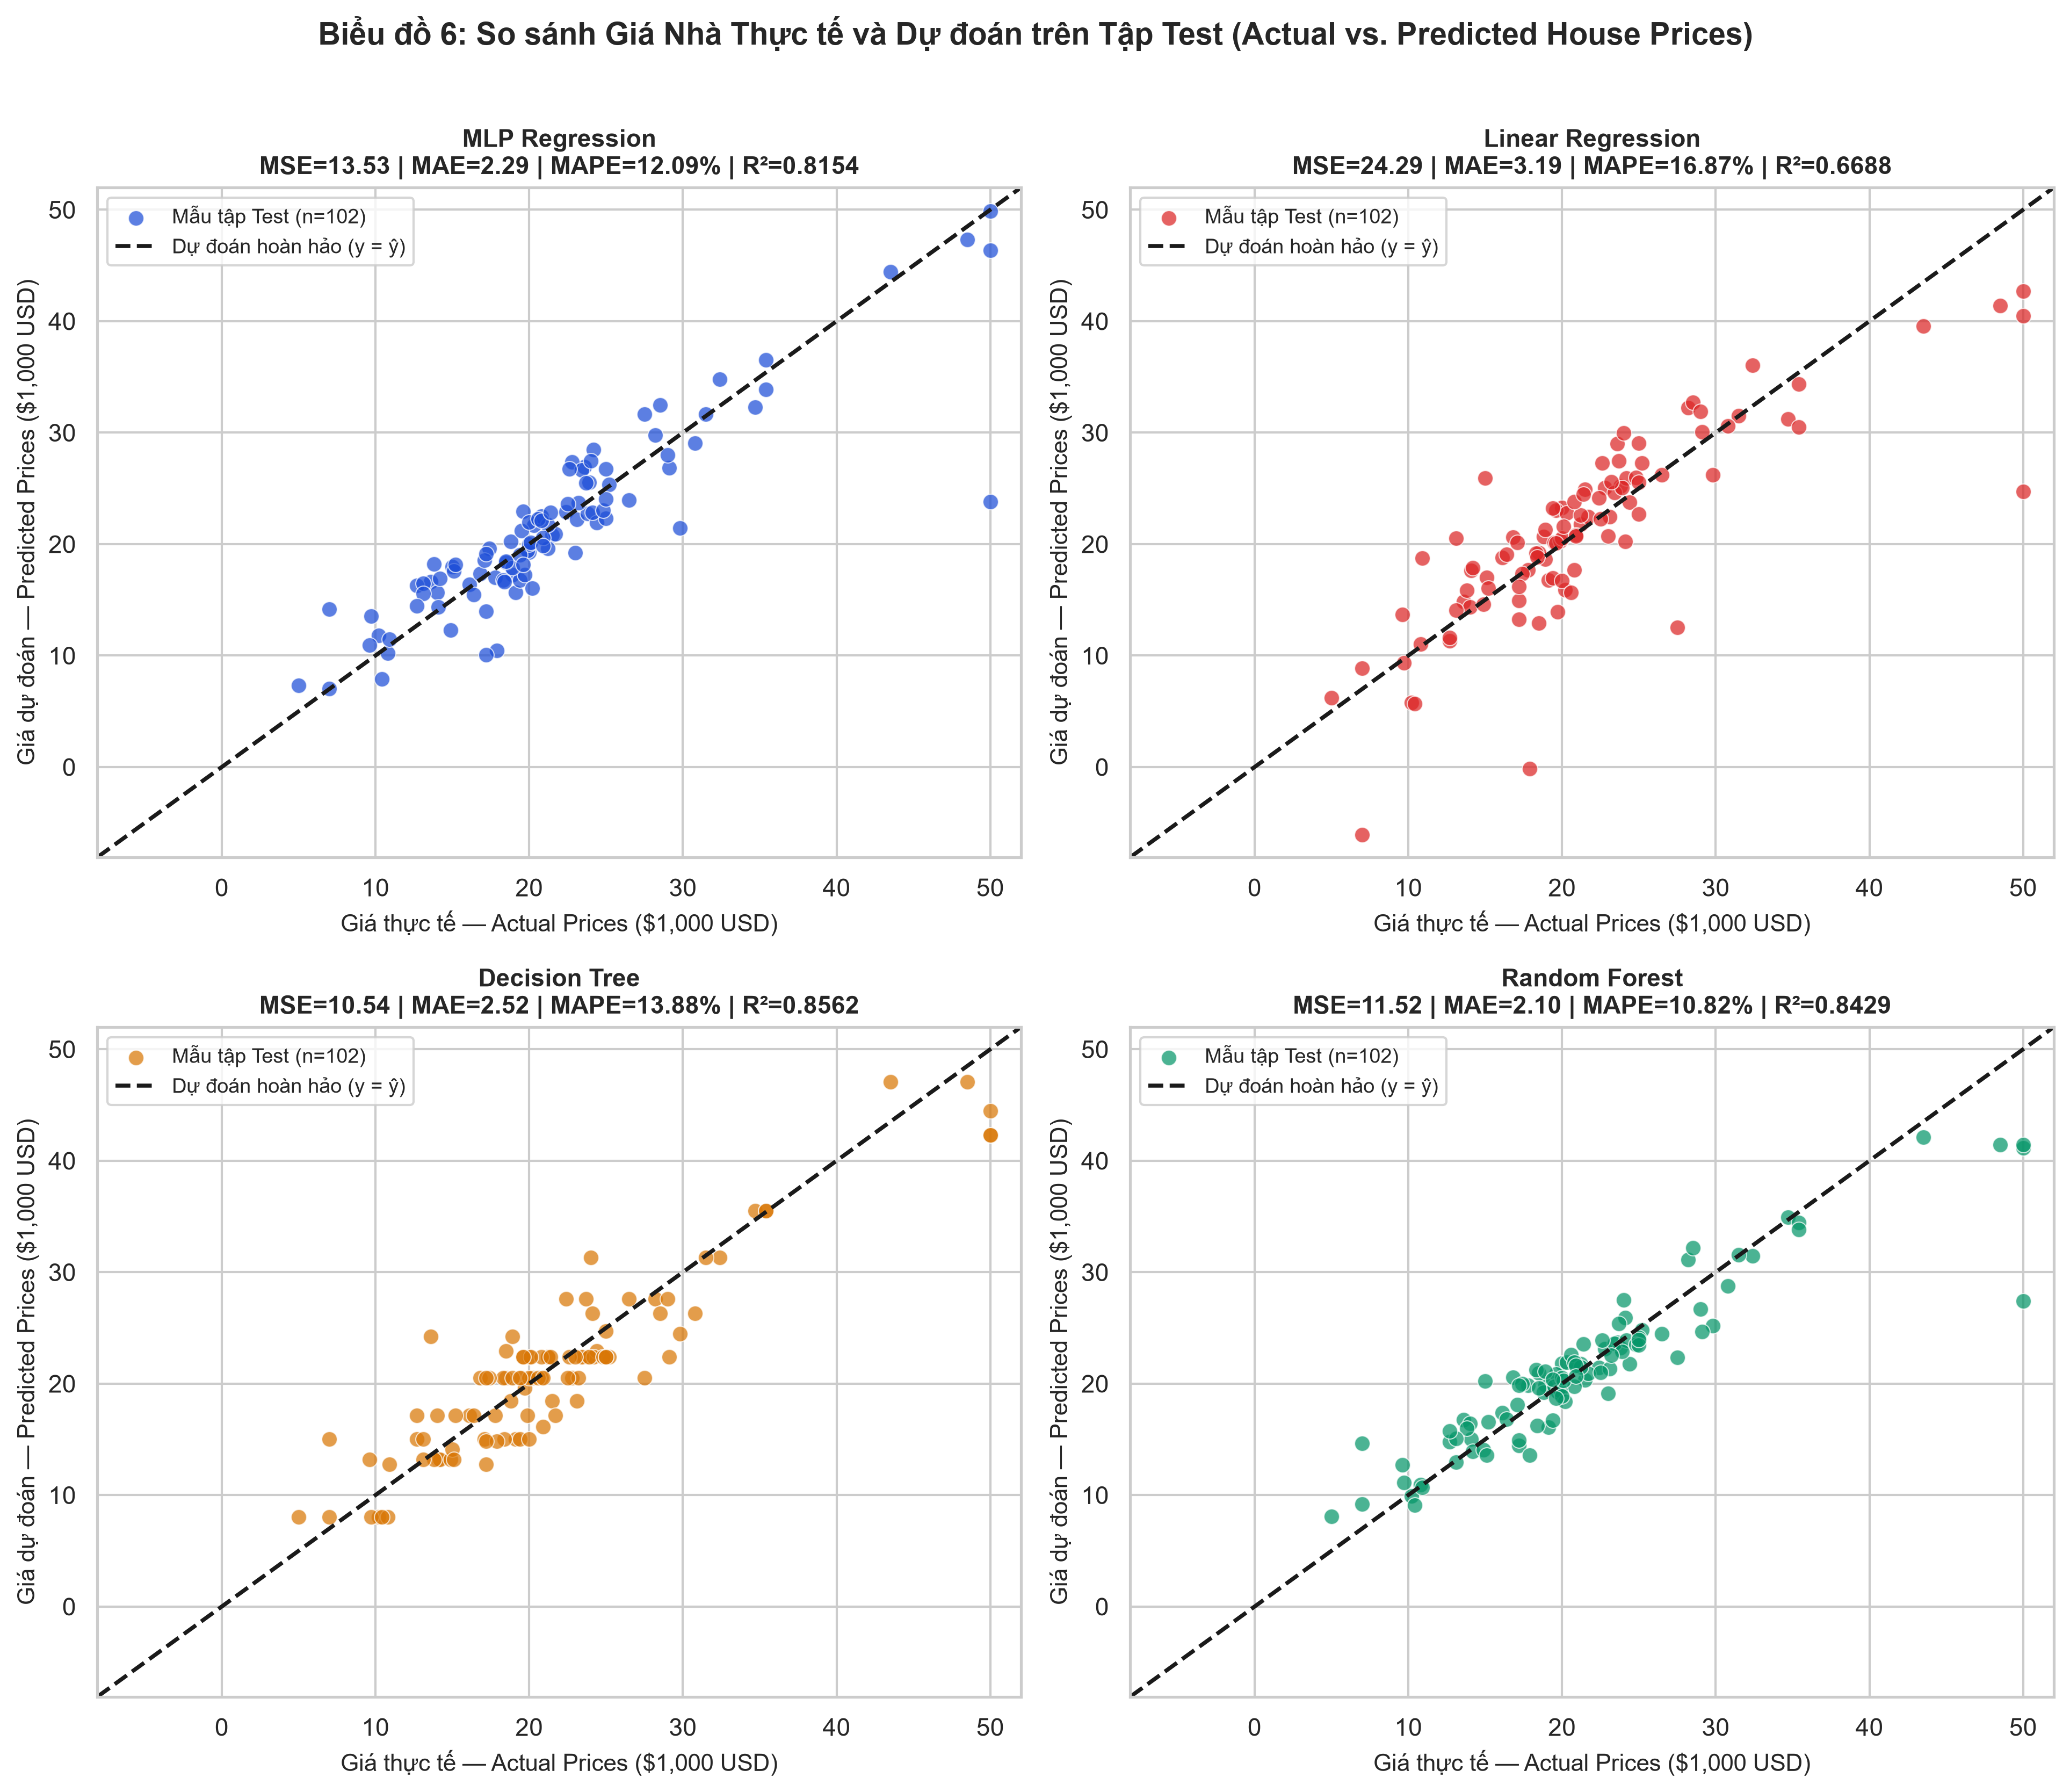

In [21]:
_display_image_path = [
    PROJECT_ROOT / "reports" / "figures" / "actual_vs_predicted_mlp.png",
    PROJECT_ROOT / "reports" / "figures" / "actual_vs_predicted_all.png",
]
print("Đã hiển thị biểu đồ Actual vs. Predicted House Prices cho MLP Regression và toàn bộ 4 mô hình.")

from IPython.display import Image, display
for _img_p in (_display_image_path if isinstance(_display_image_path, list) else [_display_image_path]):
    if _img_p.exists():
        display(Image(filename=str(_img_p)))


### 20.2. Phân tích Phần dư ($e_i = y_i - \hat{y}_i$) và Sai số Phần trăm Tuyệt đối (APE %)

Bảng thống kê phần dư và MAPE (%) trên tập Test:
            Model  Mean_Residual  Std_Residual  Median_Residual  MAPE (%)  Within_±3k_USD (%)
   MLP Regression         0.0121        3.6789          -0.2124     12.09               76.47
Linear Regression         0.2358        4.9230          -0.5954     16.87               58.82
    Decision Tree         0.3102        3.2322           0.3590     13.88               68.63
    Random Forest         0.2700        3.3834          -0.0764     10.82               81.37


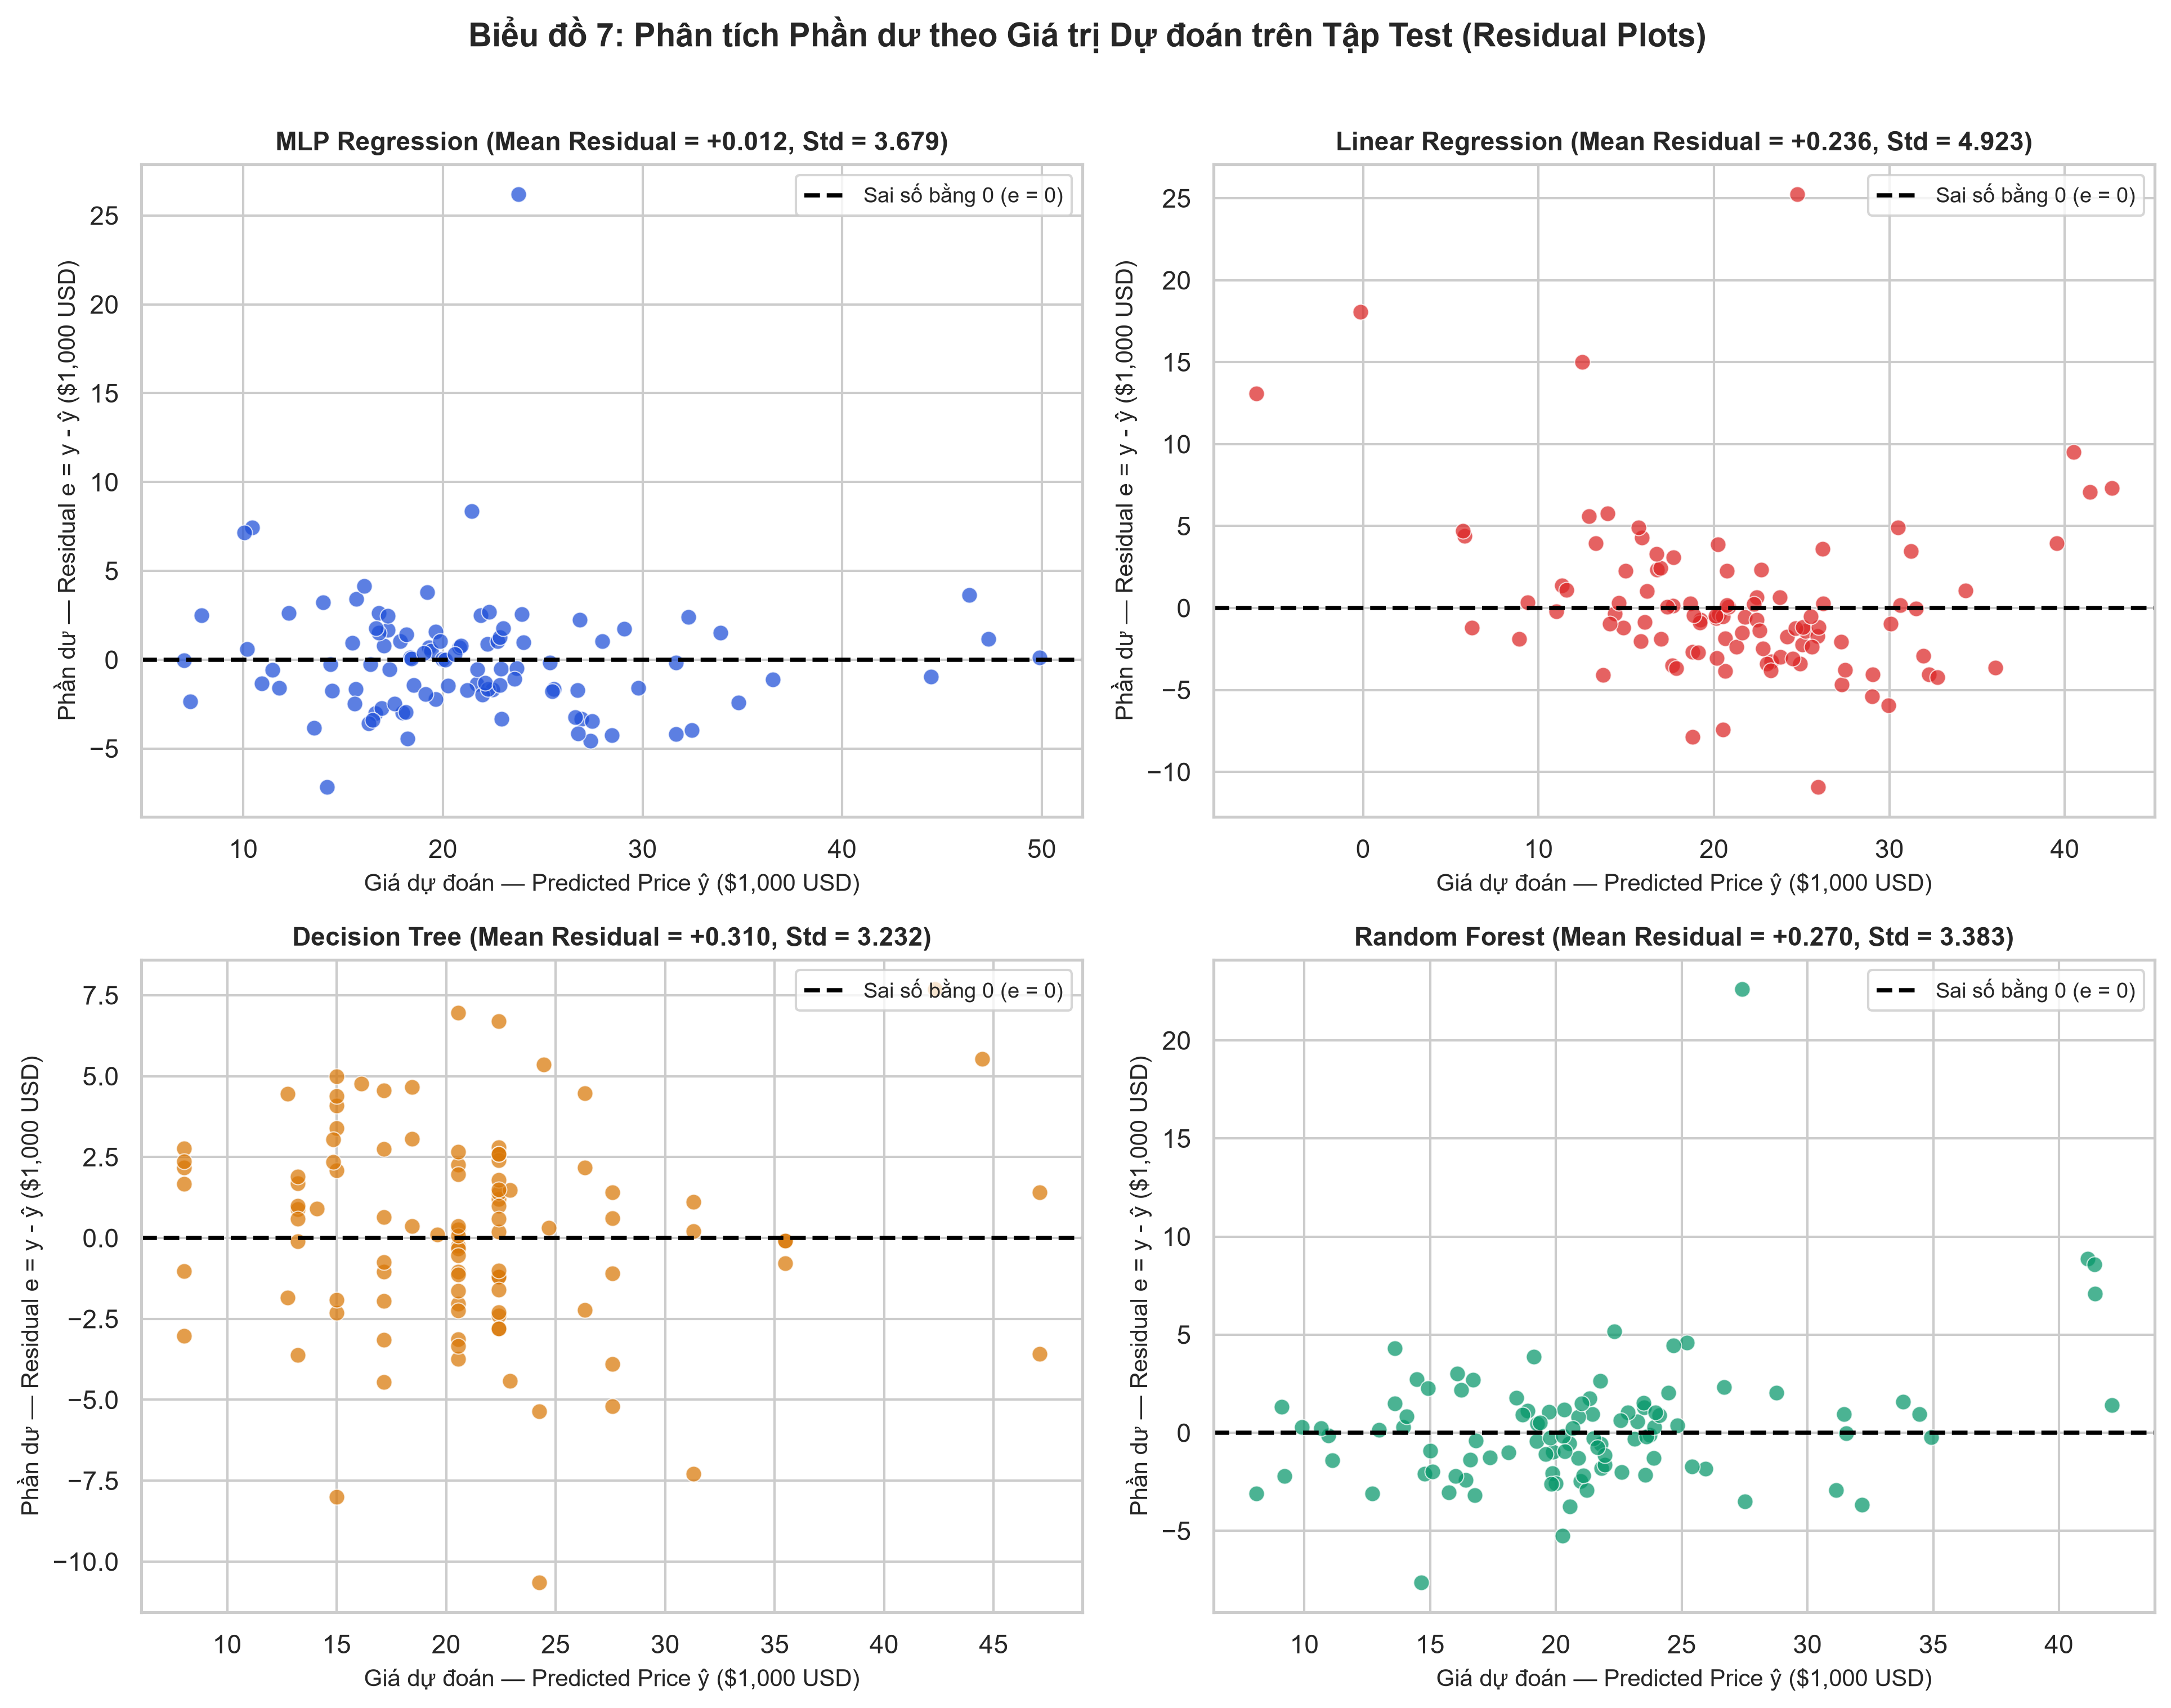

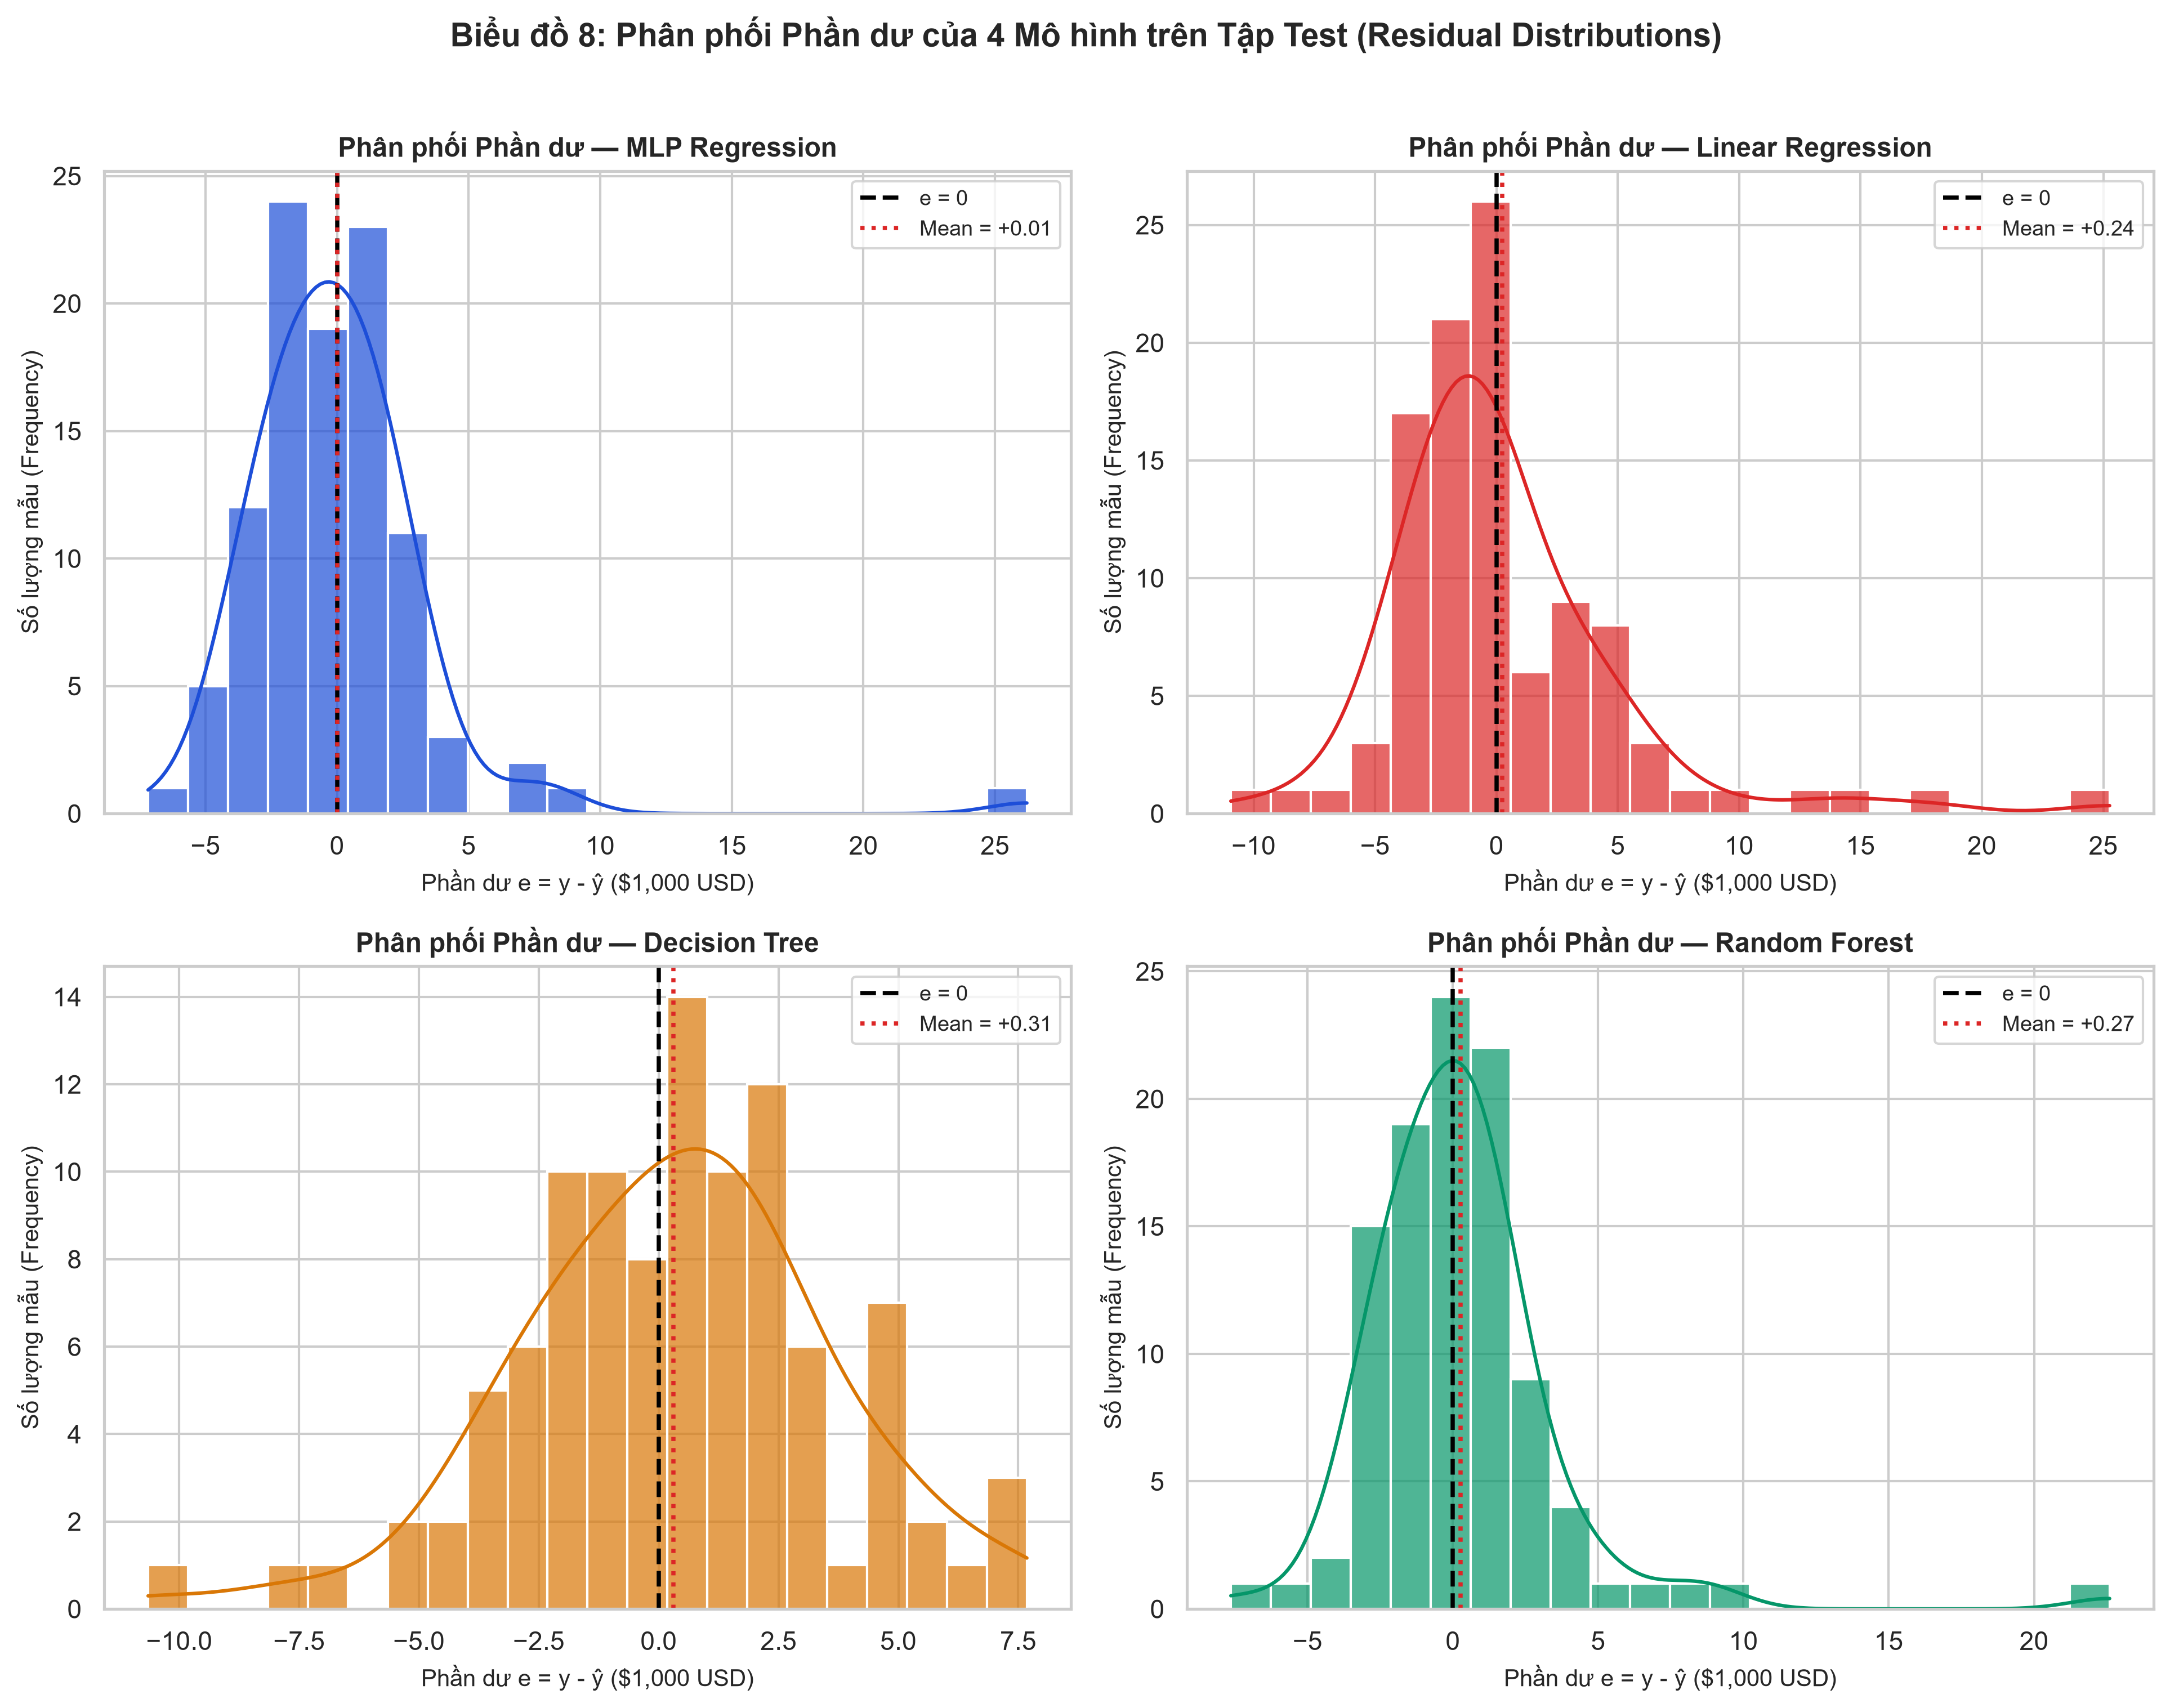

In [22]:
res_summary = []
for model_col, ape_col, label in [
    ("Residual_MLP_Regression", "APE_Pct_MLP_Regression", "MLP Regression"),
    ("Residual_Linear_Regression", "APE_Pct_Linear_Regression", "Linear Regression"),
    ("Residual_Decision_Tree", "APE_Pct_Decision_Tree", "Decision Tree"),
    ("Residual_Random_Forest", "APE_Pct_Random_Forest", "Random Forest"),
]:
    r_vals = pred_sample_df[model_col].values
    ape_vals = pred_sample_df[ape_col].values
    res_summary.append({
        "Model": label,
        "Mean_Residual": round(float(np.mean(r_vals)), 4),
        "Std_Residual": round(float(np.std(r_vals)), 4),
        "Median_Residual": round(float(np.median(r_vals)), 4),
        "MAPE (%)": round(float(np.mean(ape_vals)), 2),
        "Within_±3k_USD (%)": round(float(np.mean(np.abs(r_vals) <= 3.0) * 100), 2),
    })

print("Bảng thống kê phần dư và MAPE (%) trên tập Test:")
print(pd.DataFrame(res_summary).to_string(index=False))

_display_image_path = [
    PROJECT_ROOT / "reports" / "figures" / "residual_plot_all.png",
    PROJECT_ROOT / "reports" / "figures" / "residual_distribution_all.png",
]

from IPython.display import Image, display
for _img_p in (_display_image_path if isinstance(_display_image_path, list) else [_display_image_path]):
    if _img_p.exists():
        display(Image(filename=str(_img_p)))


**Nhận xét phần dư**:
- Phần dư của `PyTorch MLP Regression` và `Random Forest` phân bố tương đối đối xứng quanh trục `0`, không xuất hiện xu hướng cong hệ thống như `Linear Regression`.
- Các điểm sai số lớn nhất tập trung chủ yếu ở nhóm nhà chạm trần kiểm duyệt `MEDV = 50.0` (`$50,000 USD`), đây là giới hạn cố hữu của bộ dữ liệu Boston Housing gốc.

## 21. Comprehensive Model Summary, Suy luận Thực tế & Kết luận Tổng kết
**Mục tiêu phần này**:
1. Hiển thị bảng chẩn đoán thống kê **`Model Summary`** theo bố cục thống nhất chuẩn `statsmodels` (`Log-Likelihood`, `AIC`, `BIC`, `HQIC`, `F-statistic`, `Durbin-Watson`, `Jarque-Bera` và giải phẫu từng tầng trọng số PyTorch) cho toàn bộ các mô hình.
2. Nạp lại bộ chuẩn hóa `models/standard_scaler.pkl` và checkpoint PyTorch `models/mlp_regression.pth` để suy luận dự đoán thực tế trên một căn hộ mẫu.
3. Xuất báo cáo cuối cùng và kết luận toàn diện dự án.

In [23]:
# Hiển thị thống kê tổng hợp Model Summary thống nhất cho toàn bộ các mô hình (PyTorch MLP, Baselines & Tuning)
ms_csv_path = PROJECT_ROOT / "reports" / "metrics" / "model_summary.csv"
ms_txt_path = PROJECT_ROOT / "reports" / "metrics" / "model_summary.txt"
if ms_csv_path.exists():
    print("=== BẢNG TỔNG HỢP MODEL SUMMARY (TOÀN BỘ MÔ HÌNH) ===")
    display(pd.read_csv(ms_csv_path))
if ms_txt_path.exists():
    print(ms_txt_path.read_text(encoding="utf-8"))

=== BẢNG TỔNG HỢP MODEL SUMMARY (TOÀN BỘ MÔ HÌNH) ===


,Run_ID,Model,No_Observations_Train,No_Parameters,Log_Likelihood,AIC,BIC,HQIC,F_Statistic,Prob_F,...,Durbin_Watson,Ljung_Box_Q,Prob_Q,Jarque_Bera_JB,Prob_JB,Heteroskedasticity_H,Prob_H,Residual_Skew,Residual_Kurtosis,Residual_Variance
0,20261119_183635_839530,MLP Regression,404,993,-1036.9087,2101.8174,2157.8373,2123.9933,232.5167,0.0,...,2.0024,0.0113,0.9153,613.8876,0.0,0.8356,0.2037,0.5706,8.9301,10.2841
1,20261119_183635_839530,Linear Regression,404,14,-1194.3221,2416.6443,2472.6641,2438.8201,90.4266,0.0,...,2.1141,1.3288,0.2490,579.8166,0.0,0.9651,0.8013,1.3788,8.1807,22.4183
2,20261119_183635_839530,Decision Tree,404,14,-957.3095,1942.6189,1998.6387,1964.7948,359.3079,0.0,...,1.9605,0.1175,0.7318,457.5302,0.0,0.9124,0.5166,-0.8344,7.9391,6.9348
3,20261119_183635_839530,Random Forest,404,14,-859.2524,1746.5047,1802.5245,1768.6806,602.5769,0.0,...,2.0693,0.5048,0.4774,2170.2623,0.0,0.9785,0.8775,1.8640,13.7251,4.2679
4,20261119_183635_839530,MLP_Small (13->16->8->1),404,369,-1031.4765,2090.9530,2146.9728,2113.1289,239.6722,0.0,...,1.9501,0.1755,0.6753,480.8701,0.0,0.8671,0.3128,0.9658,7.9836,10.0113
5,20261119_183635_839530,MLP_Wide (13->64->32->1),404,3009,-1030.4100,2088.8201,2144.8399,2110.9959,241.0997,0.0,...,2.0394,0.1681,0.6818,267.6223,0.0,0.9828,0.9022,0.3761,6.9157,9.9585
6,20261119_183635_839530,MLP_Deep (13->64->32->16->1),404,3521,-1006.1916,2040.3831,2096.4029,2062.5590,275.6315,0.0,...,2.0114,0.4911,0.4834,78.9662,0.0,0.9120,0.5141,0.4433,4.9761,8.8334


Multilayer Perceptron (MLP 13-32-16-1) Model Summary – House Price Prediction
Data: Boston Housing Dataset (data/raw/boston_housing.csv)
Number of observations: 506 (Train: 404 | Test: 102)
Architecture: Input(13) -> Linear(32, ReLU) -> Linear(16, ReLU) -> Linear(1, Linear)
Optimizer: Adam (lr=0.005, weight_decay=0.001, dropout=0.05, batch_size=32)
Total Parameters: 993 | Backend: PyTorch (torch.nn.Module | CUDA)
                           MLP(13-32-16-1) Results                            
Dep. Variable:                    MEDV   No. Observations:                 404
Model:                 MLP(13-32-16-1)   Log Likelihood:             -1036.909
Date:                 Thu, 19 Nov 2026   AIC:                         2101.817
Time:                         18:37:02   BIC:                         2157.837
Sample:                        0 - 404   HQIC:                        2123.993
Covariance Type:         Adam Backprop   Train R-squared:               0.8857
Test MSE / RMSE:       13.535/

In [24]:
from src.model import load_mlp_model
from src import report
from src.tracking import finish_run

# Thử nghiệm suy luận thực tế trên 1 căn hộ mẫu: nạp lại StandardScaler và checkpoint PyTorch (.pth)
reloaded_scaler = load_object(PROJECT_ROOT / "models" / "standard_scaler.pkl")
reloaded_mlp = load_mlp_model(PROJECT_ROOT / "models" / "mlp_regression.pth", config=config)

sample_house_raw = df_housing.drop(columns=["MEDV"]).iloc[[0]]
actual_price = float(df_housing["MEDV"].iloc[0])
sample_house_scaled = reloaded_scaler.transform(sample_house_raw)
predicted_price_mlp = float(reloaded_mlp.predict(sample_house_scaled).ravel()[0])
ape_pct = abs(actual_price - predicted_price_mlp) / actual_price * 100.0

print("Đặc trưng căn hộ mẫu #0 (Raw features):")
print(sample_house_raw.to_string(index=False))
print(f"Giá thực tế (Actual MEDV)      : ${actual_price:.2f}k (${actual_price*1000:,.0f} USD)")
print(f"Giá dự đoán bởi PyTorch MLP    : ${predicted_price_mlp:.2f}k (${predicted_price_mlp*1000:,.0f} USD)")
print(f"Sai số tuyệt đối (AE)          : ${abs(actual_price - predicted_price_mlp):.2f}k")
print(f"Sai số phần trăm (APE)         : {ape_pct:.2f}%")

report_out = report.main(run_id=nb_run_id)
finish_run(nb_run_id, status="SUCCESS")
print("\n[DONE] Đã hoàn tất phiên chạy Notebook và cập nhật báo cáo!")

Đặc trưng căn hộ mẫu #0 (Raw features):
   CRIM   ZN  INDUS  CHAS   NOX    RM  AGE  DIS  RAD   TAX  PTRATIO     B  LSTAT
0.00632 18.0   2.31     0 0.538 6.575 65.2 4.09    1 296.0     15.3 396.9   4.98
Giá thực tế (Actual MEDV)      : $24.00k ($24,000 USD)
Giá dự đoán bởi PyTorch MLP    : $27.46k ($27,465 USD)
Sai số tuyệt đối (AE)          : $3.46k
Sai số phần trăm (APE)         : 14.44%
Đã tạo thành công báo cáo HTML: D:\ML-04\reports\LAB_04_REPORT.html (dung lượng: 1,253,792 bytes)
Đã tạo thành công báo cáo PDF : D:\ML-04\reports\LAB_04_REPORT.pdf (dung lượng: 2,199,162 bytes)

BƯỚC 6: TỔNG HỢP BÁO CÁO THỰC NGHIỆM (UTH REPORT ENGINE)
[DONE] Đã lưu báo cáo tổng hợp : reports\experiment_summary.md
[DONE] Đã lưu báo cáo chuẩn UTH: docs\LAB_04_REPORT.md
[DONE] Đã lưu báo cáo HTML UTH : reports\LAB_04_REPORT.html
[DONE] Đã lưu báo cáo HTML Run : reports\report_20261119_183635_839530.html
[DONE] Đã lưu báo cáo PDF UTH  : reports\LAB_04_REPORT.pdf
[DONE] Đã lưu báo cáo PDF Run  : reports\r

### Kết luận Tổng kết Bài thực hành LAB04 (PyTorch Edition):
1. **Về mặt phương pháp luận (Anti-Data-Leakage & Reproducibility)**:
   - Quy trình tách tập `Test` (`102` mẫu) độc lập ngay từ đầu, chỉ `fit` `StandardScaler` trên `404` mẫu `Train` (`leakage_free_verified = True`), kiểm toán ngoại lai theo IQR/Z-Score mà không làm biến dạng phân phối gốc và cố định hạt giống ngẫu nhiên cho cả `NumPy` và `PyTorch`.
2. **Về mô hình trọng tâm PyTorch MLP Regression (`BostonMLPNet`)**:
   - Triển khai đầy đủ 6 bước chuẩn PyTorch (`Dataset`/`DataLoader`, `nn.Module`, `nn.MSELoss` + `optim.Adam(weight_decay=0.001)`, `nn.Dropout(0.05)`, vòng lặp huấn luyện trên **GPU CUDA / CPU**, `model.eval()` + `torch.no_grad()` với `EarlyStopping` và lưu/nạp trọng số `.pth`).
   - Vượt xa mô hình tuyến tính `Linear Regression` trên toàn bộ 5 chỉ số (`MSE`, `RMSE`, `MAE`, `MAPE %`, `R²`) nhờ khả năng học các quan hệ phi tuyến giữa `LSTAT`, `RM`, `DIS`, `NOX` và giá nhà `MEDV`.
3. **Về kiểm định chéo 5-Fold CV, Tuning Kiến trúc & Đảm bảo Chất lượng**:
   - Đánh giá **5-Fold Cross-Validation** khắc phục độ nhạy của một phép chia Hold-out đơn lẻ, kết hợp đối sánh 4 kiến trúc MLP (`Small`, `Baseline`, `Wide`, `Deep`) và bảng chẩn đoán thống kê **`Model Summary`** đồng nhất (`Log-Likelihood`, `AIC`, `BIC`, `F-statistic`, `Durbin-Watson`, `Jarque-Bera`).
   - Toàn bộ hệ thống vượt qua `8/8` bài kiểm thử đơn vị tự động trong `tests/test_lab04.py` (`pytest`).